# 🛒 SmartCart: one photo of groceries → a priced receipt

One photo of a grocery counter goes in, and an itemised, priced receipt comes out. A **YOLO11n** detector, fine-tuned on synthetic multi-item scenes composed from GroceryStoreDataset photos, finds each product. Frozen **DINOv2-small** features plus a small **linear head** (exported to **ONNX**, fp32 and int8) name it among 81 classes. A **Gradio checkout app** prices the basket in SGD with promo discounts, flags low-confidence items as UNKNOWN instead of guessing, and lets a cashier edit the receipt. **Grad-CAM** on the ViT backbone shows where the model looked.

**▶ Demo: Runtime → Run all (TRAIN = False). The Gradio link appears at the bottom in about 3–5 min.**

- **Runtime:** T4 GPU (preset). The demo also works on a CPU runtime, just a little slower.
- **Demo mode** skips the five training "Days". Their saved charts and tables from the original training run stay visible. The trained artifacts (detector, ONNX head, catalog gallery, prices, sample scenes) download from the Hugging Face Hub repo `tantg101/smartcart-vision`.
- **Full reproduction:** set `TRAIN = True` in the next cell. This clones the dataset, composes the scenes, trains YOLO11n, embeds with DINOv2, trains and ablates the heads (including a cGAN trial), exports ONNX, and publishes the artifacts.
- **Credit:** 4-person team project, Week 4 of the SIT Graduate Certificate in AI Practice. Cells marked 🏷️ **[ORIGINAL]** / 🤖 **[CLAUDE]** are the provided course base notebooks. 🚀 **[TEAM ENHANCEMENT]** cells are the team's work.
- **Bundle:** the course notebooks passed artifacts between days through a Google Drive folder. This merged notebook keeps that "bundle" in the local folder `/content/SmartCart`, so Run all needs no Drive login.


In [ ]:
# ── Demo settings ──────────────────────────────────────────────
# TRAIN = False: interview demo. Downloads the trained SmartCart artifacts from Hugging Face
#                and launches the Gradio checkout app at the bottom of the notebook.
# TRAIN = True : reproduces the full five-day pipeline (slow) and publishes the artifacts to HF_REPO.
TRAIN = False
HF_USER = "tantg101"          # your Hugging Face username
HF_REPO = f"{HF_USER}/smartcart-vision"

# Cross-day artifact folder ("bundle"). Local, so no Google Drive mount is needed.
BUNDLE_DIR = "/content/SmartCart"

import os
os.environ.setdefault('SC_FAST', '0')   # set '1' for a quick smoke run when TRAIN = True

from IPython.core.magic import register_cell_magic
@register_cell_magic
def train_only(line, cell):
    """Cells marked %%train_only run only when TRAIN = True."""
    if TRAIN:
        result = get_ipython().run_cell(cell)
        result.raise_error()   # stop "Run all" if a training cell fails
    else:
        print("⏭ Skipped in demo mode (set TRAIN = True to run this cell).")


# Load the HF_TOKEN secret here, in a normal cell. Colab secrets can fail to load inside %%train_only cells,
# and huggingface_hub reads the HF_TOKEN environment variable automatically. Demo mode never asks for it.
if TRAIN:
    import os
    try:
        from google.colab import userdata
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
        print("HF_TOKEN loaded for publishing.")
    except Exception as e:
        print("Could not read the HF_TOKEN secret (needed only to publish):", repr(e))


# 🛒 SmartCart: Final Project Submission v4 (Week 4)

**Team:** 4-person team project.

**One runnable notebook covering the full five-day story.** Parts 1–3 are the Day 1–3 annotated base notebooks (with our bug fixes) plus enhancements E1–E2. Parts 4–6 are the **official Day 4 / Day 5a / Day 5b annotated project notebooks**, with our enhancements added where they extend the base. The page-6 improvement topics map to sections as follows:

| Topic | Where | What we did |
|---|---|---|
| **D1: Data and catalog** | Part 1, 🚀 E1 | Label audit, stratified splits, SGD catalog + promo discounts |
| **D2: Detection** | Part 2, 🚀 E2 | Hard stress-test scenes, confidence/F1 sweep → chosen operating point |
| **D3: Recognition** | Part 3 | Base notebook only |
| **D4: Augmentation** | Part 4, 🚀 E4 | Widened augmentation (8 classes × 16) feeding the official retrain, plus the official cGAN path run as a measured trial |
| **D5: Explainability** | Part 5, 🚀 E5 | Grad-CAM on the ViT backbone + similar-catalog evidence for the shipped head |
| **Final app** | Part 6, 🚀 E6 | Checkout upgrade of the base app: UNKNOWN flags, confidence warnings, SGD prices + discounts, editable receipt |

Cells marked 🏷️ **[ORIGINAL]** / 🤖 **[CLAUDE]** are the provided annotated bases. 🚀 **[TEAM ENHANCEMENT]** cells are ours.

**How to run (Google Colab):** see the settings cell above. With `TRAIN = False` (the demo), Run all downloads the trained artifacts and opens the app. With `TRAIN = True`, Run all reproduces everything. The original estimate for a full run is about 45–60 min on a T4; set `SC_FAST` to `'1'` in the settings cell for a smoke run.


In [ ]:
# 0) Global runtime setup for the merged notebook (run this first)
%pip install -q timm ultralytics onnxruntime gradio huggingface_hub
if TRAIN:
    %pip install -q grad-cam onnx onnxscript   # only needed by training-side cells (Grad-CAM, ONNX export)

import os
# Speed knobs shared by every section. SC_FAST=1 gives a quick end-to-end smoke run.
FAST = os.environ.get('SC_FAST', '0') == '1'
os.environ.setdefault('SC_PER_CLASS', '12' if FAST else '40')
os.environ.setdefault('SC_SCENES',    '24' if FAST else '80')
os.environ.setdefault('SC_EPOCHS',    '5'  if FAST else '20')
print({k: os.environ[k] for k in ['SC_PER_CLASS','SC_SCENES','SC_EPOCHS']}, '| FAST =', FAST, '| TRAIN =', TRAIN)

# TRAIN mode only: optionally read a Hugging Face token from Colab Secrets
# (faster model downloads; the publish cell needs it with write access). Demo mode needs no token.
if TRAIN:
    try:
        from google.colab import userdata
        _tok = userdata.get('HF_TOKEN')
        if _tok:
            os.environ['HF_TOKEN'] = _tok
    except Exception:
        pass


---
# Part 1 — Day 1: Acquire & Index (annotated base)

Everything below up to the 🚀 E1 section is the provided Day 1 annotated notebook, unchanged.

🤖 **[CLAUDE] Welcome / How to read this notebook**

Hi there! This is an *annotated* version of the Day 1 notebook, prepared for complete beginners. Two kinds of cells live here:

- Cells that begin with `> 🏷️ [ORIGINAL]` are the **untouched course material** — exactly as your instructor wrote them.
- Cells that begin with 🤖 **[CLAUDE]** are **friendly explanations added afterwards**. They never change what the code does; they just tell the story.

**The big picture: SmartCart 🛒**
This week you are building a *smart shopping cart*: point a camera at a grocery item, and the system recognizes it ("that's a Granny Smith apple!") and later even rings up a price. Today, Day 1, is the *"acquire & index"* day. We don't teach the computer anything new yet — we **collect photos, organize them neatly, and build a searchable product catalog**, so the rest of the week has solid material to work with.

**Today's roadmap (and what each step produces):**
1. **Setup** — install one tool and connect Google Drive (our storage).
2. **Utilities toolkit** — load a box of helper functions used all week.
3. **Get the images** — download the GroceryStoreDataset (photos of fruit, vegetables, and packaged goods).
4. **Curate a labels table** — a spreadsheet listing every photo and what product it shows → saved as `labels.csv`.
5. **Embeddings** — turn every photo into a list of 384 numbers (its "fingerprint").
6. **Catalog gallery + search** — one reference photo per product, indexed so any new photo can find its closest match → saved as `gallery_index.npy` + `gallery_meta.csv`.
7. **Price catalog** — a small demo price list → saved as `catalog_prices.csv`.
8. **Save + carry forward** — pack everything into the *bundle* so Days 2–5 can open it.

**Mini-glossary (plain words):**
- **Embedding** — a numeric *fingerprint* of an image: a fixed list of numbers (here, 384 of them). Photos of similar things get similar fingerprints.
- **Backbone (frozen / pretrained)** — a vision model that *someone else already trained* on millions of images. "Frozen" means we use it exactly as-is — no training needed from us, ever, today.
- **Gallery / index** — like your phone's contact list, but you look people up *by face* instead of by name: show a new photo, get back the most similar catalog entries.
- **DataFrame** — a spreadsheet living inside Python (rows and named columns), provided by the `pandas` library.
- **CSV** — a plain-text spreadsheet file ("comma-separated values") that Excel, Google Sheets, and Python can all open.
- **Manifest / bundle** — the *suitcase* that carries this week's outputs between days, plus its *packing list* (the manifest) saying what's inside.

Ready? Read on, run the cells top to bottom, and enjoy!


> 🏷️ **[ORIGINAL]**

# SmartCart Day 1 - Acquire & Index

We turn a pile of product photos into two reusable assets: a clean **labels table** and a searchable **catalog gallery** built on frozen DINOv2 embeddings. Everything we make here is saved to the cross-day *bundle* so Day 2 can pick it up.

🤖 **[CLAUDE] What that title means, in plain words**

The instructor's summary above is dense, so here it is unpacked. Today we take a big messy pile of grocery photos and produce **two tidy, reusable things**:

1. A **labels table** — a spreadsheet with one row per photo: *where the file is* and *what product it shows*. Think of it as the inventory list of a warehouse.
2. A **catalog gallery** — one "ID photo" per product, each converted into a numeric fingerprint (an *embedding*), stored so we can *search by picture*: show a new photo and ask "which catalog item does this look most like?"

"Frozen DINOv2" just means we borrow a ready-made image-understanding model (DINOv2) and use it unchanged — like using a calculator someone else built rather than inventing arithmetic. Finally, everything gets zipped into the **bundle** — a small folder on your Google Drive that acts like a suitcase, so tomorrow's notebook (Day 2) can simply open it and continue where we left off.


🤖 **[CLAUDE] What this code does — Runtime setup**

This first cell prepares your workspace. Line by line:

- `%pip install -q timm` — lines starting with `%` are *magic commands*: special Jupyter/Colab instructions, not regular Python. This one installs the `timm` library (a collection of ready-made vision models — we'll borrow DINOv2 from it later). The `-q` means "quietly, don't print pages of progress text."
- `import os` — loads Python's built-in toolbox for talking to the operating system (we use it later to read a setting).
- `from google.colab import drive` / `drive.mount(...)` — connects your **Google Drive** to this Colab notebook. Colab machines are *temporary* — everything on them vanishes when the session ends — so we save this week's results to Drive, which is permanent.
- `BUNDLE_DIR` — the address of our *suitcase* folder (on Drive in the course version; in this merged notebook it is the local folder `/content/SmartCart` set in the Demo settings cell, and the Drive mount was removed). All week-long artifacts will live there.

**Expected output:** a pop-up asking permission to access your Drive, then a message like `Mounted at ...`. Note: only the *small* results (tables, fingerprints) go to Drive — the big image dataset is downloaded fresh each day instead.


In [ ]:
%%train_only
# 1) Runtime setup
%pip install -q timm

import os

# The cross-day bundle lives in BUNDLE_DIR (a local folder set in the Demo settings cell) - no Drive mount needed.



> 🏷️ **[ORIGINAL]**

### Utilities Toolkit

This hidden cell defines the helper functions used below. Run it once after setup.

🤖 **[CLAUDE] About this "Utilities Toolkit"**

The next cell is long and *hidden by default* (Colab lets you collapse a cell's code). Don't worry — you do **not** need to read or understand every line. It's a toolbox: it defines a set of helper functions and then does nothing else until we *call* those helpers later. Think of it like unpacking kitchen equipment before cooking — nothing gets cooked yet, but the pots and knives are now on the counter. Just run it once; it should print `SmartCart toolkit ready`. The Claude cell right below gives you a one-sentence tour of each tool inside.


🤖 **[CLAUDE] What this code does — a tour of the toolbox**

This cell only *defines* helpers (functions and classes) — nothing runs yet except the final `print`. A quick note on the parts: a **function** (`def name(...)`) is a reusable recipe you can call later; a **class** (`class Name:`) is a bundle of related data + recipes; `pathlib` is Python's friendly way of handling file paths (folders/filenames); and arguments like `per_class=None` have **default values** — you can skip them when calling and the default is used. Here's what each tool does, in one sentence each:

- **`Bundle` (class)** — the *suitcase*: a small Google Drive folder with methods to put/get spreadsheets (`put_table`/`get_table`) and number-arrays (`put_array`/`get_array`), plus a `manifest` (packing list) saved as `manifest.json`.
- **`open_bundle(...)`** — opens the suitcase (or starts a fresh empty one the first time). Used in step 2.
- **`save_bundle(b)`** — writes the packing list to Drive and prints a confirmation. Used at the very end of today.
- **`open_grocery_dataset()`** — downloads (clones) the GroceryStoreDataset from GitHub, or reuses it if already downloaded; raises a clear error if the download failed. Used in step 3.
- **`list_images(root, per_class)`** — walks through the dataset's train/val/test folders and builds a **DataFrame** (spreadsheet) with columns `path`, `coarse` (broad category like *Fruit*), and `fine` (exact product like *Golden-Delicious*); `per_class` caps how many images per product to keep things fast. Used in the Curate step.
- **`list_gallery(root)`** — reads the dataset's `classes.csv` and returns one *iconic* (official catalog) photo per product. Used to build the gallery.
- **`load_backbone(...)`** — downloads the pretrained **DINOv2-small** model and *freezes* it (`requires_grad_(False)` means "never change these settings" — no training). Used in the Embeddings step.
- **`extract_features(model, batches)`** — pushes batches of images through the frozen backbone and returns their number-fingerprints as a numpy array. Used inside `feats_of` later.
- **`EmbeddingIndex` (class)** — the *contacts-by-face* lookup: `build` stores the gallery fingerprints, `query` finds the closest matches to a new photo (using *cosine similarity*, a math measure of how similar two fingerprints are, where 1.0 = identical direction), and `save`/`load` move the index in/out of the bundle.

You'll also spot `try`-style safety patterns (like `raise RuntimeError(...)`) — that's the code *failing loudly with a helpful message* instead of silently misbehaving. **Expected output:** just one line, `SmartCart toolkit ready`.


In [ ]:
%%train_only
from __future__ import annotations
import json
import os
import pathlib
import subprocess
import numpy as np
import pandas as pd
HERE = pathlib.Path.cwd()  # embedded in-notebook: no __file__, anchor on the working dir
GROCERY_DATASET_URL = 'https://github.com/marcusklasson/GroceryStoreDataset'

class Bundle:
    """Small Google Drive folder that carries artifacts from one day to the next."""

    def __init__(self, root: str):
        self.root = pathlib.Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.manifest = {'version': 1, 'class_list': [], 'artifacts': {}}

    def put_table(self, name, df: pd.DataFrame):
        df.to_csv(self.root / name, index=False)
        self._note(name)

    def get_table(self, name) -> pd.DataFrame:
        return pd.read_csv(self.root / name)

    def put_array(self, name, arr: np.ndarray):
        np.save(self.root / name, arr)
        self._note(name)

    def get_array(self, name) -> np.ndarray:
        p = self.root / name
        return np.load(p if p.suffix == '.npy' else p.with_suffix('.npy'))

    def _note(self, name):
        self.manifest['artifacts'][name] = True

    def save(self):
        (self.root / 'manifest.json').write_text(json.dumps(self.manifest, indent=2))

    def load(self):
        p = self.root / 'manifest.json'
        if p.exists():
            self.manifest = json.loads(p.read_text())
        return self

def open_bundle(drive_dir='/content/SmartCart') -> Bundle:
    """Open the cross-day Drive bundle. If it is new, start with an empty manifest."""
    return Bundle(drive_dir).load()

def save_bundle(b: Bundle):
    b.save()
    print(f'[bundle] saved -> {b.root}')

def open_grocery_dataset():
    """Clone or reuse the real GroceryStoreDataset and return (tier, root_dir)."""
    root = HERE / 'GroceryStoreDataset'
    if (root / 'dataset' / 'classes.csv').exists():
        print('using cached GroceryStoreDataset:', root)
    else:
        print('cloning GroceryStoreDataset from:', GROCERY_DATASET_URL)
        subprocess.run(['git', 'clone', '--depth', '1', GROCERY_DATASET_URL, str(root)], check=True)
    if not (root / 'dataset' / 'classes.csv').exists():
        raise RuntimeError('GroceryStoreDataset clone is incomplete. Check Colab network access and rerun.')
    print('using data tier: github')
    print('data root:', root)
    print('OK: using real GroceryStoreDataset images.')
    return ('github', str(root))

def list_images(root, per_class=None):
    """Return a DataFrame with columns path,coarse,fine from GroceryStoreDataset train/val/test folders."""
    root = pathlib.Path(root)
    rows = []
    for split in ('train', 'val', 'test'):
        for p in (root / 'dataset' / split).rglob('*.jpg'):
            rows.append({'path': str(p), 'coarse': p.parent.parent.name, 'fine': p.parent.name})
    df = pd.DataFrame(rows)
    if per_class and len(df):
        df = df.groupby('fine', group_keys=False).head(per_class).reset_index(drop=True)
    return df

def list_gallery(root):
    """Return [(iconic_path, fine), ...] from GroceryStoreDataset classes.csv."""
    root = pathlib.Path(root)
    df = pd.read_csv(root / 'dataset' / 'classes.csv')
    name_col = next((c for c in df.columns if c.lower().startswith('class name')))
    icon_col = next((c for c in df.columns if 'iconic' in c.lower()))
    gallery = []
    for _, r in df.iterrows():
        p = root / 'dataset' / str(r[icon_col]).lstrip('/')
        if p.exists():
            gallery.append((str(p), str(r[name_col])))
    return gallery

def load_backbone(name='vit_small_patch14_dinov2.lvd142m', device='cpu'):
    """Frozen DINOv2-small feature extractor."""
    import timm
    m = timm.create_model(name, pretrained=True, num_classes=0, dynamic_img_size=True).eval().to(device)
    for p in m.parameters():
        p.requires_grad_(False)
    return m

def extract_features(model, batches, device=None) -> np.ndarray:
    """Run image batches through a frozen backbone and return numpy features."""
    import torch
    if device is None:
        try:
            device = next(model.parameters()).device
        except (AttributeError, StopIteration):
            device = 'cpu'
    outs = []
    with torch.no_grad():
        for xb in batches:
            y = model(xb.to(device))
            outs.append(y.detach().cpu().numpy().astype('float32'))
    return np.concatenate(outs, 0)

class EmbeddingIndex:
    """Cosine nearest-neighbor index over catalog/gallery embeddings."""

    def __init__(self):
        self._nn = None
        self.meta = []

    def build(self, feats: np.ndarray, meta: list[dict]):
        from sklearn.neighbors import NearestNeighbors
        f = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-08)
        self._nn = NearestNeighbors(n_neighbors=min(10, len(f)), metric='cosine').fit(f)
        self.meta = meta
        self._feats = f
        return self

    def query(self, q: np.ndarray, k=5):
        qn = q / (np.linalg.norm(q, axis=1, keepdims=True) + 1e-08)
        dist, idx = self._nn.kneighbors(qn, n_neighbors=min(k, len(self.meta)))
        return [[{**self.meta[j], 'score': float(1 - d)} for d, j in zip(drow, irow)] for drow, irow in zip(dist, idx)]

    def save(self, b: Bundle, prefix='gallery'):
        b.put_array(f'{prefix}_index.npy', self._feats)
        b.put_table(f'{prefix}_meta.csv', pd.DataFrame(self.meta))

    @classmethod
    def load(cls, b: Bundle, prefix='gallery'):
        feats = b.get_array(f'{prefix}_index.npy')
        meta = b.get_table(f'{prefix}_meta.csv').to_dict('records')
        return cls().build(feats, meta)
# --- helpers are now available as plain functions/classes in this notebook ---
print('SmartCart toolkit ready')


SmartCart toolkit ready


🤖 **[CLAUDE] What this code does — opening the suitcase**

`b = open_bundle(BUNDLE_DIR)` opens (or creates) the SmartCart folder on your Drive and reads its **manifest** — the packing list of what's already inside. The two `print` lines then show you the suitcase's address and its current contents.

**Expected output:** the bundle path, and an artifacts list. On your *very first run* the list will be empty (`[]`) — a brand-new suitcase. If you've run this notebook before, you'll see names like `labels.csv` from last time. This matters because Days 2–5 all start by opening this same suitcase.


In [ ]:
%%train_only
# 2) Load the cross-day bundle
# The bundle stores artifacts we create during the week: labels, indexes, weights, ONNX files.
# It is NOT the image dataset. Images are loaded in the next data-source cell.
b = open_bundle(BUNDLE_DIR)
print('bundle:', b.root)
print('artifacts:', list(b.manifest.get('artifacts', {})))


🤖 **[CLAUDE] What this code does — getting the images**

One line, big job: `tier, root = open_grocery_dataset()` downloads the **GroceryStoreDataset** (a public research dataset of grocery photos: fruits, vegetables, and packaged goods, sorted into folders by product) from GitHub onto this Colab machine. It returns two values at once — Python lets a function hand back a pair: `tier` (a note saying which source was used, here `'github'`) and `root` (the folder where the images now live).

**Expected output:** either `cloning GroceryStoreDataset from: ...` (first run, takes a minute) or `using cached GroceryStoreDataset` (already downloaded), followed by `using data tier: github` and `OK: using real GroceryStoreDataset images.` If GitHub can't be reached, the cell stops with a clear error instead of continuing with no data — check that message before moving on.


In [ ]:
%%train_only
# 3) Select the image data source
# For class runs we require the real GroceryStoreDataset. If GitHub is unavailable, stop clearly.
tier, root = open_grocery_dataset()


cloning GroceryStoreDataset from: https://github.com/marcusklasson/GroceryStoreDataset
using data tier: github
data root: /content/GroceryStoreDataset
OK: using real GroceryStoreDataset images.


> 🏷️ **[ORIGINAL]**

## Curate

**What:** List every GroceryStoreDataset product image into a `path,fine` table.

**Why:** For the real dataset, labels come from the folder structure. This labels table is the contract every later leg reads.

**Watch for:** Confirm the previous cell printed `using data tier: github` before continuing.

🤖 **[CLAUDE] "Curate", in plain words**

*Curating* here just means **making a clean list**. The dataset's folders are already organized like a well-run pantry: a folder called `Fruit` contains a folder called `Golden-Delicious` containing the actual apple photos. So each photo's *label* (what it shows) is simply the name of the folder it sits in — no human has to type anything.

The next cell gathers all of that into one **DataFrame** — remember, that's a spreadsheet living in Python — with one row per photo: the file `path` and its `fine` label (the exact product). The instructor calls this table "the contract every later leg reads": Day 2, 3, and beyond will all trust this exact table, which is why we build it carefully today. The "Watch for" note just says: make sure the previous cell really printed `using data tier: github`, i.e. we truly have the real images.


🤖 **[CLAUDE] What this code does — building the labels table**

- `import pandas as pd` — loads **pandas**, Python's spreadsheet library (traditionally nicknamed `pd`).
- `per_class = int(os.environ.get('SC_PER_CLASS','40'))` — reads an optional setting from the environment; if none is set, it defaults to `'40'` and `int(...)` turns that text into the number 40. So we keep **up to 40 photos per product** — plenty for learning, small enough to run fast.
- `df = list_images(root, per_class=per_class)` — our toolbox helper walks the folders and returns the spreadsheet. `df` is the classic short name for a DataFrame.
- `assert len(df) > 0, '...'` — an **assert** is a safety tripwire: if the table came back empty, stop right here with that message instead of failing mysteriously later.
- The `print` lines report the totals; `df.fine.value_counts()` counts how many photos each product has (like tallying votes), and `.head(12)` shows just the first 12 lines of that tally.

**Expected output:** something like `images: 3000+`, `fine classes: 81`, and a tally showing about 40 photos per product. This `df` table is today's most important object — it gets saved as `labels.csv` at the end.


In [ ]:
%%train_only
import pandas as pd
# Read image paths and labels from whichever tier was selected above.
# SC_PER_CLASS keeps the real dataset small enough for a fast class run.
per_class = int(os.environ.get('SC_PER_CLASS','40'))
df = list_images(root, per_class=per_class)
assert len(df) > 0, 'No GroceryStoreDataset images found. Re-run the data-source cell.'
print('images:', len(df))
print('fine classes:', df.fine.nunique())
print('label source: folder names from GroceryStoreDataset')
print(df.fine.value_counts().head(12))


images: 3232
fine classes: 81
label source: folder names from GroceryStoreDataset
fine
Passion-Fruit     40
Pomegranate       40
Satsumas          40
Banana            40
Pineapple         40
Papaya            40
Kiwi              40
Nectarine         40
Lime              40
Orange            40
Red-Grapefruit    40
Peach             40
Name: count, dtype: int64


🤖 **[CLAUDE] How to read the output**

- `images:` — the total number of photo rows in our table.
- `fine classes:` — how many *distinct products* we have (each "fine class" = one exact product, e.g. *Royal-Gala* apples vs *Granny-Smith* apples are two different fine classes).
- The tally at the bottom lists products on the left and their photo counts on the right. Most sit at the 40-per-product cap we set. A roughly even tally is good news: the system won't be biased toward one product just because it has far more photos than the others.


🤖 **[CLAUDE] Extra demo:** let's peek at the first few rows of `df` — every DataFrame has `.head()`, which shows the top 5 rows so you can see the columns with your own eyes.


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: peek at the labels table (read-only, changes nothing)
# Each row = one photo. 'path' is where the file lives, 'coarse' is the broad
# category (Fruit / Vegetables / Packages), 'fine' is the exact product name.
df.head()


,path,coarse,fine
0,/content/GroceryStoreDataset/dataset/train/Fru...,Fruit,Passion-Fruit
1,/content/GroceryStoreDataset/dataset/train/Fru...,Fruit,Passion-Fruit
2,/content/GroceryStoreDataset/dataset/train/Fru...,Fruit,Passion-Fruit
3,/content/GroceryStoreDataset/dataset/train/Fru...,Fruit,Passion-Fruit
4,/content/GroceryStoreDataset/dataset/train/Fru...,Fruit,Passion-Fruit


> 🏷️ **[ORIGINAL]**

## Optional annotation discussion

**What:** Discuss how manual annotation would work, but do not load separate demo data.

**Why:** GroceryStoreDataset is already organized by labeled folders, so this lab does not need Label Studio to produce training labels.

**Watch for:** You should treat `df` above as the source of truth for Day 1 labels.

🤖 **[CLAUDE] What "annotation" means — and why we get to skip it**

*Annotation* means humans labeling data by hand — e.g. looking at 3,000 photos one by one and typing "this is a banana", often with a tool like Label Studio. It's usually the slowest, most expensive part of any real project. We get to skip it today because the dataset's authors already did the work: the folder names *are* the labels. It's like buying pre-sorted LEGO instead of sorting a giant tub yourself.

The instructor's "Watch for" note means: from now on, the table `df` is our single source of truth for labels — if a question ever arises about what a photo shows, `df` decides. The next cell doesn't compute anything; it just prints this same message plus a discussion question worth pondering: *even pre-made labels can contain mistakes — how would you check?* (For instance: eyeball a random sample of photos per product and see if any look misfiled.)


🤖 **[CLAUDE] What this code does — just three print statements**

Nothing is computed here — it's three `print(...)` lines putting the "no annotation needed" message on the record, right in the notebook's output. The third line is the instructor's discussion prompt about label quality. Run it, read it, move on.


In [ ]:
%%train_only
print('No manual annotation is required for this lab.')
print('Training labels come from GroceryStoreDataset folder names in df.fine.')
print('Optional class discussion: what quality issues would you audit before trusting these labels?')


No manual annotation is required for this lab.
Training labels come from GroceryStoreDataset folder names in df.fine.
Optional class discussion: what quality issues would you audit before trusting these labels?


> 🏷️ **[ORIGINAL]**

## Embeddings

**What:** Run every image through a frozen DINOv2-small backbone to get 384-d feature vectors.

**Why:** Frozen features are cheap, stable, and good enough that a tiny head (Day 3) can classify on top.

**Watch for:** First call downloads the backbone weights. Feed 224x224 - the loader interpolates the pos-embeds.

🤖 **[CLAUDE] Embeddings — the heart of today**

This is the single most important idea of the day, so let's take it slowly. A photo, to a computer, is just a huge grid of colored dots — millions of numbers with no meaning. An **embedding** squeezes all that down into a short list of exactly **384 numbers** ("384-d" = 384 dimensions) that captures *what the image is about*. Think of it as a **fingerprint**: compact, unique-ish, and crucially, *photos of similar things get similar fingerprints*. Two apple photos → two nearby fingerprints; an apple and a milk carton → far apart.

Who computes the fingerprint? The **backbone**: DINOv2-small, a vision model that researchers already trained on millions of images. **Frozen** means we use it exactly as downloaded — we never adjust it, so there is *no training happening today at all*. That's the "Why" in the cell above: frozen fingerprints are cheap to compute, always the same for the same photo, and good enough that on Day 3 a tiny add-on will learn to classify products just from these 384 numbers.

The "Watch for" notes: the first run downloads the model's weights (its learned settings — a few hundred MB, takes a moment), and every photo gets resized to 224×224 pixels first because that's the input size this model expects (the "pos-embeds" remark is a technical detail you can safely ignore).


🤖 **[CLAUDE] What this code does — fingerprinting every photo**

Step by step:

- `TF = T.Compose([...])` — builds the photo *prep pipeline*, like a recipe run on every image before the model sees it: convert to the right format, **resize to 224×224**, scale pixel values to a standard range, and **normalize** (shift the colors to the statistical range the model was trained on — like adjusting your voice to the microphone it expects).
- `def feats_of(paths, model, bs=16):` — a small function that fingerprints a list of image files **in batches of 16** (`bs=16` is a default argument). Doing 16 at a time is like a dishwasher: much faster than washing one plate at a time, without overflowing memory. Inside, `range(0, len(paths), bs)` is a loop that jumps forward 16 at a time, and each batch goes through our toolbox helper `extract_features`.
- `device = 'cuda' if torch.cuda.is_available() else 'cpu'` — use the GPU (a fast graphics chip, `cuda`) if Colab gave us one, otherwise the ordinary processor. Same results either way; GPU is just faster.
- `model = load_backbone(device=device)` — **downloads and freezes DINOv2-small** (first run shows a download progress bar).
- `feats = feats_of(list(df.path), model)` — the big moment: every photo in our table gets its 384-number fingerprint. This is the slowest cell today (a few minutes on CPU, seconds on GPU).

**Expected output:** `using device: ...`, maybe a download bar, then `feature matrix: (N, 384)` — a grid with one row per photo and 384 columns per row.


In [ ]:
%%train_only
import torch, torchvision.transforms.v2 as T
from PIL import Image
import numpy as np
# Shared image preprocessing for DINOv2.
TF = T.Compose([T.ToImage(), T.Resize((224,224)), T.ToDtype(torch.float32, scale=True),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
def feats_of(paths, model, bs=16):
    """Embed image files in small batches and return an (N, D) numpy array."""
    out=[]
    for i in range(0,len(paths),bs):
        xs=torch.stack([TF(Image.open(p).convert('RGB')) for p in paths[i:i+bs]])
        out.append(extract_features(model,[xs]))
    return np.concatenate(out,0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using device:', device)
model = load_backbone(device=device)
# One feature vector per product image.
feats = feats_of(list(df.path), model)
print('feature matrix:', feats.shape)  # (N, 384)


using device: cpu


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

feature matrix: (3232, 384)


🤖 **[CLAUDE] How to read the output**

The key line is `feature matrix: (N, 384)`. That pair is the *shape* of our result: **N rows** (one per photo — it should equal the `images:` count from the Curate step) and **384 columns** (the fingerprint numbers). So `feats` is like a spreadsheet of fingerprints: row 0 is the fingerprint of the first photo in `df`, row 1 of the second, and so on — the row order matches `df` exactly, which is how we keep track of whose fingerprint is whose.


🤖 **[CLAUDE] Extra demo:** let's make "384-d fingerprint" concrete by printing the actual shape and the first few numbers of one photo's embedding.


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: look at one fingerprint up close (read-only)
print('Whole fingerprint grid shape:', feats.shape)   # (number of photos, 384)
print('One photo =', feats[0].shape[0], 'numbers.')
print('This photo shows:', df.fine.iloc[0])
print('First 8 of its 384 numbers:', [round(float(x), 3) for x in feats[0][:8]])
# The numbers themselves are meaningless to humans -- what matters is that
# similar photos end up with SIMILAR lists of numbers. That's what we exploit next.


Whole fingerprint grid shape: (3232, 384)
One photo = 384 numbers.
This photo shows: Passion-Fruit
First 8 of its 384 numbers: [1.876, -1.102, 2.543, -0.335, -0.062, 2.867, -1.382, 3.234]


> 🏷️ **[ORIGINAL]**

## Build the catalog gallery + search

**What:** Embed the one iconic image per class, index it, and query a real photo against it.

**Why:** This is visual product search: a new photo finds its nearest catalog entry by cosine similarity.

**Watch for:** Predict first! Before running the query, guess: will photo[0] retrieve its own class as the top hit?

🤖 **[CLAUDE] The gallery — a contacts list you search by face**

Here's the payoff of all that fingerprinting. The dataset includes one official **iconic image** per product — a clean, catalog-style photo, like the picture on a supermarket shelf tag. We fingerprint just those (one per product) and store them in an **index**: think of your phone's contact list, except you look people up *by face*. Show the index a new, messy real-world photo, and it answers "here are the catalog entries whose fingerprints are closest to yours."

"Closest" is measured with **cosine similarity** — a score between roughly 0 and 1 where **1.0 means nearly identical** fingerprints and lower means less alike. No training happens here either; it's pure lookup, like finding the nearest match in a filing cabinet. The instructor asks you to **predict first**: photo #0 in our table shows a known product — before running, guess whether its top search result will be its own product's catalog entry. (Spoiler-free hint: that's exactly what a *good* embedding should make happen.)


🤖 **[CLAUDE] What this code does — build the index, then search it**

- `gallery = list_gallery(root)` — toolbox helper: returns pairs of `(iconic photo path, product name)`, one per product.
- `icon_paths = [p for p, _ in gallery]` — a *list comprehension* (a compact loop) that keeps just the photo paths; the `_` means "ignore the second item."
- `gfeats = feats_of(icon_paths, model)` — fingerprint the iconic photos with the *same* frozen backbone (that's essential — fingerprints are only comparable if made by the same machine).
- `gmeta = [{'fine': f, 'iconic': p} for p, f in gallery]` — a little info card per entry (product name + photo path) so search results are readable.
- `idx = EmbeddingIndex().build(gfeats, gmeta)` — build the searchable contacts list.
- `idx.query(feats[0:1], k=3)` — the moment of truth: take the fingerprint of our **first product photo** and ask for the **3 nearest** catalog entries.
- `idx.save(b)` — pack the index into the bundle (writes `gallery_index.npy` — the fingerprints — and `gallery_meta.csv` — the info cards).

**Expected output:** one line like `top-3 for <true product> -> [{...'score': 0.7x}, ...]` listing three matches, best first.


In [ ]:
%%train_only
# The gallery has one reference/catalog image per class.
gallery = list_gallery(root)  # [(iconic_path, fine), ...]
icon_paths = [p for p, _ in gallery]
gfeats = feats_of(icon_paths, model)
gmeta = [{'fine': f, 'iconic': p} for p, f in gallery]
idx = EmbeddingIndex().build(gfeats, gmeta)
# Query the first product photo against the catalog.
print('top-3 for', df.fine.iloc[0], '->', idx.query(feats[0:1], k=3)[0])
idx.save(b)  # writes gallery_index.npy + gallery_meta.csv


top-3 for Passion-Fruit -> [{'fine': 'Plum', 'iconic': '/content/GroceryStoreDataset/dataset/iconic-images-and-descriptions/Fruit/Plum/Plum_Iconic.jpg', 'score': 0.34553563594818115}, {'fine': 'Floury-Potato', 'iconic': '/content/GroceryStoreDataset/dataset/iconic-images-and-descriptions/Vegetables/Potato/Floury-Potato/Floury-Potato_Iconic.jpg', 'score': 0.277352511882782}, {'fine': 'Nectarine', 'iconic': '/content/GroceryStoreDataset/dataset/iconic-images-and-descriptions/Fruit/Nectarine/Nectarine_Iconic.jpg', 'score': 0.26390814781188965}]


🤖 **[CLAUDE] How to read the output**

The line reads: `top-3 for X -> [match1, match2, match3]`. **X** is the *true* product of photo #0 (from our labels table). Each match shows a `fine` product name, its iconic photo path, and a **`score`** — the cosine similarity, where closer to 1.0 = more alike. Check: does match #1's `fine` equal X? If yes, our search engine found the right product *without any training* — the borrowed fingerprints alone did the job. Even when #1 is right, glance at #2 and #3: they're often visually related products (another apple variety, say), which is a nice sanity check that similar things really do get similar fingerprints. The final `idx.save(b)` line quietly added two new items to our suitcase.


🤖 **[CLAUDE] Extra demo:** one search was fun — let's try another. We'll pick the *last* photo in the table and see if the catalog search nails that one too. (Pure lookup — this changes nothing in the bundle.)


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: search the catalog with a different photo (read-only)
i = len(df) - 1                      # index of the last photo in the table
true_label = df.fine.iloc[i]
results = idx.query(feats[i:i+1], k=3)[0]   # 3 nearest catalog entries
print('True product :', true_label)
for rank, r in enumerate(results, start=1):
    hit = 'CORRECT!' if r['fine'] == true_label else ''
    print(f"  #{rank}: {r['fine']:30s} score={r['score']:.3f} {hit}")


True product : Orange-Bell-Pepper
  #1: Yellow-Bell-Pepper             score=0.829 
  #2: Green-Bell-Pepper              score=0.783 
  #3: Red-Bell-Pepper                score=0.779 


> 🏷️ **[ORIGINAL]**

## Create the price catalog

**What:** Create `catalog_prices.csv`, the small business table used by the final checkout demo.

**Why:** The dataset gives product labels, not real shop prices. We add editable demo prices so Day 5 can compute a basket total.

**Watch for:** Students may edit this table later to use local currency, promotions, tax, or richer product metadata.

🤖 **[CLAUDE] Why a price catalog?**

Remember the end goal: a cart that not only *recognizes* "that's a Golden-Delicious apple" but also *charges* you for it (Day 5 builds a checkout that totals a basket). The image dataset knows what things *look like*, not what they *cost* — so we invent a small demo price list ourselves: one row per product with a made-up but sensible unit price. This is the "business data" side of the project, deliberately kept as a simple, editable **CSV** so you could later swap in real local prices, add tax, or promotions. Nothing intelligent happens in the next cell — it's honest spreadsheet work.


🤖 **[CLAUDE] What this code does — building the demo price list**

- The `if 'coarse' not in df.columns:` block is a safety patch: if an older saved table lacked the broad-category column, rebuild it from the folder path (`Path(p).parent.parent.name` means "the name of the folder two levels above the file").
- `catalog = df[['coarse','fine']].drop_duplicates()...` — from thousands of photo rows, keep **one row per product** (drop the duplicates), sorted alphabetically. This chaining of steps with dots is very typical pandas style: each step returns a new table for the next step.
- `base_price = {...}` — a **dictionary** (a lookup table): Fruit starts at \$0.80, Vegetables \$0.70, Packages \$1.50.
- The `catalog['unit_price'] = [...]` line prices each product as *base price + a small wiggle* (`0.05*(i % 12)` adds 0, 5, 10, ... 55 cents cycling every 12 products — `%` is the remainder operator) so prices aren't all identical. `round(..., 2)` keeps two decimal places, like money.
- Two more columns record the currency (`USD`) and unit (`each`), then columns are put in a tidy order.
- `print(catalog.head(12)...)` shows the first 12 rows, and `b.put_table('catalog_prices.csv', catalog)` **packs the price list into the suitcase**.

**Expected output:** a neat 12-row price table — product, category, price, currency, unit. Remember these prices are invented for the demo, not real store data.


In [ ]:
%%train_only
# Demo price catalog. These are illustrative, not from GroceryStoreDataset.
from pathlib import Path
if 'coarse' not in df.columns:
    # Older cached runs may have only path,fine. Recover coarse from the folder above fine.
    df['coarse'] = df.path.map(lambda p: Path(p).parent.parent.name)
catalog = (df[['coarse','fine']].drop_duplicates().sort_values('fine').reset_index(drop=True))
base_price = {'Fruit': 0.80, 'Vegetables': 0.70, 'Packages': 1.50}
catalog['unit_price'] = [round(base_price.get(row.coarse, 1.00) + 0.05*(i % 12), 2)
                         for i, row in catalog.iterrows()]
catalog['currency'] = 'USD'
catalog['unit'] = 'each'
catalog = catalog[['fine','coarse','unit_price','currency','unit']]
print(catalog.head(18).to_string(index=False))
b.put_table('catalog_prices.csv', catalog)


                             fine     coarse  unit_price currency unit
         Alpro-Blueberry-Soyghurt   Soyghurt        1.00      USD each
             Alpro-Fresh-Soy-Milk   Soy-Milk        1.05      USD each
             Alpro-Shelf-Soy-Milk   Soy-Milk        1.10      USD each
           Alpro-Vanilla-Soyghurt   Soyghurt        1.15      USD each
                            Anjou       Pear        1.20      USD each
  Arla-Ecological-Medium-Fat-Milk       Milk        1.25      USD each
       Arla-Ecological-Sour-Cream Sour-Cream        1.30      USD each
     Arla-Lactose-Medium-Fat-Milk       Milk        1.35      USD each
             Arla-Medium-Fat-Milk       Milk        1.40      USD each
        Arla-Mild-Vanilla-Yoghurt    Yoghurt        1.45      USD each
Arla-Natural-Mild-Low-Fat-Yoghurt    Yoghurt        1.50      USD each
             Arla-Natural-Yoghurt    Yoghurt        1.55      USD each
                  Arla-Sour-Cream Sour-Cream        1.00      USD each
      

> 🏷️ **[ORIGINAL]**

## Save + carry forward

**What:** Persist the labels table, price catalog, and class list, then save the bundle.

**Why:** Day 2 reads `labels.csv`; Day 5 reads `catalog_prices.csv` to turn predictions into a receipt.

**Watch for:** Confirm the carry-forward print lists labels.csv, catalog_prices.csv, and the gallery arrays.

🤖 **[CLAUDE] Packing the suitcase — why this cell matters most for the week**

Everything we built lives only in this Colab machine's short-term memory — and Colab machines get wiped. This final step copies the essentials into the **bundle** on Google Drive (permanent) and updates the **manifest**, the packing list. Concretely, after this cell the suitcase holds: `labels.csv` (the photo/label table — Day 2's starting point), `catalog_prices.csv` (Day 5's checkout uses it to turn recognitions into a receipt), `gallery_index.npy` + `gallery_meta.csv` (already packed earlier), and a `class_list` (the alphabetical roster of all product names) written into the manifest itself. The "Watch for" note asks you to verify the final printout mentions all of these — that's your confirmation that tomorrow's notebook will find what it needs.


🤖 **[CLAUDE] What this code does — the final three moves**

- `b.put_table('labels.csv', df)` — saves our labels DataFrame into the bundle as a CSV file.
- `b.manifest['class_list'] = sorted(df.fine.unique().tolist())` — collects every distinct product name (`unique`), turns it into a plain list, alphabetizes it (`sorted`), and writes it onto the packing list. Later days use this roster to know exactly which products exist and in what fixed order.
- `save_bundle(b)` — writes the manifest to Drive and prints `[bundle] saved -> ...`.

**Expected output:** the saved-bundle confirmation plus the "Carries forward" line naming `labels.csv`, `catalog_prices.csv`, and the gallery index. If you see those, Day 1 is officially in the bag. 🧳


In [ ]:
%%train_only
b.put_table('labels.csv', df)
b.manifest['class_list'] = sorted(df.fine.unique().tolist())
save_bundle(b)
print('\u25b6 Carries forward: labels.csv + catalog_prices.csv + gallery_index')


🤖 **[CLAUDE] Day 1 wrap-up — what you built and where it goes**

Congratulations — you just did real machine-learning engineering without training a single model! Here's your haul, all safely in the Drive bundle:

| Artifact | What it is | Who uses it |
|---|---|---|
| `labels.csv` | Spreadsheet: every photo + its product label | Day 2 (data exploration / training prep) |
| `gallery_index.npy` + `gallery_meta.csv` | Fingerprints + info cards of one iconic image per product — the searchable catalog | Later recognition demos |
| `catalog_prices.csv` | Demo price list, one row per product | Day 5 (checkout receipt) |
| `class_list` (in the manifest) | Alphabetical roster of all products | Every later day, to agree on names |

And the big ideas you now own: an **embedding** is a numeric fingerprint of an image; a **frozen pretrained backbone** lets you borrow years of someone else's training for free; and a **gallery/index** turns fingerprints into search — contacts-by-face. Tomorrow the SmartCart story continues from exactly this suitcase. See you on Day 2! 🛒


---
## 🚀 [TEAM ENHANCEMENT] E1 — D1 Data and catalog

"Our first improvement is on the data itself. We audited the labels two ways: a class-balance chart to spot under-represented products, and a near-duplicate scan — any two images whose embeddings are more than 99.5 % similar but carry *different* labels are flagged as likely labelling mistakes. We also replaced the ad-hoc split with a deterministic **stratified 70/15/15 split**, so every class appears in every split and results are reproducible. Finally we made the catalog realistic for our market: prices converted to **SGD**, and a promo `discount_pct` column that the final checkout app applies automatically."

**Why this choice (full rationale):**
- *Label audit before modelling* — every downstream metric is only as trustworthy as the labels. Embedding-similarity duplicate detection is cheap (one matrix multiply on features we already computed) and catches copy-paste labelling errors that per-class accuracy would silently absorb. Alternative considered: manual visual inspection — too slow for ~3 000 images.
- *Stratified split* — the base notebooks sample splits implicitly; with 81 fine classes and as few as 40 images each, a random split can leave a class absent from validation, making its accuracy undefined. Stratification guarantees coverage; `random_state=42` makes every team member reproduce identical numbers.
- *Richer catalog* — the brief explicitly lists "richer prices, categories, local currency" under D1. Discounts are stored as data (not hard-coded in the app) so the receipt logic stays a pure lookup.


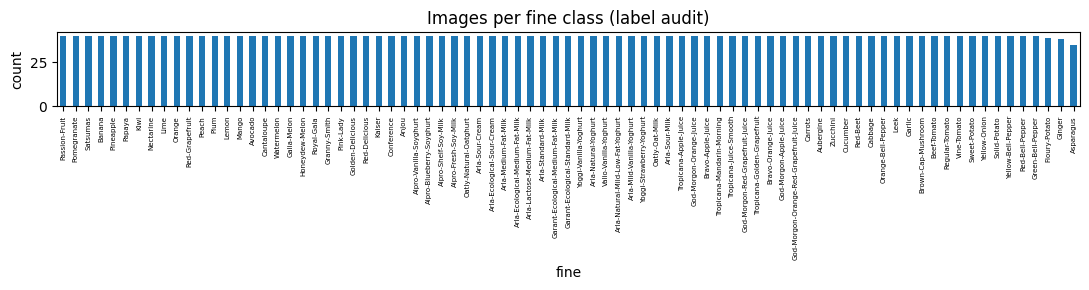

under-represented classes: none
near-duplicate pairs with CONFLICTING labels: 0


In [ ]:
%%train_only
# 🚀 E1a) Label audit: class balance + cross-label near-duplicates
import numpy as np, pandas as pd, matplotlib.pyplot as plt

counts = df.fine.value_counts()
plt.figure(figsize=(11, 3))
counts.plot(kind='bar')
plt.title('Images per fine class (label audit)'); plt.ylabel('count')
plt.xticks(fontsize=5); plt.tight_layout(); plt.show()
low = counts[counts < max(3, int(counts.median() * 0.5))]
print('under-represented classes:', low.to_dict() if len(low) else 'none')

# Near-duplicate scan: same-looking images with different labels are suspect labels.
fnorm = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-8)
sims = fnorm @ fnorm.T
np.fill_diagonal(sims, 0.0)
ii, jj = np.where(sims > 0.995)
suspects = [(df.path.iloc[a], df.fine.iloc[a], df.fine.iloc[c], round(float(sims[a, c]), 4))
            for a, c in zip(ii, jj) if a < c and df.fine.iloc[a] != df.fine.iloc[c]]
print(f'near-duplicate pairs with CONFLICTING labels: {len(suspects)}')
for s in suspects[:5]:
    print('  suspect:', s[1], 'vs', s[2], '| cosine sim', s[3])
b.put_table('label_audit.csv', pd.DataFrame({'fine': counts.index, 'n_images': counts.values}))


In [ ]:
%%train_only
# 🚀 E1b) Deterministic stratified 70/15/15 splits + richer catalog (SGD, promos)
from sklearn.model_selection import train_test_split

all_idx = np.arange(len(df))
tr_i, tmp_i = train_test_split(all_idx, test_size=0.30, random_state=42, stratify=df.fine)
va_i, te_i = train_test_split(tmp_i, test_size=0.50, random_state=42, stratify=df.fine.iloc[tmp_i])
df['split'] = 'train'
df.loc[df.index[va_i], 'split'] = 'val'
df.loc[df.index[te_i], 'split'] = 'test'
print(df.split.value_counts().to_dict(), '— stratified: every class appears in every split')
b.put_table('labels.csv', df)  # labels.csv now carries the audited split column

# Local-currency catalog with promotional discounts (used by the Day 5 checkout app).
SGD_PER_USD = 1.35  # demo rate — prices are editable catalog data, not real prices
catalog['unit_price_sgd'] = (catalog.unit_price * SGD_PER_USD).round(2)
catalog['currency_local'] = 'SGD'
rng_e1 = np.random.default_rng(42)
catalog['discount_pct'] = np.where(rng_e1.random(len(catalog)) < 0.20, 10, 0)  # ~20% of SKUs on 10% promo
print(catalog.head(18).to_string(index=False))
b.put_table('catalog_prices.csv', catalog)
save_bundle(b)


---
# Part 2 — Day 2: Localize (annotated base)

Everything below up to the 🚀 E2 section is the provided Day 2 annotated notebook, unchanged. (The pip/Drive setup cells are idempotent — they re-run instantly.)

🤖 **[CLAUDE] Welcome / How to read this notebook**

Hello! This is an annotated copy of the Day 2 SmartCart lab. Two kinds of cells live side by side:

- 🏷️ **[ORIGINAL]** cells are the untouched course material.
- 🤖 **[CLAUDE]** cells (like this one) are extra plain-language explanations added for beginners. You can skip them, but they explain *why* each step exists.

**The story so far (Day 1).** We are building **SmartCart**: a camera that looks at a checkout counter and rings up your groceries automatically. On Day 1 we collected labelled photos of single products, turned each photo into a numeric "fingerprint" with a model called DINOv2, and filed those fingerprints into a searchable **gallery** (plus a price catalog). Everything was packed into a **bundle** — a small folder on Google Drive that acts like a suitcase we carry from day to day.

**Today's mission: LOCALIZE.** A real checkout photo shows *many* items scattered on a counter. Before we can name anything, we must find **where** each item is. Today we (1) build our own multi-item scenes by pasting product photos onto backgrounds — like making a collage — (2) teach a detector called YOLO11 to draw a rectangle around every product, and (3) cut those rectangles out as small images for Day 3. By the end, the suitcase gains three things: `detector.pt` (the trained detector), a `crops/` folder with `crops_manifest.csv` (the cut-outs and their packing list), and `sample_scene.jpg` (a demo photo for Day 5).

**Mini-glossary** (peek back here whenever a word feels foreign):

- **Bounding box** — a rectangle drawn around one object, like framing each item with masking tape.
- **Ground truth** — the officially correct answer, the teacher's answer key we grade against.
- **Synthetic data** — training pictures we *manufacture ourselves* instead of photographing; our collages are synthetic scenes.
- **Class-agnostic** — the detector only says "something is here", never *what* it is. Finding and naming are kept separate on purpose.
- **Fine-tuning** — taking a model that already learned general skills and giving it a short extra course on *our* data.
- **IoU (Intersection over Union)** — a score for how much two rectangles overlap: 0 means no overlap, 1 means a perfect match.
- **ROI / crop** — a Region Of Interest: the little image we get by cutting out one bounding box with digital scissors.
- **Manifest** — a packing list: a table that records which file is which.
- **Bundle** — the Google Drive suitcase of artifacts passed between days.


> 🏷️ **[ORIGINAL]**

# SmartCart Day 2 - Localize

Day 1 gave us labelled single-product photos. A checkout sees a **counter full of items**, but GroceryStoreDataset does **not** provide bounding boxes. Today we create box labels by compositing real product photos into multi-item scenes, fine-tune **YOLO11** to find products, and crop the detections back out for Day 3's recognizer.

🤖 **[CLAUDE] Today's problem, in plain words**

Day 1 gave us neat flashcards: one product per photo, with its name. A real checkout is nothing like a flashcard — it is a cluttered counter with five items jumbled together. To handle that, we need a model that can point at each item: "here… here… and here." Those pointers are **bounding boxes**.

The catch: our grocery dataset has *names* but **no boxes**, and drawing boxes by hand is slow. The trick of the day: **make our own scenes**. If *we* paste each product photo onto a background, we know its exact rectangle for free — no human labeling needed. The plan for the notebook: set up → build collage scenes → check the boxes → try an off-the-shelf detector (and watch it fail) → fine-tune it → compare → cut out the detections → pack everything into the suitcase for Day 3.


🤖 **[CLAUDE] What this code does**

Housekeeping before the fun starts. `%pip install -q ultralytics` downloads the **Ultralytics** library — the toolbox that contains the YOLO11 detector we will train later (`-q` just means "quietly, less text"). Then it connects ("mounts") your **Google Drive** so this notebook can read and write the cross-day bundle — the suitcase folder `SmartCart` (a local folder in this merged notebook). Drive holds only small artifacts (tables, model weights), never the big image dataset.

**Expected output:** a short pip progress note, then a pop-up asking permission to access your Drive. Approve it and you should see `Mounted at ...`.


In [ ]:
%%train_only
# 1) Runtime setup
# This course runs in Google Colab. Run this cell first.
# Install only the packages used in this notebook.
%pip install -q ultralytics

import os

# The cross-day bundle lives in BUNDLE_DIR (a local folder set in the Demo settings cell) - no Drive mount needed.



> 🏷️ **[ORIGINAL]**

### Embedded toolkit

This hidden cell defines the helper functions used below. It is embedded so the notebook needs no separate `.py` upload. Run it once after setup.

🤖 **[CLAUDE] Why a hidden toolkit cell?**

Think of this as a toolbox bolted inside the notebook. Instead of asking you to upload a separate `.py` file every day, the course embeds its helper functions in one collapsed cell. You do not need to read it line by line — just run it once. The next Claude cell gives you a one-sentence tour of each tool so nothing feels like magic.


🤖 **[CLAUDE] What this code does (toolkit tour, one sentence per tool)**

This long cell only *defines* tools; nothing heavy runs yet. Here is what each one is for:

- **`Bundle` class** — the suitcase itself: it can store small tables (`put_table`) and number arrays (`put_array`) in the Drive folder, fetch them back (`get_table`, `get_array`), and keep a packing list called `manifest.json` (`save`/`load`).
- **`open_bundle` / `save_bundle`** — open the suitcase at the start of the day, and zip it closed (write the packing list) at the end.
- **`open_grocery_dataset`** — downloads the real GroceryStoreDataset from GitHub (or reuses a copy already on this machine) and complains loudly if the download failed.
- **`list_images`** — walks through the dataset's train/val/test folders and builds a table with one row per photo: its file path, its broad category (`coarse`, e.g. Apple), and its exact product (`fine`, e.g. Granny-Smith).
- **`compose_scene`** — the collage maker: it creates a pale, slightly noisy 640×640 canvas, pastes each product photo at a random spot (retrying up to 40 times to avoid heavy overlap with earlier pastes), and returns the finished image **plus the exact rectangle of every paste** — our free ground-truth boxes.
- **`yolo_boxes_to_txt`** — a translator that rewrites pixel rectangles into the text format YOLO expects (class id, then box center and size as fractions of the image).

**Expected output:** one line — `SmartCart toolkit ready`.


In [ ]:
%%train_only
from __future__ import annotations
import json
import os
import pathlib
import subprocess
import numpy as np
import pandas as pd
HERE = pathlib.Path.cwd()  # embedded in-notebook: no __file__, anchor on the working dir
GROCERY_DATASET_URL = 'https://github.com/marcusklasson/GroceryStoreDataset'

class Bundle:
    """Small Google Drive folder that carries artifacts from one day to the next."""

    def __init__(self, root: str):
        self.root = pathlib.Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.manifest = {'version': 1, 'class_list': [], 'artifacts': {}}

    def put_table(self, name, df: pd.DataFrame):
        df.to_csv(self.root / name, index=False)
        self._note(name)

    def get_table(self, name) -> pd.DataFrame:
        return pd.read_csv(self.root / name)

    def put_array(self, name, arr: np.ndarray):
        np.save(self.root / name, arr)
        self._note(name)

    def get_array(self, name) -> np.ndarray:
        p = self.root / name
        return np.load(p if p.suffix == '.npy' else p.with_suffix('.npy'))

    def _note(self, name):
        self.manifest['artifacts'][name] = True

    def save(self):
        (self.root / 'manifest.json').write_text(json.dumps(self.manifest, indent=2))

    def load(self):
        p = self.root / 'manifest.json'
        if p.exists():
            self.manifest = json.loads(p.read_text())
        return self

def open_bundle(drive_dir='/content/SmartCart') -> Bundle:
    """Open the cross-day Drive bundle. If it is new, start with an empty manifest."""
    return Bundle(drive_dir).load()

def save_bundle(b: Bundle):
    b.save()
    print(f'[bundle] saved -> {b.root}')

def open_grocery_dataset():
    """Clone or reuse the real GroceryStoreDataset and return (tier, root_dir)."""
    root = HERE / 'GroceryStoreDataset'
    if (root / 'dataset' / 'classes.csv').exists():
        print('using cached GroceryStoreDataset:', root)
    else:
        print('cloning GroceryStoreDataset from:', GROCERY_DATASET_URL)
        subprocess.run(['git', 'clone', '--depth', '1', GROCERY_DATASET_URL, str(root)], check=True)
    if not (root / 'dataset' / 'classes.csv').exists():
        raise RuntimeError('GroceryStoreDataset clone is incomplete. Check Colab network access and rerun.')
    print('using data tier: github')
    print('data root:', root)
    print('OK: using real GroceryStoreDataset images.')
    return ('github', str(root))

def list_images(root, per_class=None):
    """Return a DataFrame with columns path,coarse,fine from GroceryStoreDataset train/val/test folders."""
    root = pathlib.Path(root)
    rows = []
    for split in ('train', 'val', 'test'):
        for p in (root / 'dataset' / split).rglob('*.jpg'):
            rows.append({'path': str(p), 'coarse': p.parent.parent.name, 'fine': p.parent.name})
    df = pd.DataFrame(rows)
    if per_class and len(df):
        df = df.groupby('fine', group_keys=False).head(per_class).reset_index(drop=True)
    return df

def compose_scene(crops, canvas=(640, 640), seed=0, max_items=None):
    """Paste crops onto a blank canvas. Paste coordinates become detection boxes."""
    rng = np.random.default_rng(seed)
    H, W = canvas
    tint = rng.integers(225, 250, size=(1, 1, 3), dtype=np.uint8)
    noise = rng.integers(0, 12, size=(H, W, 3), dtype=np.uint8)
    img = np.minimum(tint + noise, 255).astype(np.uint8)
    boxes = []

    def iou_xywh(a, b):
        ax, ay, aw, ah = a
        bx, by, bw, bh = b
        ix1, iy1 = (max(ax, bx), max(ay, by))
        ix2, iy2 = (min(ax + aw, bx + bw), min(ay + ah, by + bh))
        inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
        union = aw * ah + bw * bh - inter
        return inter / union if union else 0.0
    for crop, label in crops if max_items is None else crops[:max_items]:
        ch, cw = crop.shape[:2]
        if ch >= H or cw >= W:
            continue
        x, y = (0, 0)
        for _ in range(40):
            x = int(rng.integers(0, W - cw))
            y = int(rng.integers(0, H - ch))
            if all((iou_xywh((x, y, cw, ch), b[:4]) < 0.08 for b in boxes)):
                break
        img[y:y + ch, x:x + cw] = crop
        boxes.append((x, y, cw, ch, label))
    return (img, boxes)

def yolo_boxes_to_txt(boxes, canvas, class_to_id):
    """Convert (x,y,w,h,label) pixel boxes to YOLO txt lines."""
    H, W = canvas
    lines = []
    for x, y, w, h, label in boxes:
        lines.append(f'{class_to_id[label]} {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}')
    return '\n'.join(lines)
# --- helpers are now available as plain functions/classes in this notebook ---
print('SmartCart toolkit ready')


SmartCart toolkit ready


🤖 **[CLAUDE] What this code does**

This opens the suitcase. `open_bundle(BUNDLE_DIR)` looks in your Drive folder and reads the packing list left there on Day 1. The print shows the folder path and which artifacts are already inside — you should recognize Day 1's items, such as the labels table, the DINOv2 gallery/index files, and the price catalog. If the list looks empty, the Day 1 notebook was not run (or Drive did not mount) — fix that first, because Day 2 adds new items to this same suitcase.


In [ ]:
%%train_only
# 2) Load the cross-day bundle
# The bundle stores artifacts we create during the week: labels, indexes, weights, ONNX files.
# It is NOT the image dataset. Images are loaded in the next data-source cell.
b = open_bundle(BUNDLE_DIR)
print('bundle:', b.root)
print('artifacts:', list(b.manifest.get('artifacts', {})))


🤖 **[CLAUDE] What this code does**

One line that fetches the raw ingredients: it calls `open_grocery_dataset()` from the toolkit to download (or reuse) the real GroceryStoreDataset — thousands of single-product grocery photos. It returns `tier` (where the data came from — here always `github`) and `root` (the folder path on *this* machine).

**Expected output:** either `cloning GroceryStoreDataset...` (first run, takes a moment) or `using cached...`, followed by `OK: using real GroceryStoreDataset images.` If it errors instead, the runtime has no GitHub access — rerun or check the network.


In [ ]:
%%train_only
# 3) Select the image data source
# For class runs we require the real GroceryStoreDataset. If GitHub is unavailable, stop clearly.
tier, root = open_grocery_dataset()


using cached GroceryStoreDataset: /content/GroceryStoreDataset
using data tier: github
data root: /content/GroceryStoreDataset
OK: using real GroceryStoreDataset images.


> 🏷️ **[ORIGINAL]**

## List product images (this runtime)

**What:** Re-list the product images from the data tier - paths must be valid in *today's* runtime.

**Why:** Each day is a fresh Colab VM, so we re-derive images rather than trust absolute paths saved on another day.

**Watch for:** Confirm the previous cell printed `using data tier: github` before continuing.

🤖 **[CLAUDE] Why we can't reuse yesterday's file paths**

Every day, Colab hands you a **brand-new virtual computer** — like checking into a hotel where the furniture is rearranged overnight. A path like `/content/GroceryStoreDataset/...` saved on Day 1 points to a machine that no longer exists. So instead of trusting old paths, we re-scan the freshly downloaded dataset and rebuild the photo table from scratch. This is why the bundle stores *results* (tables, model weights) but never absolute image paths.


🤖 **[CLAUDE] What this code does**

This builds today's photo table, `df`, by scanning the dataset folders with `list_images`. To keep things fast it keeps at most 40 photos per product (changeable via the `SC_PER_CLASS` setting). The `assert` line is a safety tripwire: if zero images were found, it stops immediately with a clear message instead of failing mysteriously later.

**Expected output:** something like `3240 images across 81 classes` — the exact numbers depend on the dataset, but both should be comfortably above zero.


In [ ]:
%%train_only
# Re-list images in this runtime. Do not reuse yesterday's absolute paths.
per_class = int(os.environ.get('SC_PER_CLASS','40'))
df = list_images(root, per_class=per_class)
assert len(df) > 0, 'No GroceryStoreDataset images found. Re-run the data-source cell.'
print(len(df), 'images across', df.fine.nunique(), 'classes')


3232 images across 81 classes


> 🏷️ **[ORIGINAL]**

## Compose multi-item counter scenes

**What:** Paste product photos from GroceryStoreDataset onto 640x640 canvases and emit YOLO label files.

**Why:** The dataset has class labels but no boxes. Because we control where each product is pasted, we know each bounding box exactly.

**Watch for:** We use a SINGLE class id 0 = 'product' (class-agnostic localization). Recognition is Day 3's job — keep detection simple and honest.

🤖 **[CLAUDE] The big idea: collages with free answer keys**

This is the cleverest step of the day. A detector learns from example images *plus* the correct boxes for each one. Nobody gave us boxes — so we manufacture the examples ourselves. Imagine making a collage: you cut product photos out of a magazine and glue them onto a sheet of paper. Since **you** did the gluing, you know *exactly* where every item sits — that rectangle is a perfect, free **ground-truth** box. No human annotator needed.

One more design choice: every product, whether it is an apple or a yoghurt, gets the same class id `0 = product`. This is **class-agnostic** detection: today's model only answers "something is here." Naming *which* product it is stays Day 3's job, using the fingerprint gallery from Day 1. Separating "finding" from "naming" keeps each model simple — and lets us add new products later without retraining the detector.


🤖 **[CLAUDE] What this code does (the heart of the lab — read slowly)**

This cell manufactures the whole training set. Follow the numbered steps in the comments:

- **Step 1 — one class for everything.** `class_to_id` maps every product name to the single id `0`. The detector will never learn names, only "product-ness."
- **Step 2 — organize the ingredients.** `by_class` groups photo paths by product, so scenes can sample different products fairly.
- **Step 3 — set the table.** YOLO expects a strict folder layout: `images/train`, `images/val`, `labels/train`, `labels/val`. These lines create it.
- **Step 4 — the paste loop (80 scenes).** For each scene `i`: every 4th scene is set aside as **val** (exam questions the model never trains on); the scene gets 1 item (every 5th scene) or a random 2–5 items; for each item we pick a product, pick one of its photos, and resize it to a random square between 90 and 260 pixels — so the detector sees big and small items. `compose_scene` then glues the picks onto a 640×640 canvas and hands back the image **and the list of paste rectangles**. We save the image as a `.jpg`, save the rectangles as a YOLO `.txt` label file, **and** stash the same rectangles (with the true product names!) in a dictionary called `scene_map`. That last bit is quiet but crucial bookkeeping: near the end of the notebook, `scene_map` is how we recover each crop's real name.

Finally, `data.yaml` is written — a small recipe card telling YOLO where the images and labels live and that there is exactly one class, named `product`.

**Expected output:** `composed 80 scenes with varied item counts and sizes` (and a new `datasets/scenes/` folder appears in the file browser).


In [ ]:
%%train_only
import os, glob
import numpy as np
from PIL import Image
# Step 1: class-agnostic detection. Every SKU maps to one id: product.
class_to_id = {fine: 0 for fine in df.fine.unique()}
# Step 2: collect image paths by SKU for balanced scene sampling.
by_class = {f: g.path.tolist() for f, g in df.groupby('fine')}
rng = np.random.default_rng(0)
# Step 3: create the YOLO folder layout.
for split in ['train','val']:
    os.makedirs(f'datasets/scenes/images/{split}', exist_ok=True)
    os.makedirs(f'datasets/scenes/labels/{split}', exist_ok=True)
# Step 4: compose scenes. The paste location gives us the YOLO bounding box label.
scene_map = {}  # scene_id -> list of (x,y,w,h,fine)
n_scenes = int(os.environ.get('SC_SCENES', 80))
for i in range(n_scenes):
    split = 'val' if i % 4 == 0 else 'train'
    picks = []
    # Mix single-item and multi-item scenes; this helps Day 5 uploads of one product.
    n_items = 1 if i % 5 == 0 else int(rng.integers(2, 6))
    for fine in rng.choice(list(by_class), size=n_items, replace=True):
        p = rng.choice(by_class[fine])
        size = int(rng.integers(90, 261))
        crop = np.array(Image.open(p).convert('RGB').resize((size, size)))
        picks.append((crop, fine))
    img, boxes = compose_scene(picks, canvas=(640,640), seed=i)
    Image.fromarray(img).save(f'datasets/scenes/images/{split}/scene_{i:03d}.jpg')
    open(f'datasets/scenes/labels/{split}/scene_{i:03d}.txt','w').write(
        yolo_boxes_to_txt(boxes, (640,640), class_to_id))
    scene_map[i] = (split, boxes)
with open('datasets/scenes/data.yaml','w') as f:
    f.write('path: datasets/scenes\ntrain: images/train\nval: images/val\nnames:\n  0: product\n')
print('composed', len(scene_map), 'scenes with varied item counts and sizes')


composed 80 scenes with varied item counts and sizes


> 🏷️ **[ORIGINAL]**

## Visualize ground-truth boxes

**What:** Draw the boxes that the notebook generated from paste coordinates.

**Why:** Students should see why these labels are valid: the notebook knows exactly where each product was pasted.

**Watch for:** Green boxes are ground truth. If boxes overlap heavily, the composed scene is a weak training example.

🤖 **[CLAUDE] Trust, but verify**

We *claim* the collage gives perfect boxes — now we look with our own eyes. This is a habit worth keeping for the whole week: after generating any data, **visualize a sample** before training on it. A model trained on silently broken labels will fail in confusing ways; a 5-second glance catches most problems for free.


🤖 **[CLAUDE] What this code does**

It defines a small drawing helper, `draw_xywh_boxes`: open an image, and for each box draw a rectangle plus a small text label just above it. Boxes arrive as `(x, y, w, h, label)` — the top-left corner, the width and height in pixels, and the product name. It then draws the ground-truth boxes for `scene_000` (the boxes come straight from `scene_map[0]`, our paste-time bookkeeping) and displays the result.


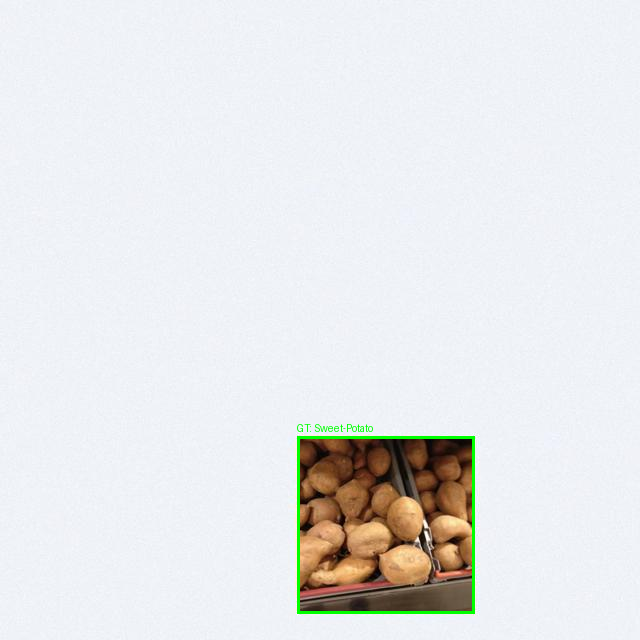

In [ ]:
%%train_only
from PIL import ImageDraw
def draw_xywh_boxes(image_path, boxes, color='lime', label_prefix='GT'):
    im = Image.open(image_path).convert('RGB')
    draw = ImageDraw.Draw(im)
    for x, y, w, h, label in boxes:
        draw.rectangle([x, y, x+w, y+h], outline=color, width=3)
        draw.text((x, max(0, y-14)), f'{label_prefix}: {label}', fill=color)
    return im
gt_img = draw_xywh_boxes('datasets/scenes/images/val/scene_000.jpg', scene_map[0][1])
gt_img


🤖 **[CLAUDE] How to read the output**

You should see a pale, slightly speckled square (the fake counter) with a few product photos glued on. Each product wears a **lime-green rectangle** — that color means *ground truth*, the answer key — and above each rectangle sits `GT:` plus the true product name. We can print the true name only because *we* pasted that product there. Two sanity checks: every pasted item should have exactly one box hugging it tightly, and if two items overlap heavily, that scene is a weak (confusing) training example — the composer tries to avoid this, but a little overlap is fine.


> 🏷️ **[ORIGINAL]**

## Optional: annotate real scenes

**What:** Use Label Studio or a similar tool if your team wants to replace composed scenes with manually boxed real counter/cart photos.

**Why:** Manual annotation is slower, but it tests whether the detector improves when trained on realistic clutter, lighting, and occlusion.

**Watch for:** Keep the same YOLO format: one `product` box per visible item. Compare manual-data YOLO against the composed-scene baseline.

🤖 **[CLAUDE] Real photos instead of collages? (optional path)**

Our collages are convenient, but they are still fakes — real counters have shadows, reflections, hands, and items hiding behind each other. Tools like **Label Studio** let a human draw boxes on real photos by mouse: essentially doing by hand what our paste loop got for free. It is slow (that slowness is exactly what synthetic data saved us from!), but a team that annotates 50 real scenes can train on them and check whether realism beats convenience. The key rule if you try it: keep the *same* format — a single class `product`, YOLO-style labels — so everything downstream still works.


🤖 **[CLAUDE] What this code does**

Nothing computational — it just prints a 4-step recipe for the optional real-photo route (capture, annotate in Label Studio, export YOLO labels, retrain and compare). Safe to run and safe to skip.


In [ ]:
%%train_only
print('Optional extension, not required for the core lab:')
print('1. Capture real counter/cart photos with multiple grocery items.')
print('2. Annotate visible product boxes in Label Studio as a single class: product.')
print('3. Export YOLO labels and arrange them as images/train, images/val, labels/train, labels/val.')
print('4. Train YOLO on those real annotations and compare mAP + Day 5 demo quality.')


Optional extension, not required for the core lab:
1. Capture real counter/cart photos with multiple grocery items.
2. Annotate visible product boxes in Label Studio as a single class: product.
3. Export YOLO labels and arrange them as images/train, images/val, labels/train, labels/val.
4. Train YOLO on those real annotations and compare mAP + Day 5 demo quality.


> 🏷️ **[ORIGINAL]**

## Baseline YOLO11

**What:** Run an out-of-the-box COCO-pretrained YOLO11n on one composed scene.

**Why:** Shows why we must fine-tune: COCO has 'banana' but not 'Granny-Smith' or 'Yoghurt'.

**Watch for:** Detections will be sparse/mislabelled - that's the point, it has never seen our products.

🤖 **[CLAUDE] Why test a stock detector first?**

YOLO11n comes pre-trained on **COCO**, a famous dataset of 80 everyday classes: person, car, dog, pizza, banana… It is like a tourist carrying an 80-word phrasebook — very confident about those 80 words, silent or wrong about everything else. Our shelves hold things like *Granny-Smith* and *Yoghurt*, which are simply not in its vocabulary. We run it anyway, **on purpose**, to see the failure with our own eyes. That failure is the motivation for the fine-tuning step right after.


🤖 **[CLAUDE] What this code does**

Three moves: (1) load the small pre-trained model `yolo11n.pt` (auto-downloads on first use); (2) run it on our composed `scene_000` — `r0` holds its detections, each with a box, a COCO class id, and a **confidence** score between 0 and 1 (how sure the model is); (3) draw those detections in **red** on the scene, labelled with the COCO class name and the confidence, e.g. `banana 0.42`.

**Expected output:** a print of how many boxes it found, then the image. Do not expect it to look good — that is the whole point.


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
baseline COCO detections: 0 — wrong class space for our products


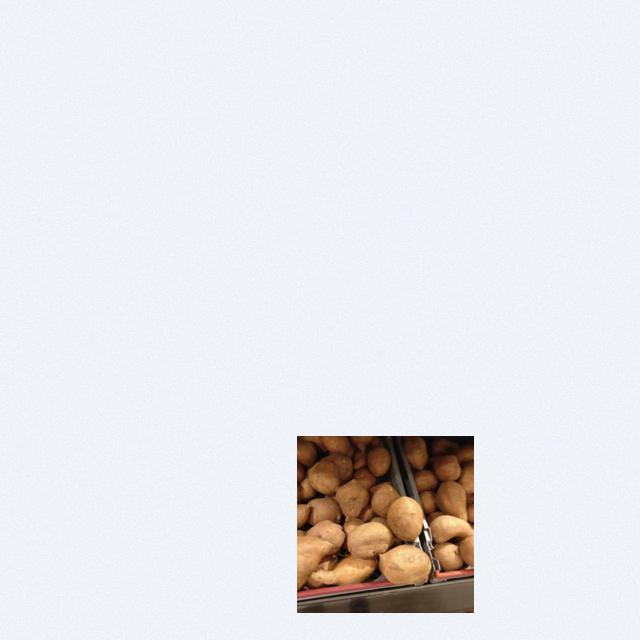

In [ ]:
%%train_only
from ultralytics import YOLO
m = YOLO('yolo11n.pt')
r0 = m('datasets/scenes/images/val/scene_000.jpg', verbose=False)[0]
print('baseline COCO detections:', len(r0.boxes), '— wrong class space for our products')
baseline_img = Image.open('datasets/scenes/images/val/scene_000.jpg').convert('RGB')
draw = ImageDraw.Draw(baseline_img)
for box, cls_id, conf in zip(r0.boxes.xyxy.cpu().numpy(), r0.boxes.cls.cpu().numpy(), r0.boxes.conf.cpu().numpy()):
    x1,y1,x2,y2 = [int(v) for v in box]
    label = f'{r0.names.get(int(cls_id), str(int(cls_id)))} {conf:.2f}'
    draw.rectangle([x1,y1,x2,y2], outline='red', width=3)
    draw.text((x1, max(0,y1-14)), label, fill='red')
baseline_img


🤖 **[CLAUDE] How to read the output**

Red boxes = the stock model's guesses. Typically you will see very few boxes, boxes in odd places, or labels borrowed from COCO's world — a yoghurt tub called `cup`, an apple called `orange`, or items ignored entirely. This is not a broken model; it is a capable model asked about a vocabulary it never learned. Remember this picture — after fine-tuning we will look at the *same scene* again and compare.


> 🏷️ **[ORIGINAL]**

## Fine-tune YOLO11 (core)

**What:** Train YOLO11 on our class-agnostic product scenes.

**Why:** A few epochs teach it 'this blob is a product' regardless of COCO's vocabulary.

**Watch for:** CPU users get fewer epochs (SC_EPOCHS); Colab GPU gets 20. mAP will be modest on generated data.

🤖 **[CLAUDE] Fine-tuning = a short bootcamp**

We do not train a detector from zero (that needs millions of images). Instead we take YOLO11n — which already knows edges, shapes, and "object-ness" from COCO — and give it a short bootcamp on our 80 collage scenes. Because we made the task class-agnostic, the lesson is refreshingly simple: *"forget the 80 names; just learn that these blobs are `product`."* Simple lessons need little data, which is why 80 synthetic scenes are enough for a usable detector.


🤖 **[CLAUDE] What this code does**

`m.train(...)` runs the bootcamp: 20 passes ("epochs") over the training scenes at 640×640 resolution (fewer epochs if the `SC_EPOCHS` setting says so, e.g. on a slow CPU). One epoch = the model sees every training scene once, guesses boxes, gets corrected against our ground truth, and adjusts. Afterwards it prints **mAP50-95** — a 0-to-1 report-card score for how well predicted boxes match ground truth on the val scenes (higher is better; modest values are normal on synthetic data). Finally it loads the best checkpoint (`best.pt`) into a new variable `detector` — our fine-tuned model, kept separate from the untouched baseline `m`.

**Expected output:** several minutes of training logs (a progress bar per epoch), then the mAP line and `loaded fine-tuned detector: runs/detect/train/weights/best.pt`.


In [ ]:
%%train_only
epochs = int(os.environ.get('SC_EPOCHS', 20))
res = m.train(data='datasets/scenes/data.yaml', epochs=epochs, imgsz=640, verbose=False)
try:
    print('fine-tuned mAP50-95:', float(res.box.map))
except Exception:
    print('training finished; see runs/ for metrics')
detector_path = os.path.join(getattr(res, 'save_dir', 'runs/detect/train'), 'weights', 'best.pt')
detector = YOLO(detector_path)
print('loaded fine-tuned detector:', detector_path)


Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/scenes/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, p

> 🏷️ **[ORIGINAL]**

## Baseline vs fine-tuned

**What:** Compare the COCO baseline against the fine-tuned detector on the same scene.

**Why:** Qualitatively the fine-tuned model should box products tightly with the single 'product' class.

**Watch for:** If fine-tuned boxes look worse, you likely need more epochs or more composed scenes.

🤖 **[CLAUDE] The before-and-after photo**

Time for the payoff. We show the *same* scene to the fine-tuned detector and overlay everything on one image: the answer key **and** the new predictions. This side-by-side is the fairest kind of comparison — same input, same drawing code, only the model changed.


🤖 **[CLAUDE] What this code does**

It runs the fine-tuned `detector` on `scene_000` and prints the detection counts for baseline vs fine-tuned. Then it builds one combined picture: first the **lime** ground-truth boxes (via our `draw_xywh_boxes` helper), then the fine-tuned model's **red** boxes drawn on top, each labelled `product` with its confidence. Red labels are placed *below* each box so they do not collide with the lime labels above.


In [ ]:
%%train_only
rb = detector('datasets/scenes/images/val/scene_000.jpg', verbose=False)[0]
print('fine-tuned detections on scene_000:', len(rb.boxes))
print('baseline had', len(r0.boxes), '-> fine-tuned has', len(rb.boxes))
compare = draw_xywh_boxes('datasets/scenes/images/val/scene_000.jpg', scene_map[0][1], color='lime', label_prefix='GT')
draw = ImageDraw.Draw(compare)
for box, cls_id, conf in zip(rb.boxes.xyxy.cpu().numpy(), rb.boxes.cls.cpu().numpy(), rb.boxes.conf.cpu().numpy()):
    x1,y1,x2,y2 = [int(v) for v in box]
    label = f'{rb.names.get(int(cls_id), str(int(cls_id)))} {conf:.2f}'
    draw.rectangle([x1,y1,x2,y2], outline='red', width=3)
    draw.text((x1, min(compare.height-16, y2+2)), label, fill='red')
compare


🤖 **[CLAUDE] How to read the output**

Lime = truth, red = the fine-tuned model's guesses. A healthy result: each red rectangle hugs a lime one, every label now reads `product` (no more `banana`/`cup` nonsense — compare with the baseline picture!), and the printed counts roughly agree with how many items are in the scene. Small offsets between red and lime edges are normal. If red boxes are missing or wildly off, the usual fixes are more epochs (`SC_EPOCHS`) or more composed scenes (`SC_SCENES`) — not panic.


> 🏷️ **[ORIGINAL]**

## Crop ROIs

**What:** Run the fine-tuned detector on every scene, crop each box, and recover its fine label.

**Why:** Day 3 trains a recognizer on real-shaped crops (detector output), not just clean catalog photos.

**Watch for:** Labels are recovered by matching detected boxes to the composed boxes we stashed in scene_map.

🤖 **[CLAUDE] Scissors time — and a clever name-recovery trick**

The detector finds rectangles, but Day 3's recognizer needs *images* it can name. So we cut ("crop") every detected rectangle out of its scene — each cut-out is an **ROI**. One problem: the class-agnostic detector only says `product`, yet Day 3 needs to know each crop is really a Granny-Smith or a Yoghurt to *train and check* the recognizer. The trick: we still have `scene_map`, our paste-time notebook of where every named product went. For each detected box we ask, "which ground-truth rectangle overlaps me the most?" — measured by **IoU**, the overlap score — and borrow that rectangle's name. Detection found it; bookkeeping names it.


🤖 **[CLAUDE] What this code does (the other heart of the lab)**

**First, the `iou(a, b)` function, step by step.** Both boxes come as `(x, y, w, h)` — top-left corner, width, height.

1. The overlap region's left/top edge is the *larger* of the two boxes' left/top edges (`max`); its right/bottom edge is the *smaller* of the two right/bottom edges (`min`).
2. If the boxes do not touch, that subtraction goes negative, so `max(0, ...)` clamps it to zero — no overlap, area 0.
3. `inter` = overlap width × overlap height. `union` = area of A + area of B − `inter` (subtracting so the shared part is not counted twice).
4. IoU = `inter / union`.

*Tiny numeric example:* A = `(0, 0, 10, 10)`, B = `(5, 0, 10, 10)` (B is shifted 5 px right). Overlap is 5 wide × 10 tall = 50. Union = 100 + 100 − 50 = 150. IoU = 50 / 150 ≈ **0.33**. Identical boxes give 1.0; separated boxes give 0.0.

**Then, the main loop.** For every scene: open the image, run the fine-tuned `detector`, and for each detected box — skipping slivers under 5 px — find the ground-truth box in `scene_map` with the **highest IoU** and adopt its product name. Cut the detected rectangle out of the image (`img[y1:y2, x1:x2]` — digital scissors), save it as a JPEG inside the bundle's `crops/` folder, and add one row `{crop_path, fine}` to a growing list. All rows become `crops_df`, the **crops manifest**. Two bonus copies go into the bundle: `scene_000` as `sample_scene.jpg` (Day 5's demo image) and the trained weights as `detector.pt` (Day 5's detector).

**Expected output:** something like `crops: 250 | detector.pt and sample_scene.jpg copied into bundle` — the count varies with how many boxes the detector found.


In [ ]:
%%train_only
import shutil
import pandas as pd
from pathlib import Path
def iou(a, b):
    ax,ay,aw,ah = a; bx,by,bw,bh = b
    ix1,iy1 = max(ax,bx), max(ay,by); ix2,iy2 = min(ax+aw,bx+bw), min(ay+ah,by+bh)
    iw,ih = max(0,ix2-ix1), max(0,iy2-iy1); inter = iw*ih
    union = aw*ah + bw*bh - inter
    return inter/union if union else 0.0
bundle_crops = Path(b.root) / 'crops'
bundle_crops.mkdir(parents=True, exist_ok=True)
rows = []
for i,(split, gboxes) in scene_map.items():
    img = np.array(Image.open(f'datasets/scenes/images/{split}/scene_{i:03d}.jpg').convert('RGB'))
    det = detector(f'datasets/scenes/images/{split}/scene_{i:03d}.jpg', verbose=False)[0]
    for j, box in enumerate(det.boxes.xyxy.cpu().numpy()):
        x1,y1,x2,y2 = [int(v) for v in box]; dw,dh = x2-x1, y2-y1
        if dw < 5 or dh < 5: continue
        best_gt = max(gboxes, key=lambda gb: iou((x1,y1,dw,dh),(gb[0],gb[1],gb[2],gb[3])), default=None)
        if best_gt is None: continue
        fine = best_gt[4]
        cp = bundle_crops / f'scene{i:03d}_{j}.jpg'
        Image.fromarray(img[y1:y2, x1:x2]).save(cp)
        rows.append({'crop_path': str(cp), 'fine': fine})
crops_df = pd.DataFrame(rows)
sample_scene = Path(b.root) / 'sample_scene.jpg'
shutil.copy('datasets/scenes/images/val/scene_000.jpg', sample_scene); b._note('sample_scene.jpg')
# Copy the best fine-tuned weights into the bundle as detector.pt for Day 5.
shutil.copy(detector_path, os.path.join(b.root, 'detector.pt')); b._note('detector.pt')
print('crops:', len(crops_df), '| detector.pt and sample_scene.jpg copied into bundle')


crops: 223 | detector.pt and sample_scene.jpg copied into bundle


🤖 **[CLAUDE] Extra demo — let's compute one IoU by hand and check it against the `iou()` function.**


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: compute IoU by hand for two small boxes
# Boxes are (x, y, width, height): top-left corner, then size.
a = (0, 0, 10, 10)   # box A: corner (0,0), 10 wide, 10 tall
box_b = (5, 0, 10, 10)   # box B: same size, shifted 5 pixels to the right

ix1 = max(a[0], box_b[0])                    # left edge of the overlap
iy1 = max(a[1], box_b[1])                    # top edge of the overlap
ix2 = min(a[0] + a[2], box_b[0] + box_b[2])      # right edge of the overlap
iy2 = min(a[1] + a[3], box_b[1] + box_b[3])      # bottom edge of the overlap
inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
union = a[2] * a[3] + box_b[2] * box_b[3] - inter

print(f'overlap rectangle: width {ix2 - ix1}, height {iy2 - iy1}  -> area {inter}')
print(f'union = {a[2] * a[3]} + {box_b[2] * box_b[3]} - {inter} = {union}')
print(f'IoU by hand      : {inter} / {union} = {inter / union:.3f}')
print(f'iou() from above : {iou(a, box_b):.3f}   (should match!)')
print(f'sanity checks -> identical boxes: {iou(a, a):.1f}, far-apart boxes: {iou(a, (50, 50, 10, 10)):.1f}')

overlap rectangle: width 5, height 10  -> area 50
union = 100 + 100 - 50 = 150
IoU by hand      : 50 / 150 = 0.333
iou() from above : 0.333   (should match!)
sanity checks -> identical boxes: 1.0, far-apart boxes: 0.0


🤖 **[CLAUDE] Extra demo — peek at the first rows of the crops manifest (the packing list Day 3 will read).**


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: peek at the crops manifest table
# Each row = one cut-out image, ready for Day 3's recognizer.
print('crop_path : where the cut-out JPEG lives (inside the bundle, so it survives to Day 3)')
print('fine      : the true product name, recovered by IoU-matching the detection to our paste records')
print()
print('total crops:', len(crops_df))
crops_df.head()


crop_path : where the cut-out JPEG lives (inside the bundle, so it survives to Day 3)
fine      : the true product name, recovered by IoU-matching the detection to our paste records

total crops: 223


🤖 **[CLAUDE] Extra demo — eyeball 3 random crops with their recovered names, exactly what Day 3's recognizer will receive.**


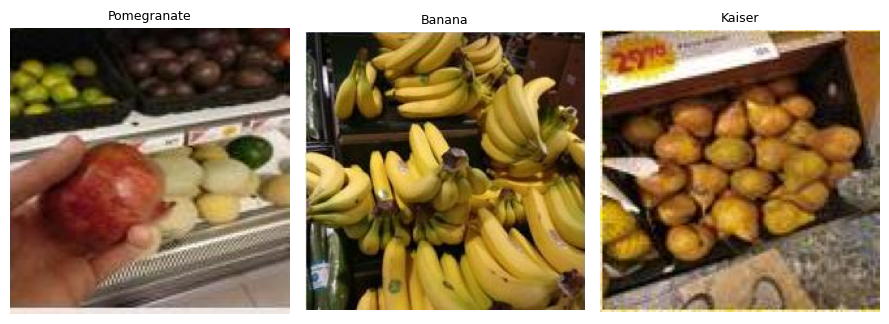

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: look at 3 random crops with their recovered labels
import matplotlib.pyplot as plt

sample = crops_df.sample(min(3, len(crops_df)), random_state=0)
fig, axes = plt.subplots(1, len(sample), figsize=(9, 3.2))
axes = np.atleast_1d(axes)  # works even if only one crop exists
for ax, (_, row) in zip(axes, sample.iterrows()):
    ax.imshow(Image.open(row.crop_path))
    ax.set_title(row.fine, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()
# If a crop looks slightly loose or tight around its product, that's the detector's
# small imperfection — Day 3's recognizer is trained on exactly these, so it copes.


> 🏷️ **[ORIGINAL]**

## Save + carry forward

**What:** Persist the crops manifest and save the bundle.

**Why:** Day 3 reads `crops_manifest.csv`; Day 5 uses `sample_scene.jpg` for a fresh-runtime demo.

**Watch for:** Confirm detector.pt and sample_scene.jpg show up in the bundle artifacts.

🤖 **[CLAUDE] Zipping the suitcase**

Files sitting only on this Colab machine vanish when the runtime shuts down. So the last step writes the crops manifest into the bundle on Drive and saves the packing list. Tomorrow, Day 3 opens the same suitcase, reads `crops_manifest.csv`, and trains the recognizer to put *names* on the crops — closing the loop with Day 1's fingerprint gallery. Day 5 will grab `detector.pt` and `sample_scene.jpg` for the live demo.


🤖 **[CLAUDE] What this code does**

Two lines of packing: `b.put_table('crops_manifest.csv', crops_df)` writes the manifest table into the Drive bundle (and notes it on the packing list), and `save_bundle(b)` writes the updated `manifest.json` so future days know what is inside.

**Expected output:** `[bundle] saved -> /content/SmartCart` plus the carry-forward summary line.


In [ ]:
%%train_only
b.put_table('crops_manifest.csv', crops_df)
save_bundle(b)
print('\u25b6 Carries forward to Day 3/5: detector.pt + crops_manifest.csv + sample_scene.jpg')


🤖 **[CLAUDE] How to read the output — and where we stand**

The `[bundle] saved` line confirms the suitcase is safely on Drive; the final line lists today's three additions: `detector.pt`, `crops_manifest.csv` (with the `crops/` folder), and `sample_scene.jpg`. Quick self-check: open your Drive's `SmartCart` folder and make sure all three exist. SmartCart status: Day 1 taught us to *fingerprint* single products; Day 2 taught us to *find* products in a cluttered scene and cut them out. Day 3 puts the two together: naming each crop. See you there!


---
## 🚀 [TEAM ENHANCEMENT] E2 — D2 Detection

"The base detector trains on clean pastel backgrounds — real counters are messier. So we built a **harder validation set**: real grocery photos, blurred and darkened, used as backgrounds; item crops get lighting jitter, random rotation, and up to 30 % overlap, so products occlude each other like in a real basket. We do *not* train on these — we use them purely as a stress test. Then, instead of accepting YOLO's default confidence of 0.25, we **swept the confidence threshold** on this hard set and picked the value with the best F1. That tuned threshold is saved to the bundle and used by the final app."

**Why this choice (full rationale):**
- *Hard scenes as a stress test, not training data* — evaluating on harder data than you train on exposes the robustness gap honestly (the brief: "validation metrics matter more than pretty outputs"). Retraining on hard scenes would also help, but conflates two changes; we keep the experiment controlled and fast.
- *Confidence/NMS tuning* — the cheapest possible detection improvement: zero retraining, immediate precision/recall control. A checkout app hates false positives (charging for items that are not there), so we choose the F1-optimal threshold, and report precision and recall so the trade-off is explicit.
- Alternatives considered: mosaic/copy-paste training augmentation (slower, entangled with E4), a larger YOLO model (GPU budget), open-vocabulary detectors (out of scope for a controlled comparison).


composed 24 HARD validation scenes (photo backgrounds + occlusion)


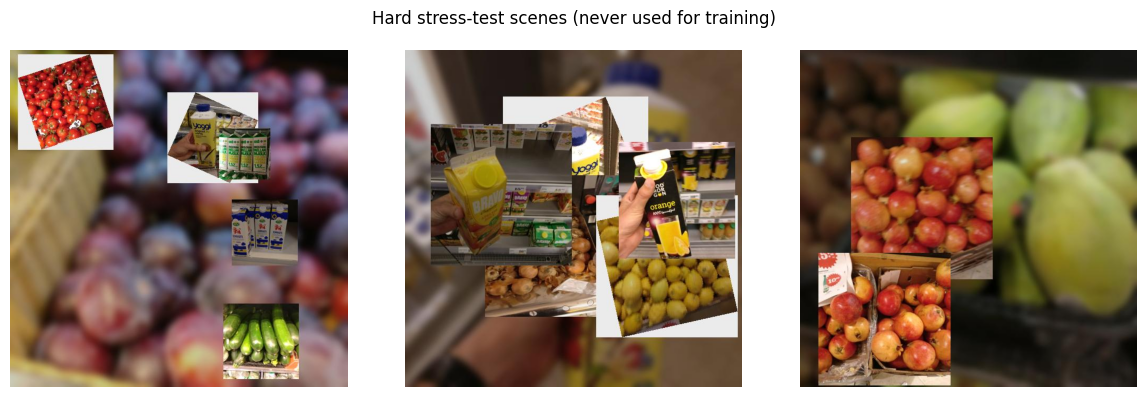

In [ ]:
%%train_only
# 🚀 E2a) Harder, more realistic scenes: photo backgrounds, occlusion, lighting, rotation
from PIL import Image, ImageFilter, ImageEnhance
import numpy as np

def compose_scene_hard(picks, canvas=(640, 640), seed=0, bg_paths=None, max_iou=0.30):
    """Like compose_scene, but with a real-photo background, lighting jitter,
    random rotation, and partial occlusion (IoU up to max_iou) between items."""
    rng = np.random.default_rng(seed)
    H, W = canvas
    if bg_paths is not None and len(bg_paths):
        bg = Image.open(str(rng.choice(bg_paths))).convert('RGB').resize((W, H))
        bg = ImageEnhance.Brightness(bg.filter(ImageFilter.GaussianBlur(6))).enhance(0.8)
        img = np.array(bg)
    else:
        img = np.full((H, W, 3), 235, np.uint8)
    boxes = []
    def iou_xywh(a, bb):
        ax, ay, aw, ah = a; bx, by, bw, bh = bb
        ix1, iy1 = max(ax, bx), max(ay, by)
        ix2, iy2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
        inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
        union = aw * ah + bw * bh - inter
        return inter / union if union else 0.0
    for crop, label in picks:
        pil = Image.fromarray(crop)
        pil = ImageEnhance.Brightness(pil).enhance(float(rng.uniform(0.7, 1.3)))
        if rng.random() < 0.5:
            pil = pil.rotate(float(rng.uniform(-25, 25)), expand=True, fillcolor=(235, 235, 235))
        cw, ch = pil.size
        if ch >= H or cw >= W:
            continue
        x = y = 0
        for _ in range(40):
            x, y = int(rng.integers(0, W - cw)), int(rng.integers(0, H - ch))
            if all(iou_xywh((x, y, cw, ch), bb[:4]) < max_iou for bb in boxes):
                break
        img[y:y + ch, x:x + cw] = np.array(pil)
        boxes.append((x, y, cw, ch, label))
    return img, boxes

os.makedirs('datasets/scenes_hard/images', exist_ok=True)
rng_h = np.random.default_rng(1234)
hard_map = {}
n_hard = 8 if FAST else 24
for i in range(n_hard):
    picks = []
    for fine in rng_h.choice(list(by_class), size=int(rng_h.integers(2, 6)), replace=True):
        p = rng_h.choice(by_class[fine])
        size = int(rng_h.integers(70, 300))  # wider scale jitter than the base scenes
        picks.append((np.array(Image.open(p).convert('RGB').resize((size, size))), fine))
    img_h, boxes_h = compose_scene_hard(picks, seed=i, bg_paths=df.path.tolist())
    Image.fromarray(img_h).save(f'datasets/scenes_hard/images/hard_{i:03d}.jpg')
    hard_map[i] = boxes_h
print('composed', len(hard_map), 'HARD validation scenes (photo backgrounds + occlusion)')
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, k in zip(axes, list(hard_map)[:3]):
    ax.imshow(Image.open(f'datasets/scenes_hard/images/hard_{k:03d}.jpg')); ax.axis('off')
fig.suptitle('Hard stress-test scenes (never used for training)')
plt.tight_layout(); plt.show()


,conf,precision,recall,f1
0,0.10,0.935,0.644,0.763
1,0.25,0.977,0.478,0.642
2,0.40,0.964,0.300,0.458
3,0.55,0.955,0.233,0.375
4,0.70,1.000,0.089,0.163


chosen operating point: conf=0.1 (best F1 on the HARD stress set)


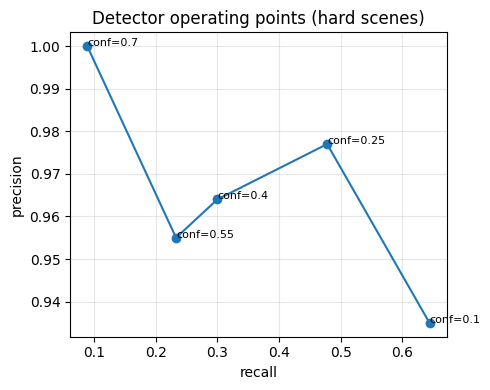

In [ ]:
%%train_only
# 🚀 E2b) Better inference settings: precision/recall sweep over confidence on the hard set
def box_iou_xywh(a, bb):
    ax, ay, aw, ah = a; bx, by, bw, bh = bb
    ix1, iy1 = max(ax, bx), max(ay, by)
    ix2, iy2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = aw * ah + bw * bh - inter
    return inter / union if union else 0.0

def sweep_point(conf_thr, iou_nms=0.7, match_iou=0.5):
    tp = fp = fn = 0
    for i, gboxes in hard_map.items():
        det = detector(f'datasets/scenes_hard/images/hard_{i:03d}.jpg',
                       conf=conf_thr, iou=iou_nms, verbose=False)[0]
        preds = []
        for bx in det.boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = [int(v) for v in bx]
            preds.append((x1, y1, x2 - x1, y2 - y1))
        used = set()
        for pb in preds:
            best_j, best_i = -1, 0.0
            for j, gb in enumerate(gboxes):
                if j in used: continue
                v = box_iou_xywh(pb, gb[:4])
                if v > best_i: best_j, best_i = j, v
            if best_i >= match_iou:
                tp += 1; used.add(best_j)
            else:
                fp += 1
        fn += len(gboxes) - len(used)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return prec, rec, f1

rows = []
for conf_thr in [0.10, 0.25, 0.40, 0.55, 0.70]:
    p_, r_, f_ = sweep_point(conf_thr)
    rows.append({'conf': conf_thr, 'precision': round(p_, 3), 'recall': round(r_, 3), 'f1': round(f_, 3)})
sweep_df = pd.DataFrame(rows)
display(sweep_df)
BEST_CONF = float(sweep_df.sort_values('f1', ascending=False).conf.iloc[0])
print(f'chosen operating point: conf={BEST_CONF} (best F1 on the HARD stress set)')
plt.figure(figsize=(5, 4))
plt.plot(sweep_df.recall, sweep_df.precision, 'o-')
for _, r in sweep_df.iterrows():
    plt.annotate(f"conf={r.conf}", (r.recall, r.precision), fontsize=8)
plt.xlabel('recall'); plt.ylabel('precision'); plt.title('Detector operating points (hard scenes)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
b.manifest['detector_conf'] = BEST_CONF
save_bundle(b)


---
# Part 3 — Day 3: Recognize & Diagnose (annotated base)

Everything below is the provided Day 3 annotated notebook, unchanged (Part 3 has no team enhancement cell).

🤖 **[CLAUDE] Welcome / How to read this notebook**

Hi! This notebook has two kinds of cells:

- **> 🏷️ [ORIGINAL]** — the course's own cells, completely unchanged.
- **🤖 [CLAUDE]** — friendly explanations (like this one) added for beginners, plus a few tiny extra demo cells.

**The SmartCart story so far.** We are building a smart shopping cart that recognizes groceries at checkout. On **Day 1** we collected labelled product photos, used a powerful pre-trained vision model (DINOv2) to turn each photo into a numeric "fingerprint", and stored everything — plus a price catalog — in a shared folder called the **bundle** that travels with us from day to day. On **Day 2** we trained a detector that finds *where* products sit in a photo and saved a cropped picture of each detected item.

**Today's mission: Recognize & Diagnose.** Day 2 can point at an item, but it can't name it. Today we train a small classifier that looks at a product photo and says *which* product it is — then, just as importantly, we investigate its mistakes. At the end we save three things into the bundle for Day 4: the trained classifier (`head.pt`), a per-product report card (`per_class_metrics.csv`), and a short error report (`error_report.md`).

**Mini-glossary** (analogies you'll see all day):

- **Frozen backbone** — DINOv2, a huge pre-trained model we *never* retrain. Think of it as a seasoned wine expert: show it any photo and it writes a rich, detailed description. "Frozen" means we don't change a single thing it knows.
- **Feature / embedding** — that written description: a list of a few hundred numbers that acts like the photo's *fingerprint*. Similar-looking products get similar fingerprints.
- **Classifier head** — a tiny, lightweight model we *do* train. It's the receptionist who reads the expert's description and announces a name: "that's a Granny Smith apple." Because the receptionist only reads short descriptions (not raw pixels), training takes seconds, not days.
- **Train/val split** — we divide our photos into *study questions* (used for learning) and *exam questions* (kept hidden until test time). Scoring on unseen exam questions tells us whether the model truly learned or just memorized.
- **Accuracy** — the fraction of exam questions answered correctly. 1.0 means perfect, 0.5 means half right.
- **Confusion matrix** — a table showing which products get mistaken for which. The diagonal counts correct answers; anything off the diagonal is a mix-up (e.g. "called a red apple a tomato, 3 times").
- **Occlusion heatmap** — we slide a small gray patch around a photo, covering one spot at a time, and watch when the model's answer breaks. The spots that break it are what the model was relying on. It's a cousin of the Grad-CAM technique from Lab 3.
- **Bundle** — our shared Google Drive folder, like a backpack we carry between class days.

Ready? Run the cells top to bottom.

> 🏷️ **[ORIGINAL]**

# SmartCart Day 3 - Recognize & Diagnose

Detection found *where* products are; now we learn *what* each one is. We train a tiny linear head on frozen features, then **diagnose** it - per -class accuracy, confusions, and an explanation heatmap - because a checkout that silently misreads items is worse than useless.

🤖 **[CLAUDE] Today in one picture**

Yesterday the cart learned to draw boxes around items — but a box just says "something is here." Today we give the cart a voice: *"that's whole milk — $2.49."* The plan has three acts:

1. **Recognize** — teach a tiny classifier to name products, using the frozen DINOv2 expert to describe each photo first.
2. **Test honestly** — score it on photos it has never seen (the "exam").
3. **Diagnose** — find out *which* products it confuses and *why*, because a checkout that silently charges you for the wrong item is worse than one that doesn't work at all.

Everything we build today plugs directly into Day 2's detector: detector finds the item, classifier names it — together, that's the checkout scanner.

🤖 **[CLAUDE] What this code does**

Housekeeping before the fun starts:

- `%pip install -q timm` installs **timm**, a library that gives us easy access to pre-trained vision models — that's where our DINOv2 "wine expert" comes from. The `-q` just means "quietly, less text".
- `drive.mount(...)` connects Google Drive to this Colab session and asks you to authorize it (a pop-up will appear — click through and allow).
- `BUNDLE_DIR` is the address of our cross-day backpack: the `SmartCart` folder on Drive where Days 1 and 2 left their artifacts.

**Expected output:** some quiet install messages, then a Drive authorization prompt, then `Mounted at ...`.

In [ ]:
%%train_only
# 1) Runtime setup
# This course runs in Google Colab. Run this cell first.
# Install only the packages used in this notebook.
%pip install -q timm

import os

# The cross-day bundle lives in BUNDLE_DIR (a local folder set in the Demo settings cell) - no Drive mount needed.



> 🏷️ **[ORIGINAL]**

### Embedded toolkit

This hidden cell defines the helper functions used below. Run it once after setup.

🤖 **[CLAUDE] About this "toolkit" cell**

The next code cell is collapsed on purpose — it's the kitchen drawer of utensils we'll reach into all day. You don't need to read every line; the cell below summarizes what each utensil does. Just run it once and move on.

🤖 **[CLAUDE] What this code does** — one sentence per helper:

- **`Bundle`** — a small class that reads/writes files (tables, arrays, notes) in our shared Drive folder and keeps a manifest (a packing list) of what's inside.
- **`open_bundle(...)`** — opens that Drive backpack, loading its packing list if one exists.
- **`save_bundle(b)`** — writes the packing list back to Drive so the next day can see what we left.
- **`open_grocery_dataset()`** — downloads (or reuses) the real GroceryStoreDataset — thousands of labelled grocery photos — from GitHub.
- **`list_images(root, per_class)`** — walks through the dataset folders and builds a table of image paths with their coarse label (e.g. "Apple") and fine label (e.g. "Granny-Smith").
- **`load_backbone(...)`** — loads the frozen DINOv2 model (our wine expert) with learning switched off — `requires_grad_(False)` literally means "do not change these brain cells."
- **`extract_features(...)`** — feeds batches of images through the backbone and returns their numeric fingerprints.
- **`LinearHead`** — the tiny trainable receptionist: one linear layer that maps a fingerprint to a product name, with `.fit()` to train it and `.predict()` to ask it questions.
- **`save_head(...)`** — saves the trained receptionist's weights to a file so Day 4 can reload it.

**Expected output:** a single line, `SmartCart toolkit ready`.

In [ ]:
%%train_only
from __future__ import annotations
import json
import os
import pathlib
import subprocess
import numpy as np
import pandas as pd
HERE = pathlib.Path.cwd()  # embedded in-notebook: no __file__, anchor on the working dir
GROCERY_DATASET_URL = 'https://github.com/marcusklasson/GroceryStoreDataset'

class Bundle:
    """Small Google Drive folder that carries artifacts from one day to the next."""

    def __init__(self, root: str):
        self.root = pathlib.Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.manifest = {'version': 1, 'class_list': [], 'artifacts': {}}

    def put_table(self, name, df: pd.DataFrame):
        df.to_csv(self.root / name, index=False)
        self._note(name)

    def get_table(self, name) -> pd.DataFrame:
        return pd.read_csv(self.root / name)

    def put_array(self, name, arr: np.ndarray):
        np.save(self.root / name, arr)
        self._note(name)

    def get_array(self, name) -> np.ndarray:
        p = self.root / name
        return np.load(p if p.suffix == '.npy' else p.with_suffix('.npy'))

    def _note(self, name):
        self.manifest['artifacts'][name] = True

    def save(self):
        (self.root / 'manifest.json').write_text(json.dumps(self.manifest, indent=2))

    def load(self):
        p = self.root / 'manifest.json'
        if p.exists():
            self.manifest = json.loads(p.read_text())
        return self

def open_bundle(drive_dir='/content/SmartCart') -> Bundle:
    """Open the cross-day Drive bundle. If it is new, start with an empty manifest."""
    return Bundle(drive_dir).load()

def save_bundle(b: Bundle):
    b.save()
    print(f'[bundle] saved -> {b.root}')

def open_grocery_dataset():
    """Clone or reuse the real GroceryStoreDataset and return (tier, root_dir)."""
    root = HERE / 'GroceryStoreDataset'
    if (root / 'dataset' / 'classes.csv').exists():
        print('using cached GroceryStoreDataset:', root)
    else:
        print('cloning GroceryStoreDataset from:', GROCERY_DATASET_URL)
        subprocess.run(['git', 'clone', '--depth', '1', GROCERY_DATASET_URL, str(root)], check=True)
    if not (root / 'dataset' / 'classes.csv').exists():
        raise RuntimeError('GroceryStoreDataset clone is incomplete. Check Colab network access and rerun.')
    print('using data tier: github')
    print('data root:', root)
    print('OK: using real GroceryStoreDataset images.')
    return ('github', str(root))

def list_images(root, per_class=None):
    """Return a DataFrame with columns path,coarse,fine from GroceryStoreDataset train/val/test folders."""
    root = pathlib.Path(root)
    rows = []
    for split in ('train', 'val', 'test'):
        for p in (root / 'dataset' / split).rglob('*.jpg'):
            rows.append({'path': str(p), 'coarse': p.parent.parent.name, 'fine': p.parent.name})
    df = pd.DataFrame(rows)
    if per_class and len(df):
        df = df.groupby('fine', group_keys=False).head(per_class).reset_index(drop=True)
    return df

def load_backbone(name='vit_small_patch14_dinov2.lvd142m', device='cpu'):
    """Frozen DINOv2-small feature extractor."""
    import timm
    m = timm.create_model(name, pretrained=True, num_classes=0, dynamic_img_size=True).eval().to(device)
    for p in m.parameters():
        p.requires_grad_(False)
    return m

def extract_features(model, batches, device=None) -> np.ndarray:
    """Run image batches through a frozen backbone and return numpy features."""
    import torch
    if device is None:
        try:
            device = next(model.parameters()).device
        except (AttributeError, StopIteration):
            device = 'cpu'
    outs = []
    with torch.no_grad():
        for xb in batches:
            y = model(xb.to(device))
            outs.append(y.detach().cpu().numpy().astype('float32'))
    return np.concatenate(outs, 0)

class LinearHead:
    """Tiny torch linear classifier trained on frozen image features."""

    def __init__(self, in_dim, n_classes):
        import torch
        import torch.nn as nn
        self.net = nn.Linear(in_dim, n_classes)
        self.torch = torch

    def fit(self, X, y, epochs=30, lr=0.01):
        t = self.torch
        opt = t.optim.Adam(self.net.parameters(), lr=lr)
        lossf = t.nn.CrossEntropyLoss()
        Xt = t.tensor(X)
        yt = t.tensor(y)
        for _ in range(epochs):
            opt.zero_grad()
            loss = lossf(self.net(Xt), yt)
            loss.backward()
            opt.step()
        return self

    def predict(self, X):
        with self.torch.no_grad():
            return self.net(self.torch.tensor(X)).argmax(1).numpy()

def save_head(head: LinearHead, path):
    import torch
    torch.save({'state_dict': head.net.state_dict(), 'in_dim': head.net.in_features, 'n_classes': head.net.out_features}, path)
    return path
# --- helpers are now available as plain functions/classes in this notebook ---
print('SmartCart toolkit ready')


SmartCart toolkit ready


🤖 **[CLAUDE] What this code does**

Opens the backpack (the bundle) and prints its packing list. If Days 1 and 2 went well, you should see artifacts like the class list, the price catalog, and — importantly for today — `crops_manifest.csv`, the list of cropped product images Day 2's detector produced.

**Expected output:** the bundle's folder path and a list of artifact names carried over from earlier days.

In [ ]:
%%train_only
# 2) Load the cross-day bundle
# The bundle stores artifacts we create during the week: labels, indexes, weights, ONNX files.
# It is NOT the image dataset. Images are loaded in the next data-source cell.
b = open_bundle(BUNDLE_DIR)
print('bundle:', b.root)
print('artifacts:', list(b.manifest.get('artifacts', {})))


🤖 **[CLAUDE] What this code does**

Fetches the actual grocery photos. The bundle only carries small files (labels, model weights, notes) — the image dataset itself is re-downloaded fresh each day from GitHub, because Colab gives us a brand-new machine every session (imagine a hotel room that's emptied every night; the backpack is the only thing we keep).

**Expected output:** either `cloning GroceryStoreDataset...` (first run, takes a minute) or `using cached GroceryStoreDataset` — then `OK: using real GroceryStoreDataset images.`

In [ ]:
%%train_only
# 3) Select the image data source
# For class runs we require the real GroceryStoreDataset. If GitHub is unavailable, stop clearly.
tier, root = open_grocery_dataset()


using cached GroceryStoreDataset: /content/GroceryStoreDataset
using data tier: github
data root: /content/GroceryStoreDataset
OK: using real GroceryStoreDataset images.


> 🏷️ **[ORIGINAL]**

## Load the training set (annotated images) + any detector crops

**What:** Re-list the balanced product images for *this* runtime; load Day 2's saved detector crops for a real-world check.

**Why:** The classifier learns from clean, balanced labels - not from however many crops the detector found. We re-list rather than trust saved paths because each day is a fresh VM.

**Watch for:** Detector crops live in the Drive bundle; if the count is 0, rerun Day 2 with the updated notebook.

🤖 **[CLAUDE] In plain words**

We're gathering two piles of photos:

1. **Clean training photos** — nicely framed, correctly labelled product pictures from the dataset. These are the *textbook examples* the classifier will study from. We re-list them from disk right now (rather than trusting file paths saved yesterday) because today's Colab machine is a fresh hotel room — yesterday's paths point at furniture that no longer exists.
2. **Day 2's detector crops** — real, messy snapshots our own detector cut out of shelf photos. We won't train on these; we save them for the honest *field test* later ("closing the loop").

Why train on clean photos but test on messy crops? A student studies from a textbook, but the real exam is life. If the count of detector crops is 0, Day 2 wasn't run — the notebook will still work, just without the field test.

🤖 **[CLAUDE] What this code does**

- Takes up to **40 photos per product** (`per_class=40`) so no product hogs the classroom — a balanced diet of examples.
- Renames the `path` column to `crop_path` so training photos and detector crops share the same column name later.
- Then it *tries* to load `crops_manifest.csv` from the bundle and keeps only crops whose image files still exist. If anything goes wrong (e.g. Day 2 skipped), it shrugs and sets `crops = None` — the notebook continues without the field test.

**Expected output:** something like `training images: 3240` and a count of detector crops (possibly 0).

In [ ]:
%%train_only
import os
# Train from clean labelled product photos re-listed in this runtime.
per_class = int(os.environ.get('SC_PER_CLASS','40'))
data = list_images(root, per_class=per_class).rename(columns={'path':'crop_path'})
assert len(data) > 0, 'No GroceryStoreDataset images found. Re-run the data-source cell.'
print('training images:', len(data))
# Optional real-world check: Day 2 saved detector crops into the Drive bundle.
try:
    crops = b.get_table('crops_manifest.csv')
    crops = crops[crops.crop_path.apply(os.path.exists)]
    crops = crops if len(crops) else None
    print('detector crops available for a real-world check:', 0 if crops is None else len(crops))
except Exception:
    crops = None; print('no detector crops yet (Day 2 skipped) — training on annotated images only')


training images: 3232
detector crops available for a real-world check: 223


> 🏷️ **[ORIGINAL]**

## Features + split

**What:** Embed every image, integer-encode the fine labels, and make a (guarded) stratified train/val split.

**Why:** Frozen features + a linear head is a strong, fast baseline; stratifying keeps rare classes in both sides.

**Watch for:** If any class has <2 samples we drop stratification automatically so the split never crashes.

🤖 **[CLAUDE] In plain words**

This is the heart of the "wine expert + receptionist" trick, in three moves:

1. **Embed** — show every photo to the frozen DINOv2 expert once, and store the fingerprint (a few hundred numbers) it writes for each. From here on we never touch raw pixels again.
2. **Encode labels** — computers prefer numbers to words, so each product name gets an ID number: `Granny-Smith → 0`, `Golden-Delicious → 1`, and so on.
3. **Split** — shuffle the deck and deal 70% of photos into the *study pile* and 30% into the *exam pile*. "Stratified" means every product appears in both piles in fair proportion — like making sure the exam covers every chapter of the textbook, not just the first three. (If some product has fewer than 2 photos, fair dealing is impossible, so the code gracefully falls back to a plain shuffle instead of crashing.)

🤖 **[CLAUDE] What this code does** — step by step, because this cell matters:

- **`TF` (the preprocessing recipe):** every photo is resized to 224×224 pixels, converted to numbers between 0 and 1, then normalized (shifted/scaled by standard constants) — the exact "table setting" DINOv2 expects before it will taste anything.
- **`feats_of(paths, model)` (the embedding loop):** works through the photo list **16 at a time** (a *batch* — like a dishwasher rack, more efficient than one plate at a time). Each batch goes through the frozen backbone, and out comes one fingerprint row per photo. All rows are stacked into one big array `feats` with shape `(number of photos, fingerprint length)`.
- **Label → integer encoding:** `classes` is the alphabetized list of product names, `cls_to_i` is a name→number phone book, and `y` is every photo's label as a number. The alphabetical sort matters: it makes the numbering *reproducible*, so class 7 means the same product tomorrow.
- **The split:** `train_test_split(..., test_size=0.3, random_state=0, stratify=strat)` deals 70% study / 30% exam. `random_state=0` fixes the shuffle so everyone in class gets the identical split. `stratify` keeps class proportions fair (with the <2-samples safety check described above).

**Expected output:** the device (`cuda` on a GPU runtime), a model-download progress bar the first time, then something like `train (2268, 384) val (972, 384) | 81 classes` — 2268 study fingerprints, 384 numbers each, 81 products. This cell is the slowest of the day (a few minutes on CPU) because the expert examines every photo.

In [ ]:
%%train_only
import torch, torchvision.transforms.v2 as T
from PIL import Image
import numpy as np
# Shared image preprocessing for DINOv2.
TF = T.Compose([T.ToImage(), T.Resize((224,224)), T.ToDtype(torch.float32, scale=True),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
def feats_of(paths, model, bs=16):
    """Embed image files in small batches and return an (N, D) numpy array."""
    out=[]
    for i in range(0,len(paths),bs):
        xs=torch.stack([TF(Image.open(p).convert('RGB')) for p in paths[i:i+bs]])
        out.append(extract_features(model,[xs]))
    return np.concatenate(out,0)
from sklearn.model_selection import train_test_split
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using device:', device)
model = load_backbone(device=device)
# Embed each image once, then train only a small linear classifier.
feats = feats_of(list(data.crop_path), model)
classes = sorted(data.fine.unique().tolist())
cls_to_i = {c:i for i,c in enumerate(classes)}
y = np.array([cls_to_i[f] for f in data.fine])
# Stratify only when every class has enough examples.
counts = np.bincount(y, minlength=len(classes))
strat = y if counts.min() >= 2 else None  # stratify only when every class has >=2 samples
Xtr,Xval,ytr,yval = train_test_split(feats, y, test_size=0.3, random_state=0, stratify=strat)
print('train', Xtr.shape, 'val', Xval.shape, '|', len(classes), 'classes')


using device: cpu
train (2262, 384) val (970, 384) | 81 classes


🤖 **[CLAUDE] Extra demo (added cell):** let's peek at one actual fingerprint, so "embedding" stops being abstract.

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: peek at one image's "fingerprint"
print("photos embedded:", feats.shape[0])
print("numbers per fingerprint:", feats.shape[1])
print()
print("first 8 numbers of photo 0's fingerprint:")
print(np.round(feats[0][:8], 3))
print()
print("photo 0 is labelled:", data.fine.iloc[0], "-> encoded as integer", y[0])
# The fingerprint means nothing to human eyes -- but similar products
# get similar fingerprints, and that's all the receptionist needs.

photos embedded: 3232
numbers per fingerprint: 384

first 8 numbers of photo 0's fingerprint:
[      1.876      -1.102       2.543      -0.335      -0.062       2.867      -1.382       3.234]

photo 0 is labelled: Passion-Fruit -> encoded as integer 54


> 🏷️ **[ORIGINAL]**

## Train the head

**What:** Fit the `LinearHead` on the training features and report validation accuracy.

**Why:** This is the actual product classifier - small enough to export and ship on Day 5.

**Watch for:** If val accuracy is near chance, features or labels are misaligned - stop and check.

🤖 **[CLAUDE] In plain words**

Time to train the receptionist. Notice what we are **not** doing: we are not training DINOv2 (millions of parameters, would take days and a warehouse of GPUs). We're training one small linear layer that reads a 384-number fingerprint and picks one of 81 product names. That's why this cell finishes in seconds — the expensive expert already did the hard work of *seeing*; the head only learns to *name*. This tiny head is also exactly what we'll export and ship in the cart on Day 5 — small enough to run on modest hardware.

🤖 **[CLAUDE] What this code does**

- `LinearHead(in_dim=384, n_classes=81)` builds the receptionist: one linear layer sized to our fingerprints and product list.
- `.fit(Xtr, ytr, epochs=200)` trains it: **200 times in a row** it (1) guesses names for all study fingerprints, (2) measures how wrong it was (a score called *cross-entropy loss* — big when confidently wrong), and (3) nudges its internal dials to be slightly less wrong (the Adam optimizer does the nudging). Two hundred rounds of guess → grade → adjust.
- `head.predict(Xval)` then answers the **exam questions** — fingerprints it has never trained on.
- `acc` is simply the fraction of exam answers that match the true labels.

**Expected output:** one line, e.g. `validation accuracy: 0.9` or so. Anything near `0.012` (random-guess level for 81 classes) means something is broken — see the "Watch for" note above.

In [ ]:
%%train_only
head = LinearHead(in_dim=feats.shape[1], n_classes=len(classes)).fit(Xtr, ytr, epochs=200)
val_pred = head.predict(Xval)
# Simple top-1 validation accuracy.
acc = float((val_pred == yval).mean())
print('validation accuracy:', round(acc, 3))


validation accuracy: 0.939


🤖 **[CLAUDE] How to read the output**

One number, but it deserves context. With 81 products, a monkey picking names at random would score about **1/81 ≈ 1.2%**. So if you see something like 85–95%, the head isn't just guessing — it genuinely learned to map fingerprints to products, and it did so on *exam* photos it never studied. That gap between random (1.2%) and achieved accuracy is the whole payoff of borrowing a frozen expert: we bought world-class vision for the price of training one small layer for a few seconds. Also remember accuracy is an *average* — it can hide products that fail badly, which is exactly why the next section exists.

🤖 **[CLAUDE] Extra demo (added cell):** put that accuracy number next to the random-guess baseline.

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: random-guess baseline vs our accuracy
baseline = 1 / len(classes)
print(f"products to choose from: {len(classes)}")
print(f"random guessing would score:  {baseline:.1%}")
print(f"our classifier head scored:   {acc:.1%}")
print(f"-> roughly {acc / baseline:.0f}x better than guessing")

products to choose from: 81
random guessing would score:  1.2%
our classifier head scored:   93.9%
-> roughly 76x better than guessing


🤖 **[CLAUDE] Extra demo (added cell):** numbers are nice, but let's *see* three exam photos the head named correctly. (We re-deal the split with the same fixed seed to recover which photos landed in the exam pile.)

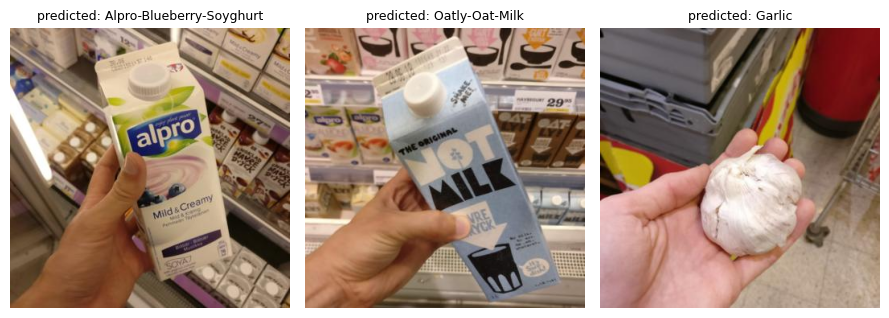

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: three validation photos the head got right
import matplotlib.pyplot as plt
from PIL import Image
# Re-run the same split on row numbers (same seed => same deal) to find
# which original photos ended up in the validation ("exam") pile.
idx_all = np.arange(len(y))
_, val_idx = train_test_split(idx_all, test_size=0.3, random_state=0, stratify=strat)
right = np.where(val_pred == yval)[0][:3]
plt.figure(figsize=(9, 3.2))
for k, v in enumerate(right):
    p = data.crop_path.iloc[int(val_idx[int(v)])]
    plt.subplot(1, 3, k + 1)
    plt.imshow(Image.open(p).convert('RGB'))
    plt.title(f"predicted: {classes[int(val_pred[int(v)])]}", fontsize=9)
    plt.axis('off')
plt.tight_layout()

> 🏷️ **[ORIGINAL]**

## Error analysis

**What:** Build a confusion matrix, a per-class accuracy table, and surface the hardest confusions.

**Why:** Aggregate accuracy hides which SKUs fail; the checkout cares about *which* items it gets wrong.

**Watch for:** Low-n classes have noisy accuracy - read them alongside their support count.

🤖 **[CLAUDE] In plain words**

Overall accuracy is like a school's average grade — useful, but it won't tell you that one student is failing math. For a checkout, *which* mistakes happen matters enormously: confusing two apple varieties is a small pricing error; confusing juice with wine is a real problem. So we build three views of the mistakes:

1. **Per-product report card** — accuracy for each product individually, with `n` (how many exam photos it had — few photos means a noisy, less trustworthy grade).
2. **Hardest confusions** — a ranked list of "product A keeps being called product B" pairs.
3. **A focused confusion matrix** — the full 81×81 table would be wallpaper, so we zoom into the ~14 most troubled products.

🤖 **[CLAUDE] What this code does**

- **Building the confusion matrix:** `confusion_matrix(yval, val_pred)` makes a square table with one row per *true* product and one column per *predicted* product. Every exam photo adds +1 to one square: row = what it really was, column = what the head said. Correct answers land on the **diagonal** (row = column); every off-diagonal count is a specific mix-up.
- **Per-class table (`pcm`):** for each product, accuracy = its diagonal count divided by its row total, plus `n` = how many exam photos it had. Sorted worst-first, so the top of the table is your trouble list.
- **Confusion pairs (`conf_df`):** every non-zero off-diagonal square becomes a row like `true=Red-Delicious, predicted=Royal-Gala, count=3`, sorted by count — the head's most repeated mix-ups.
- **The focused plot:** picks the 8 weakest products plus the products from the top confusion pairs (about 14 total) and draws just that corner of the matrix as a blue heatmap with counts written in each square.

**Expected output:** two tables and one blue matrix plot. The slowest products to learn tend to be visually similar siblings — different apple or juice varieties.

,fine,acc,n
0,God-Morgon-Orange-Red-Grapefruit-Juice,0.500000,12
1,Arla-Natural-Mild-Low-Fat-Yoghurt,0.750000,12
2,Oatly-Oat-Milk,0.750000,12
3,Yoggi-Vanilla-Yoghurt,0.750000,12
4,Asparagus,0.818182,11
...,...,...,...
76,Tropicana-Juice-Smooth,1.000000,12
77,Vine-Tomato,1.000000,12
78,Watermelon,1.000000,12
79,Yellow-Onion,1.000000,12


,true,predicted,count
0,Arla-Natural-Mild-Low-Fat-Yoghurt,Arla-Natural-Yoghurt,3
1,God-Morgon-Orange-Red-Grapefruit-Juice,God-Morgon-Orange-Juice,3
2,Yoggi-Vanilla-Yoghurt,Yoggi-Strawberry-Yoghurt,3
3,Alpro-Blueberry-Soyghurt,Alpro-Fresh-Soy-Milk,2
4,Arla-Sour-Milk,Arla-Medium-Fat-Milk,2
5,God-Morgon-Orange-Red-Grapefruit-Juice,God-Morgon-Red-Grapefruit-Juice,2
6,Oatly-Oat-Milk,Garant-Ecological-Medium-Fat-Milk,2
7,Alpro-Fresh-Soy-Milk,Alpro-Vanilla-Soyghurt,1
8,Alpro-Shelf-Soy-Milk,Alpro-Blueberry-Soyghurt,1
9,Alpro-Vanilla-Soyghurt,Alpro-Blueberry-Soyghurt,1


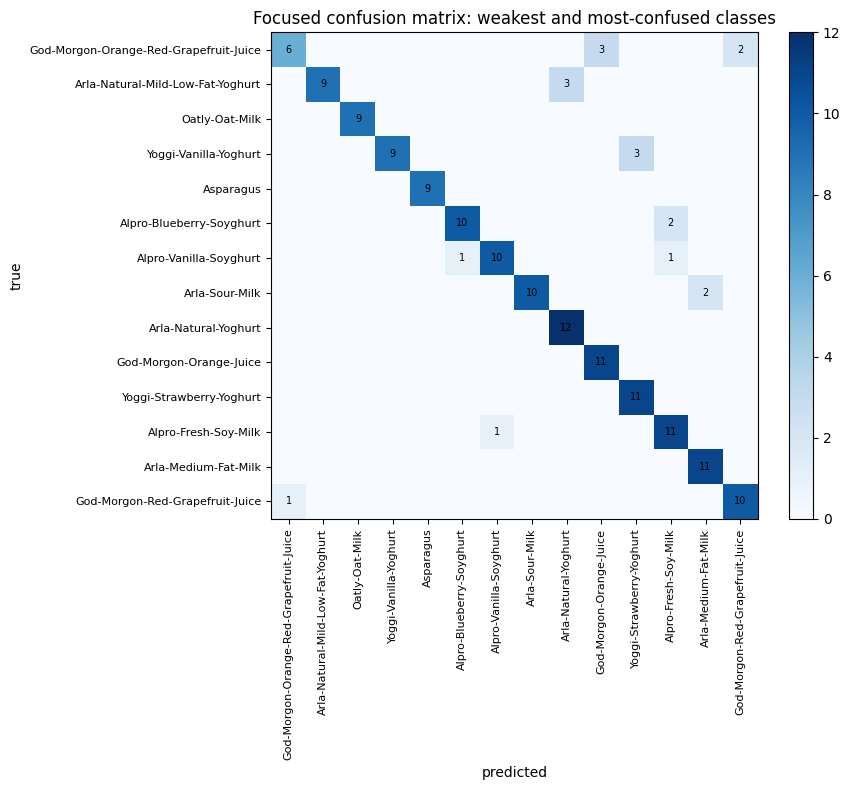

In [ ]:
%%train_only
from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
# Rows are true classes; columns are predicted classes.
cm = confusion_matrix(yval, val_pred, labels=list(range(len(classes))))
pcm = pd.DataFrame({
    'fine': classes,
    'acc': [cm[i,i]/cm[i].sum() if cm[i].sum() else 0.0 for i in range(len(classes))],
    'n': [int(cm[i].sum()) for i in range(len(classes))]})
display(pcm.sort_values(['acc','n']).reset_index(drop=True))
conf = [(classes[i], classes[j], int(cm[i,j])) for i in range(len(classes)) for j in range(len(classes)) if i!=j and cm[i,j]>0]
conf_df = pd.DataFrame(sorted(conf, key=lambda t:-t[2]), columns=['true','predicted','count'])
display(conf_df.head(12) if len(conf_df) else pd.DataFrame(columns=['true','predicted','count']))
# A full 81x81 matrix is unreadable. Plot a focused matrix around weak/confused classes.
weak = pcm.sort_values(['acc','n']).head(8).fine.tolist()
confused = list(dict.fromkeys(conf_df.head(8)[['true','predicted']].to_numpy().ravel().tolist())) if len(conf_df) else []
focus = list(dict.fromkeys(weak + confused))[:14]
focus_idx = [classes.index(c) for c in focus]
focus_cm = cm[np.ix_(focus_idx, focus_idx)]
fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(focus_cm, cmap='Blues')
ax.set_xticks(range(len(focus))); ax.set_yticks(range(len(focus)))
ax.set_xticklabels(focus, rotation=90, fontsize=8); ax.set_yticklabels(focus, fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title('Focused confusion matrix: weakest and most-confused classes')
for r in range(len(focus)):
    for c in range(len(focus)):
        if focus_cm[r,c]: ax.text(c, r, int(focus_cm[r,c]), ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()


🤖 **[CLAUDE] How to read the output**

- **Per-class table:** sorted worst-first, so start at the top. An `acc` of 0.5 with `n=3` means 1–2 photos wrong out of 3 — with so few exam photos, one unlucky photo swings the grade a lot, so read low-`n` rows with a grain of salt.
- **Confusion pairs:** each row is a repeated, *specific* mistake. Look at the names: are the pairs plausible? Usually yes — different apple varieties (similar shape, similar shine), juice cartons from the same brand (nearly identical packaging), red pepper vs tomato (same color and gloss). When the mistakes make visual sense, the model is behaving like a hurried human — annoying but understandable. A *nonsensical* confusion (banana vs milk) would hint at bad labels or broken data instead.
- **The blue matrix:** the **diagonal** should be the darkest — that's correct answers. Any dark square off the diagonal is a systematic mix-up: read across for the true product, down for what it got called. These weak spots are precisely what Day 4 will target.

> 🏷️ **[ORIGINAL]**

## Close the loop: classify Day 2's real detector crops

**What:** Run the trained head on the actual crops the detector produced - clean-trained, real-tested.

**Why:** This is the real pipeline: a classifier trained on tidy labels must survive messy detections.

**Watch for:** Few crops at low detector epochs is expected; the number climbs with Day 2's full training.

🤖 **[CLAUDE] In plain words**

This is the moment the week's pieces click together. Day 2's detector looked at shelf photos and said "there's an item *here*" — and saved a cropped picture of each one. Now Day 3's classifier looks at those very crops and says *what* they are. Detector finds, classifier names: that pipeline **is** the checkout scanner. It's also the honest test — the head studied clean textbook photos, but these crops are real detector output: off-center, partially cut, odd angles. If it survives them, it's genuinely useful.

🤖 **[CLAUDE] What this code does**

If Day 2 left crops in the bundle: embed each crop with the same frozen backbone (`feats_of`), ask the trained head to name each one, and count how many names match the crops' true labels. If there are no crops, it just tells you to run Day 2 first.

**Expected output:** one line like `on 12 real detector crops: 9/12 correct` — or the friendly "no detector crops" message.

In [ ]:
%%train_only
if crops is not None and len(crops):
    cf = feats_of(list(crops.crop_path), model)
    pred = [classes[i] for i in head.predict(cf)]
    correct = sum(p==t for p,t in zip(pred, crops.fine))
    print(f'on {len(crops)} real detector crops: {correct}/{len(crops)} correct')
else:
    print('no detector crops to test (run Day 2 first).')


on 223 real detector crops: 200/223 correct


🤖 **[CLAUDE] How to read the output**

Don't expect this score to match the validation accuracy — and don't panic if it's lower. The exam photos came from the same tidy textbook as the study photos; these crops came from our own imperfect detector, so items may be clipped, tilted, or sharing the frame with neighbors. A drop from clean-data accuracy to messy-data accuracy is the famous *"lab vs real world"* gap, and measuring it is the point of this cell. Also, with only a handful of crops, each one is worth many percentage points — treat the number as a vibe check, not a verdict. If it's dramatically bad, the usual suspects are sloppy detector boxes (fix on the Day 2 side) or products the per-class table already flagged as weak.

> 🏷️ **[ORIGINAL]**

## Explain the call

**What:** Show a misread validation image and an occlusion heatmap that plays the same teaching role as Grad-CAM.

**Why:** The classifier head sits on frozen DINOv2 features, so occlusion is more robust here than forcing CNN-style Grad-CAM onto a ViT.

**Watch for:** Bright regions are patches where hiding pixels changes the predicted-class score most.

🤖 **[CLAUDE] In plain words**

Knowing *that* the model erred isn't enough — we want to know *what it was looking at*. The trick here is beautifully low-tech: take one misread photo, slide a small gray sticker over it one spot at a time, and re-ask the model each time. If covering a spot makes the model's confidence collapse, that spot was **evidence** the model relied on. Map all 49 spots and you get a heatmap of "where the model was looking." It's a cousin of Grad-CAM from Lab 3 — Grad-CAM reads a CNN's internal wiring, while occlusion just pokes the input and watches the reaction, which works with *any* model, including our frozen DINOv2 + head combo.

🤖 **[CLAUDE] What this code does** — the sliding-patch loop, step by step:

1. **Pick a victim:** find the exam photos the head got wrong (`val_pred != yval`) and take the first one (or photo 0 if the head was perfect).
2. **Baseline reading:** embed the untouched photo and record the head's raw confidence score (*logit*) for its predicted — wrong — answer. This is the "before" measurement.
3. **The loop:** the 224×224 image is treated as a **7×7 grid** of 32-pixel squares. For each of the 49 grid positions: copy the image, paste a flat gray 32×32 patch there, re-embed the covered image through the backbone, and re-read the confidence for that same predicted class. The heatmap square stores **how much the score dropped** (clipped at zero — spots that *helped* when covered count as 0).
4. **Normalize & draw:** divide by the maximum so the biggest drop = 1.0, then display the original photo and, next to it, the photo with the heatmap overlaid in fiery "magma" colors.

**Expected output:** a two-panel figure — left: the misread photo with its true and predicted names; right: the same photo under a glowing heatmap. Note this cell runs the backbone **49 times** (once per patch position), so give it a minute.

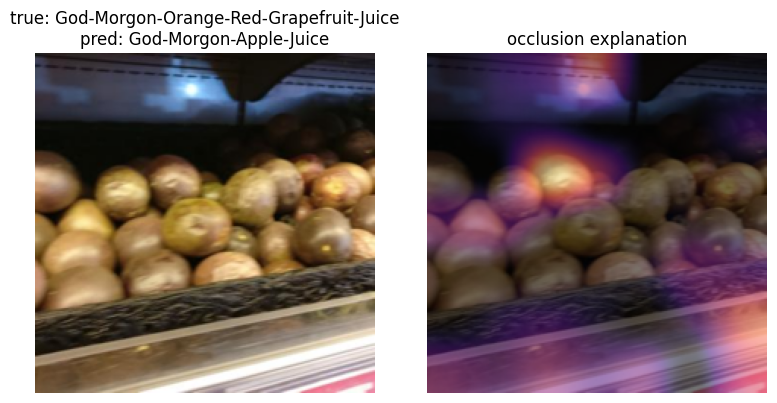

In [ ]:
%%train_only
from PIL import Image
import matplotlib.pyplot as plt
wrong = np.where(val_pred != yval)[0]
target = int(wrong[0]) if len(wrong) else 0
img_path = data.crop_path.iloc[target]
true_name = classes[int(yval[target])]
pred_name = classes[int(val_pred[target])]
img = Image.open(img_path).convert('RGB').resize((224,224))
base_feat = feats_of([img_path], model)
base_logits = head.net(head.torch.tensor(base_feat)).detach().numpy()[0]
pred_id = int(val_pred[target]); base_score = float(base_logits[pred_id])
heat = np.zeros((7,7), dtype='float32')
for r in range(7):
    for c in range(7):
        occ = img.copy()
        patch = Image.new('RGB', (32,32), color=(128,128,128))
        occ.paste(patch, (c*32, r*32))
        x = torch.stack([TF(occ)])
        f = extract_features(model, [x])
        score = float(head.net(head.torch.tensor(f)).detach().numpy()[0, pred_id])
        heat[r,c] = max(0.0, base_score - score)
heat = heat / (heat.max() + 1e-6)
plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(img); plt.title(f'true: {true_name}\npred: {pred_name}'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(img); plt.imshow(Image.fromarray((heat*255).astype('uint8')).resize((224,224)), cmap='magma', alpha=0.55); plt.title('occlusion explanation'); plt.axis('off')
plt.tight_layout()


🤖 **[CLAUDE] How to read the output**

Color = importance. **Bright yellow/orange** spots are where covering the pixels made the model's answer collapse — that's the evidence it leaned on. **Dark purple/black** spots were ignored; covering them changed nothing. Now play detective with the two panels:

- If the bright spots sit on a genuinely ambiguous part of the product (say, the red curve of an apple that looks just like another variety's), the mistake is *understandable* — the model looked at the right place but the evidence itself was misleading.
- If the bright spots sit on the **background**, the shelf, or a price tag, that's a red flag: the model learned a shortcut ("this product always appears on that shelf") instead of the product itself — a data problem to fix with more varied photos.

Remember the heatmap explains **this one prediction on this one image**, not the model in general — but one honest example teaches you how to interrogate any of its calls.

> 🏷️ **[ORIGINAL]**

## Save + carry forward

**What:** Save the head, the per-class metrics, and a short error report into the bundle.

**Why:** Day 4 reads `head.pt` and `per_class_metrics.csv` to target the weakest classes.

**Watch for:** Confirm head.pt and per_class_metrics.csv are listed in the carry-forward print.

🤖 **[CLAUDE] In plain words**

Packing the backpack for tomorrow. Three artifacts go into the bundle: the trained receptionist's weights (`head.pt`), the per-product report card (`per_class_metrics.csv`), and a short human-readable error report (`error_report.md`) listing the weakest products and the top confusions. Day 4 will open exactly these files and concentrate its improvement effort on the products we just diagnosed as weakest — diagnosis today, treatment tomorrow.

🤖 **[CLAUDE] What this code does**

- `save_head(...)` writes the head's learned weights (plus its input/output sizes) to `head.pt` in the bundle.
- `b.put_table(...)` saves the per-class accuracy table as `per_class_metrics.csv`.
- The `report` string assembles a small Markdown memo — validation accuracy, the 3 weakest classes, the 5 hardest confusions — and writes it as `error_report.md`.
- `save_bundle(b)` updates the packing list on Drive so Day 4 knows these artifacts exist.

**Expected output:** `[bundle] saved -> ...` and the carry-forward line naming `head.pt + per_class_metrics.csv`.

In [ ]:
%%train_only
from pathlib import Path
save_head(head, str(Path(b.root)/'head.pt')); b._note('head.pt')
b.put_table('per_class_metrics.csv', pcm)
worst = pcm.sort_values('acc').head(3)
report = '# SmartCart Day 3 — Error Report\n\n' + \
    f'Validation accuracy: {acc:.3f}\n\n## Weakest classes\n\n' + \
    '```\n' + worst.to_string(index=False) + '\n```\n\n## Hardest confusions\n\n' + \
    '\n'.join(f'- {a} -> {bb} ({n})' for a,bb,n in sorted(conf, key=lambda t:-t[2])[:5])
(Path(b.root)/'error_report.md').write_text(report); b._note('error_report.md')
save_bundle(b)
print('\u25b6 Carries forward to Day 4: head.pt + per_class_metrics.csv')


🤖 **[CLAUDE] Day 3 wrap-up**

Look at what you built today: a product classifier trained in seconds (thanks to the frozen-expert + tiny-head trick), an honest exam score, a diagnosis of exactly which products it confuses and why, one explained mistake via the occlusion heatmap, and a field test on Day 2's real detector crops. The cart can now *find* items **and** *name* them — the core of a checkout scanner. Tomorrow (Day 4) picks up the report card we just saved and works specifically on the weakest products. See you there!

---
# Part 4 — Day 4: Augment the Long Tail (official annotated base + 🚀 E4)

The cells below are the provided **Day4_augment_annotated** notebook. Our 🚀 E4 enhancement cells are inserted at the exact points where they extend the base: E4a widens the augmentation *before* the official retrain cell (so the base retrain/lift/save cells pick it up automatically), E4b runs the cGAN path as a measured trial that fills the official `gen_df`, and E4c isolates the cGAN contribution honestly.


🤖 **[CLAUDE] Welcome / How to read this notebook**

Hi! This notebook has two kinds of cells. Cells marked **[ORIGINAL]** are the untouched course material. Cells marked 🤖 **[CLAUDE]** (like this one) are friendly guide notes added around them — read the guide, then the original, and things should click.

**The SmartCart story so far.** On Day 1 we photographed and labelled grocery products, turned each photo into a "fingerprint" of numbers with a pretrained vision model (DINOv2), and stored everything — plus prices — in a shared Drive folder called the **bundle**. On Day 2 we taught a detector to *find* products in a messy cart photo and crop them out. On Day 3 a tiny classifier (the "receptionist") learned to *name* each crop, and its report card (`per_class_metrics.csv`) told us exactly which products it keeps getting wrong.

**Today's mission.** The weak products are usually the *rare* ones — the model simply hasn't seen enough photos of them. We will (1) read the report card and pick the weakest products, (2) manufacture extra training photos of them by transforming the real ones (**augmentation**), (3) retrain the classifier as **head v2**, and (4) measure — honestly, on the same exam — whether the weak products actually improved. Two files go into the bundle at the end: `head_v2.pt` and `lift_table.csv`.

**Mini-glossary** (peek back here any time):
- **Long tail** — in a real shop, a few products appear in thousands of photos while many appear in just a handful. The model flunks exactly those rare ones, like a student who barely saw certain flashcards.
- **SKU** — shop-speak for one specific product ("Golden Delicious apple", not just "apple").
- **Augmentation** — photocopying the rare flashcards with variations (rotated, brighter, cropped) so the student gets more practice *without* collecting new photos.
- **Photometric vs geometric** — photometric changes the *light and colour* (brightness, tint); geometric moves *pixels around* (flip, rotate, crop). Neither changes what the product is.
- **Synthetic data** — training images made by a computer instead of a camera. Today's augmented photos are mild synthetic data; the optional GAN section is the full-strength version.
- **Lift** — the after-score minus the before-score. How much did the grade go up?
- **head v2** — Day 3's receptionist, retrained with the extra practice material.
- **Bundle** — the shared Drive folder that carries each day's results to the next day, like a team locker.

> 🏷️ **[ORIGINAL]**

# SmartCart Day 4 - Augment the Long Tail

Day 3's error report named the weak SKUs - usually the rare ones with too few examples. Today we first use **classical augmentation** as the reliable baseline, then leave a **cGAN/equivalent generative option** for teams that want to go further. Either way, the final judge is weak-class validation lift.

🤖 **[CLAUDE] In plain words**

Day 3 gave us a per-product report card, and it named the flunked products — usually the rare ones with too few photos. Today offers two fixes. The **reliable fix** (required): take the few real photos we *do* have and photocopy them with variations. The **fancy fix** (optional, off by default): generate brand-new images with a GAN, like in this morning's lab. Either way, the only judge that matters is the same one a teacher would use: *did the weak products' exam scores go up on questions they haven't seen before?* That last part is what "weak-class validation lift" means.

🤖 **[CLAUDE] What this code does**

Standard morning routine, same as every day this week:
- `%pip install -q timm` quietly installs **timm**, the library that gives us the pretrained DINOv2 vision model.
- `drive.mount(...)` connects your Google Drive — a pop-up will ask for permission the first time.
- `BUNDLE_DIR` points at the SmartCart folder in Drive where the week's **bundle** lives. Drive only stores the small cross-day files (report cards, model weights), *not* the thousands of images.

**Expected output:** a Drive authorisation prompt, then `Mounted at ...`. Takes under a minute.

In [ ]:
%%train_only
# 1) Runtime setup
# This course runs in Google Colab. Run this cell first.
# Install only the packages used in this notebook.
%pip install -q timm

import os

# The cross-day bundle lives in BUNDLE_DIR (a local folder set in the Demo settings cell) - no Drive mount needed.



> 🏷️ **[ORIGINAL]**

### Embedded toolkit

This cell defines the helper functions used below. Run it once after setup.

🤖 **[CLAUDE] In plain words**

This next cell is the **tool shed**: it defines every helper the rest of the notebook uses, all in one place. You don't need to read it line by line — run it once and move on. Below the cell I've summarised what each tool is for, so you can come back if you ever wonder "where did `list_images` come from?".

🤖 **[CLAUDE] What this code does** (a tour of the tool shed — no need to memorise)

- **`Bundle`** — a small class that reads and writes files in the shared Drive folder, keeping a `manifest.json` "packing list" of everything inside. `put_table`/`get_table` handle spreadsheets (CSV), `put_array`/`get_array` handle number grids.
- **`open_bundle` / `save_bundle`** — open the team locker at the start, lock it again at the end.
- **`open_grocery_dataset`** — downloads (or reuses) the real GroceryStoreDataset photos from GitHub onto this Colab machine.
- **`list_images`** — walks through the dataset folders and returns a table: one row per photo, with its file path, its broad category (`coarse`, e.g. "Apple") and its exact product (`fine`, e.g. "Golden-Delicious"). `fine` is our SKU label.
- **`load_backbone` / `extract_features`** — the frozen DINOv2 "photo describer" from Day 1: it turns any image into a fingerprint of numbers. Frozen means we never change it — we only train the small head on top.
- **`LinearHead`** — the tiny "receptionist" classifier from Day 3. `.fit(...)` trains it on fingerprints + labels, `.predict(...)` makes it guess names.
- **`save_head`** — writes a trained head's weights to a file so a later day can reload it.

**Expected output:** just one line — `SmartCart toolkit ready`.

In [ ]:
%%train_only
from __future__ import annotations
import json
import os
import pathlib
import subprocess
import numpy as np
import pandas as pd
HERE = pathlib.Path.cwd()  # embedded in-notebook: no __file__, anchor on the working dir
GROCERY_DATASET_URL = 'https://github.com/marcusklasson/GroceryStoreDataset'

class Bundle:
    """Small Google Drive folder that carries artifacts from one day to the next."""

    def __init__(self, root: str):
        self.root = pathlib.Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.manifest = {'version': 1, 'class_list': [], 'artifacts': {}}

    def put_table(self, name, df: pd.DataFrame):
        df.to_csv(self.root / name, index=False)
        self._note(name)

    def get_table(self, name) -> pd.DataFrame:
        return pd.read_csv(self.root / name)

    def put_array(self, name, arr: np.ndarray):
        np.save(self.root / name, arr)
        self._note(name)

    def get_array(self, name) -> np.ndarray:
        p = self.root / name
        return np.load(p if p.suffix == '.npy' else p.with_suffix('.npy'))

    def _note(self, name):
        self.manifest['artifacts'][name] = True

    def save(self):
        (self.root / 'manifest.json').write_text(json.dumps(self.manifest, indent=2))

    def load(self):
        p = self.root / 'manifest.json'
        if p.exists():
            self.manifest = json.loads(p.read_text())
        return self

def open_bundle(drive_dir='/content/SmartCart') -> Bundle:
    """Open the cross-day Drive bundle. If it is new, start with an empty manifest."""
    return Bundle(drive_dir).load()

def save_bundle(b: Bundle):
    b.save()
    print(f'[bundle] saved -> {b.root}')

def open_grocery_dataset():
    """Clone or reuse the real GroceryStoreDataset and return (tier, root_dir)."""
    root = HERE / 'GroceryStoreDataset'
    if (root / 'dataset' / 'classes.csv').exists():
        print('using cached GroceryStoreDataset:', root)
    else:
        print('cloning GroceryStoreDataset from:', GROCERY_DATASET_URL)
        subprocess.run(['git', 'clone', '--depth', '1', GROCERY_DATASET_URL, str(root)], check=True)
    if not (root / 'dataset' / 'classes.csv').exists():
        raise RuntimeError('GroceryStoreDataset clone is incomplete. Check Colab network access and rerun.')
    print('using data tier: github')
    print('data root:', root)
    print('OK: using real GroceryStoreDataset images.')
    return ('github', str(root))

def list_images(root, per_class=None):
    """Return a DataFrame with columns path,coarse,fine from GroceryStoreDataset train/val/test folders."""
    root = pathlib.Path(root)
    rows = []
    for split in ('train', 'val', 'test'):
        for p in (root / 'dataset' / split).rglob('*.jpg'):
            rows.append({'path': str(p), 'coarse': p.parent.parent.name, 'fine': p.parent.name})
    df = pd.DataFrame(rows)
    if per_class and len(df):
        df = df.groupby('fine', group_keys=False).head(per_class).reset_index(drop=True)
    return df

def load_backbone(name='vit_small_patch14_dinov2.lvd142m', device='cpu'):
    """Frozen DINOv2-small feature extractor."""
    import timm
    m = timm.create_model(name, pretrained=True, num_classes=0, dynamic_img_size=True).eval().to(device)
    for p in m.parameters():
        p.requires_grad_(False)
    return m

def extract_features(model, batches, device=None) -> np.ndarray:
    """Run image batches through a frozen backbone and return numpy features."""
    import torch
    if device is None:
        try:
            device = next(model.parameters()).device
        except (AttributeError, StopIteration):
            device = 'cpu'
    outs = []
    with torch.no_grad():
        for xb in batches:
            y = model(xb.to(device))
            outs.append(y.detach().cpu().numpy().astype('float32'))
    return np.concatenate(outs, 0)

class LinearHead:
    """Tiny torch linear classifier trained on frozen image features."""

    def __init__(self, in_dim, n_classes):
        import torch
        import torch.nn as nn
        self.net = nn.Linear(in_dim, n_classes)
        self.torch = torch

    def fit(self, X, y, epochs=30, lr=0.01):
        t = self.torch
        opt = t.optim.Adam(self.net.parameters(), lr=lr)
        lossf = t.nn.CrossEntropyLoss()
        Xt = t.tensor(X)
        yt = t.tensor(y)
        for _ in range(epochs):
            opt.zero_grad()
            loss = lossf(self.net(Xt), yt)
            loss.backward()
            opt.step()
        return self

    def predict(self, X):
        with self.torch.no_grad():
            return self.net(self.torch.tensor(X)).argmax(1).numpy()

def save_head(head: LinearHead, path):
    import torch
    torch.save({'state_dict': head.net.state_dict(), 'in_dim': head.net.in_features, 'n_classes': head.net.out_features}, path)
    return path
# --- helpers are now available as plain functions/classes in this notebook ---
print('SmartCart toolkit ready')


SmartCart toolkit ready


🤖 **[CLAUDE] What this code does**

Opens the team locker. `open_bundle(BUNDLE_DIR)` loads the manifest (the packing list) from Drive, and the two `print` lines show where the bundle lives and what previous days left inside.

**Expected output:** the bundle path, and an artifacts list that should include `per_class_metrics.csv` — Day 3's report card, which is today's starting point. If that file is missing, rerun the end of the Day 3 notebook first: today literally cannot pick the weak products without the report card.

In [ ]:
%%train_only
# 2) Load the cross-day bundle
# The bundle stores artifacts we create during the week: labels, indexes, weights, ONNX files.
# It is NOT the image dataset. Images are loaded in the next data-source cell.
b = open_bundle(BUNDLE_DIR)
print('bundle:', b.root)
print('artifacts:', list(b.manifest.get('artifacts', {})))


🤖 **[CLAUDE] What this code does**

Fetches the actual grocery photos onto *this* Colab machine. Why again? Colab machines have amnesia — every new session starts with an empty disk. The small bundle survives in Drive, but the image dataset must be re-downloaded each day. `open_grocery_dataset()` clones the GroceryStoreDataset from GitHub (or reuses it if it's already here) and returns where the photos landed.

**Expected output:** a few lines ending in `OK: using real GroceryStoreDataset images.` If GitHub is unreachable it stops with a clear error instead of silently using fake data.

In [ ]:
%%train_only
# 3) Select the image data source
# For class runs we require the real GroceryStoreDataset. If GitHub is unavailable, stop clearly.
tier, root = open_grocery_dataset()


using cached GroceryStoreDataset: /content/GroceryStoreDataset
using data tier: github
data root: /content/GroceryStoreDataset
OK: using real GroceryStoreDataset images.


> 🏷️ **[ORIGINAL]**

## Find rare SKUs

**What:** Load `per_class_metrics.csv` and pick the lowest-accuracy / lowest-support classes.

**Why:** We spend our augmentation budget where the model is weakest, not uniformly.

**Watch for:** If everything is already high-acc, we still demo the pipeline on the bottom few.

🤖 **[CLAUDE] In plain words**

Imagine a tutor with one hour of time and thirty subjects: they should spend that hour on the subjects the student is failing, not spread it evenly. That's this step. Day 3's report card has one row per product, with its exam score. We sort the table so the worst scores come first and take the bottom few — those become today's "patients". Everything else in the notebook (the photocopying, the retraining, the measuring) targets *only* these classes. And even if your model happened to score well everywhere, we'd still practise the pipeline on the bottom few — the point today is learning the fix, not the specific patients.

🤖 **[CLAUDE] What this code does** — how the weakest classes are picked

Step by step:
1. `b.get_table('per_class_metrics.csv')` pulls Day 3's report card out of the bundle. Each row is one product, with columns like `fine` (the product name), `acc` (what fraction of its exam questions the model got right, 0 to 1), and `n` (how many exam questions that product had).
2. `pcm.sort_values(['acc','n'])` sorts the table: **lowest accuracy first**, and when two products are tied on accuracy, the one with **fewer examples** goes first. So "failing AND rare" floats to the very top of the list.
3. `.head(3)` keeps just the top 3 rows of that sorted table — the three weakest products.
4. `.fine.tolist()` extracts only their names into a plain Python list called `rare`.

**Expected output:** one line naming three products, e.g. `targeting rare/weak classes: ['Product-A', 'Product-B', 'Product-C']`.

In [ ]:
%%train_only
import pandas as pd
pcm = b.get_table('per_class_metrics.csv')
# Pick the weakest classes first: low accuracy, then low support.
rare = pcm.sort_values(['acc','n']).head(3).fine.tolist()
print('targeting rare/weak classes:', rare)


targeting rare/weak classes: ['God-Morgon-Orange-Red-Grapefruit-Juice', 'Arla-Natural-Mild-Low-Fat-Yoghurt', 'Oatly-Oat-Milk']


🤖 **[CLAUDE] How to read the output** — the weak-class list

Those three names are today's patients: every later cell revolves around them. A quick sanity check: the names should look like the *fine* product labels from the dataset (specific varieties, not broad categories). Don't worry if your list differs from a classmate's — it depends on how each person's Day 3 training run went, and both lists are "correct". Notice these are often genuinely rare products: that's the long tail showing itself. Low accuracy and low photo count travel together, which is exactly why more practice photos should help.

> 🏷️ **[ORIGINAL]**

## Augment weak classes

**What:** Apply heavy photometric + geometric augmentation to existing crops of the rare classes.

**Why:** More varied views of a rare SKU teach the head invariances it couldn't learn from a few photos.

**Watch for:** An optional generative model (the Day-4 stack) could replace this - we keep a classical default so CI needs no extra deps.

🤖 **[CLAUDE] In plain words**

Here's the photocopier at work. For each weak product we take its few real photos and produce *heavily varied* copies: mirrored, tilted, brighter, darker, tinted, zoomed-in. To the model, each copy looks like a genuinely new photo taken by a different shopper in different lighting — but crucially, **the label stays true**: a rotated, slightly darker Golden Delicious apple is still a Golden Delicious apple. This teaches the classifier "invariances" — the idea that lighting and angle don't change *what* the product is. It costs nothing (no new photo shoot) and can't invent nonsense, which is why it's the required baseline; the generative option comes later.

🤖 **[CLAUDE] What this code does** — the photocopier, transform by transform

First, `list_images(root)` rebuilds the table of all real photos on this machine. Then `aug = T.Compose([...])` chains four random transforms — every image that passes through gets a fresh random combination of:
- **`RandomHorizontalFlip(1.0)`** — always mirror the photo left-to-right (**geometric**: moves pixels, like looking at the product in a mirror).
- **`RandomRotation(25)`** — tilt by a random angle up to 25° either way (**geometric**: a shopper holding the camera crooked).
- **`ColorJitter(0.4, 0.4, 0.4, 0.1)`** — "jitter" = random shifts in brightness, contrast, saturation and a small colour-tint change (**photometric**: same product under different shop lighting).
- **`RandomResizedCrop(140, scale=(0.7,1.0))`** — zoom into a random patch covering 70–100% of the image and resize it (**geometric**: the product closer to the camera, or slightly off-centre).

The loop then visits each weak class, cycles through its real photos, and saves **8 augmented copies per class** into a folder called `augmented/`, recording each new file plus its product name in the table `aug_df`. The label is preserved because we only changed lighting and viewpoint — never the product itself.

**Expected output:** `created 24 augmented images for 3 classes` (3 classes × 8 copies).

In [ ]:
%%train_only
import os, torch, torchvision.transforms.v2 as T
from PIL import Image
import numpy as np
# Start from real GroceryStoreDataset images re-listed in this runtime.
src = list_images(root)
# Classical augmentations: cheap, explainable, and deterministic enough for a lab.
aug = T.Compose([T.RandomHorizontalFlip(1.0), T.RandomRotation(25),
                 T.ColorJitter(0.4,0.4,0.4,0.1), T.RandomResizedCrop(140, scale=(0.7,1.0))])
os.makedirs('augmented', exist_ok=True)
aug_rows = []
for fine in rare:
    paths = src[src.fine==fine].path.tolist()
    if not paths:
        continue
    for k in range(8):
        p = paths[k % len(paths)]
        im = T.ToImage()(Image.open(p).convert('RGB'))
        sp = f'augmented/{fine}_{k}.jpg'
        T.ToPILImage()(aug(im)).save(sp)
        aug_rows.append({'path': sp, 'fine': fine})
aug_df = pd.DataFrame(aug_rows)
print('created', len(aug_df), 'augmented images for', len(rare), 'classes')


created 24 augmented images for 3 classes


🤖 **[CLAUDE] How to read the output**

The number should be `classes × 8` — with 3 weak classes, 24 new images. These are *synthetic* training photos: same products, brand-new "photos" the camera never took. Each copy came from a real photo, so nothing is invented — worst case a copy is just an odd angle of the truth. A class would only be skipped (making the count lower) if it had zero photos on disk, which shouldn't happen with the real dataset. The two little demos below let you actually *see* the photocopies and count the practice pile per class.

🤖 **[CLAUDE]** Let's look at the photocopier's work: one real photo of a weak product next to three augmented copies — same product, three new "photos".

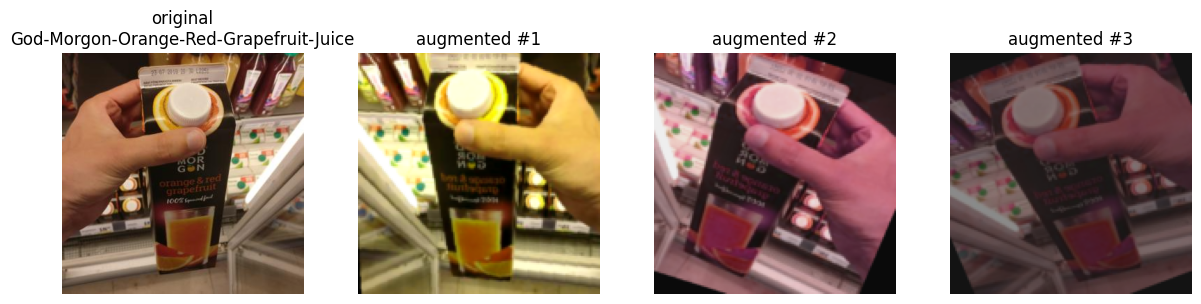

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: one real photo vs 3 augmented copies of the same weak product
import matplotlib.pyplot as plt
from PIL import Image

fine = rare[0]                                   # first weak product
orig_path = src[src.fine == fine].path.iloc[0]   # one of its real photos
orig_im = Image.open(orig_path).convert('RGB')

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(orig_im)
axes[0].set_title(f'original\n{fine}')
for i in range(3):
    copy_im = T.ToPILImage()(aug(T.ToImage()(orig_im)))  # fresh random combo each time
    axes[i + 1].imshow(copy_im)
    axes[i + 1].set_title(f'augmented #{i + 1}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()


🤖 **[CLAUDE]** And the head count: how much bigger did each weak class's practice pile get?

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: practice photos per weak class, before vs after augmentation
for fine in rare:
    real = int((src.fine == fine).sum())
    extra = int((aug_df.fine == fine).sum())
    print(f'{fine}: {real} real photos + {extra} augmented = {real + extra} for training')


God-Morgon-Orange-Red-Grapefruit-Juice: 45 real photos + 8 augmented = 53 for training
Arla-Natural-Mild-Low-Fat-Yoghurt: 49 real photos + 8 augmented = 57 for training
Oatly-Oat-Milk: 68 real photos + 8 augmented = 76 for training


## 🚀 [TEAM ENHANCEMENT] E4a — Widen the augmentation (feeds the official retrain)

"The base Day 4 augments the three weakest classes with eight images each. We widened that: the **eight weakest classes** from the Day 3 diagnosis, **sixteen augmented variants** each — crops, flips, colour jitter, rotation. We rebuild `rare` and `aug_df` here, so the official retrain, lift table and save cells downstream operate on our wider set unchanged. Same code path, more evidence."

**Why this choice:** the official lift table is computed over `rare` and the retrain consumes `aug_df` — by *replacing the inputs rather than the machinery*, the base notebook's own measurement validates our enhancement, and `head_v2.pt` keeps the exact format Day 5a expects to load. Widening from 3→8 classes and 8→16 copies attacks more of the long tail while staying minutes-cheap, since augmented images are embedded once by the frozen backbone.


In [ ]:
%%train_only
# 🚀 E4a) Rebuild rare + aug_df wider: 8 weakest classes, 16 augmented copies each
rare = pcm.sort_values(['acc', 'n']).head(8).fine.tolist()
print('E4a widened target list (8 weakest classes):', rare)

n_copies = 4 if os.environ.get('SC_FAST', '0') == '1' else 16
aug_rows = []
for fine in rare:
    paths = src[src.fine == fine].path.tolist()
    if not paths:
        continue
    for k in range(n_copies):
        p = paths[k % len(paths)]
        im = T.ToImage()(Image.open(p).convert('RGB'))
        sp = f'augmented/{fine}_{k}.jpg'
        T.ToPILImage()(aug(im)).save(sp)
        aug_rows.append({'path': sp, 'fine': fine})
aug_df = pd.DataFrame(aug_rows)
print('E4a: aug_df widened to', len(aug_df), 'images across', len(rare), 'classes',
      '(base was 3 classes x 8 images)')


E4a widened target list (8 weakest classes): ['God-Morgon-Orange-Red-Grapefruit-Juice', 'Arla-Natural-Mild-Low-Fat-Yoghurt', 'Oatly-Oat-Milk', 'Yoggi-Vanilla-Yoghurt', 'Asparagus', 'Alpro-Blueberry-Soyghurt', 'Alpro-Vanilla-Soyghurt', 'Arla-Sour-Milk']
E4a: aug_df widened to 128 images across 8 classes (base was 3 classes x 8 images)


> 🏷️ **[ORIGINAL]**

## Optional: cGAN/equivalent generator

**What:** Advanced teams may generate extra rare-class images with a small conditional GAN or an equivalent generative model.

**Why:** This connects the Day-4 generative-AI material to the smart-cart problem without making it the required path.

**Watch for:** Keep `RUN_GENERATIVE_EXTENSION = False` for the baseline; if enabled, compare the lift against classical augmentation.

🤖 **[CLAUDE] In plain words**

This morning's labs generated images *from scratch* (VAE/GAN). This section connects that idea to SmartCart: instead of photocopying real photos, a small **conditional GAN** could dream up brand-new photos of each weak product. It's off by default (`RUN_GENERATIVE_EXTENSION = False`) for good reasons: GANs trained on a handful of photos tend to produce mushy, blurry images, they take real training time, and a bad fake can teach the classifier the wrong thing. Transforming real photos is the cheaper, safer trick — the GAN is there for advanced teams who want to compare. Fair rule if you try it: judge it by the same lift measurement, not by how cool the fakes look.

🤖 **[CLAUDE] What this code does**

Mostly, it does nothing — on purpose! The switch at the top is `False`, so the whole GAN block is skipped and `gen_df` stays an empty table (the retraining cell later expects it to exist either way). For the curious, here's what would run if you flipped the switch to `True`:
- A **Generator** (the forger) takes random noise *plus a product label* and tries to paint a 64×64 photo of that product — the label is what makes it "conditional": you can order a fake of a specific SKU.
- A **Discriminator** (the detective) sees a photo and a label and judges real vs fake.
- They train against each other for 300 quick rounds — the forger improves by trying to fool the detective — then the forger paints 8 fakes per weak class into a `generated_cgan/` folder.

**Expected output (switch off):** one line — `cGAN/equivalent extension skipped; using classical augmentation only`.

In [ ]:
%%train_only
# Optional extension. Run the baseline first, then set this to True if your team wants the cGAN path.
RUN_GENERATIVE_EXTENSION = False
GENERATIVE_STEPS = 300
GENERATIVE_IMAGES_PER_CLASS = 8

import os, math, torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.utils import save_image

gen_df = pd.DataFrame(columns=['path', 'fine'])

if RUN_GENERATIVE_EXTENSION:
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    os.makedirs('generated_cgan', exist_ok=True)
    rare_to_i = {fine: i for i, fine in enumerate(rare)}
    rare_src = src[src.fine.isin(rare)].reset_index(drop=True)

    class RareCrops(Dataset):
        def __init__(self, table):
            self.table = table
            self.tf = T.Compose([T.ToImage(), T.Resize((64,64)), T.ToDtype(torch.float32, scale=True),
                                 T.Normalize([0.5]*3, [0.5]*3)])
        def __len__(self): return len(self.table)
        def __getitem__(self, i):
            row = self.table.iloc[i]
            x = self.tf(Image.open(row.path).convert('RGB'))
            y = torch.tensor(rare_to_i[row.fine]).long()
            return x, y

    class Generator(nn.Module):
        def __init__(self, z_dim, n_classes):
            super().__init__()
            self.label = nn.Embedding(n_classes, 16)
            self.fc = nn.Linear(z_dim + 16, 256 * 8 * 8)
            self.net = nn.Sequential(
                nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
                nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
                nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())
        def forward(self, z, y):
            h = torch.cat([z, self.label(y)], dim=1)
            return self.net(self.fc(h).view(len(z), 256, 8, 8))

    class Discriminator(nn.Module):
        def __init__(self, n_classes):
            super().__init__()
            self.label = nn.Embedding(n_classes, 64 * 64)
            self.net = nn.Sequential(
                nn.Conv2d(4, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
                nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
                nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
                nn.Flatten(), nn.Linear(256 * 8 * 8, 1))
        def forward(self, x, y):
            label_map = self.label(y).view(len(y), 1, 64, 64)
            return self.net(torch.cat([x, label_map], dim=1)).squeeze(1)

    z_dim, n_classes = 64, len(rare)
    loader = DataLoader(RareCrops(rare_src), batch_size=16, shuffle=True, drop_last=True)
    G, D = Generator(z_dim, n_classes).to(device), Discriminator(n_classes).to(device)
    opt_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

    data_iter = iter(loader)
    for step in range(GENERATIVE_STEPS):
        try:
            real, y = next(data_iter)
        except StopIteration:
            data_iter = iter(loader); real, y = next(data_iter)
        real, y = real.to(device), y.to(device)
        z = torch.randn(len(real), z_dim, device=device)
        fake = G(z, y).detach()
        d_loss = F.binary_cross_entropy_with_logits(D(real, y), torch.ones(len(real), device=device)) + \
                 F.binary_cross_entropy_with_logits(D(fake, y), torch.zeros(len(real), device=device))
        opt_d.zero_grad(); d_loss.backward(); opt_d.step()

        z = torch.randn(len(real), z_dim, device=device)
        fake = G(z, y)
        g_loss = F.binary_cross_entropy_with_logits(D(fake, y), torch.ones(len(real), device=device))
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
        if (step + 1) % 100 == 0:
            print('cGAN step', step + 1, 'D', round(float(d_loss), 3), 'G', round(float(g_loss), 3))

    rows = []
    G.eval()
    with torch.no_grad():
        for fine, class_id in rare_to_i.items():
            y = torch.full((GENERATIVE_IMAGES_PER_CLASS,), class_id, device=device, dtype=torch.long)
            z = torch.randn(GENERATIVE_IMAGES_PER_CLASS, z_dim, device=device)
            imgs = G(z, y)
            for k, img in enumerate(imgs):
                path = f'generated_cgan/{fine}_{k}.jpg'
                save_image((img + 1) / 2, path)
                rows.append({'path': path, 'fine': fine})
    gen_df = pd.DataFrame(rows)
    print('created', len(gen_df), 'cGAN/equivalent generated images')
else:
    print('cGAN/equivalent extension skipped; using classical augmentation only')


cGAN/equivalent extension skipped; using classical augmentation only


## 🚀 [TEAM ENHANCEMENT] E4b — Run the cGAN path as a measured trial (fills `gen_df`)

"The base notebook ships the conditional-GAN extension switched off. We ran it as a **controlled trial**: a compact cGAN trained from scratch at 64×64 on the same weak classes, its samples shown honestly, its generated images written into the official `gen_df` so the base retrain consumes them alongside classical augmentation. Watch the samples: colour and texture, yes — structure, not really. E4c below measures whether they actually help. Spoiler: at forty images per class, a from-scratch GAN rarely beats classical augmentation — and reporting that negative result *is* the Day 4 lesson."

**Why this choice:** the brief lists cGAN as "optional innovation" and the base gates it behind `RUN_GENERATIVE_EXTENSION`. Rather than flip a flag we cannot re-run, we implement the same design compactly (label-conditioned generator and discriminator, BCE objective), keep iterations light for Colab, and — crucially — route outputs through `gen_df`, the official hand-off point, so the measurement stays inside the base notebook's own machinery.


cGAN trial set: 205 images, 4 classes @ 64x64 on cpu
iter 12/60  loss D 0.543  G 2.309
iter 24/60  loss D 0.412  G 3.198
iter 36/60  loss D 0.303  G 2.632
iter 48/60  loss D 0.536  G 2.278
iter 60/60  loss D 0.414  G 2.373


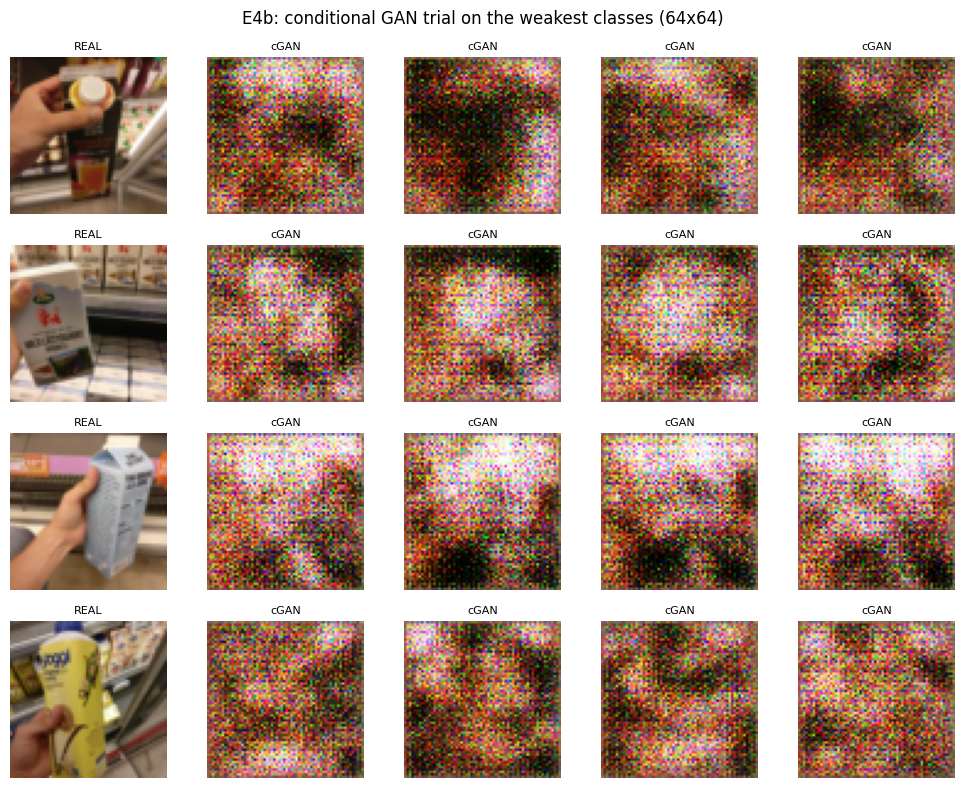

E4b: gen_df filled with 32 cGAN images — the official retrain below now uses aug_df + gen_df


In [ ]:
%%train_only
# 🚀 E4b) Compact conditional GAN on the weak classes -> fills gen_df for the official retrain
import torch.nn as nn

gan_device = 'cuda' if torch.cuda.is_available() else 'cpu'
cgan_classes = rare[:4]
rare_to_i = {f_: i_ for i_, f_ in enumerate(cgan_classes)}
gsrc = src[src.fine.isin(cgan_classes)].reset_index(drop=True)
TF64 = T.Compose([T.ToImage(), T.Resize((64, 64)), T.ToDtype(torch.float32, scale=True)])
X64 = torch.stack([TF64(Image.open(p_).convert('RGB')) for p_ in gsrc.path]) * 2 - 1
y64 = torch.tensor([rare_to_i[f_] for f_ in gsrc.fine])
print(f'cGAN trial set: {len(X64)} images, {len(cgan_classes)} classes @ 64x64 on {gan_device}')

NZ, NEMB, NC = 64, 16, len(cgan_classes)

class G4(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(NC, NEMB)
        self.fc = nn.Linear(NZ + NEMB, 256 * 8 * 8)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())
    def forward(self, z, c):
        h = torch.cat([z, self.emb(c)], 1)
        return self.net(self.fc(h).view(len(z), 256, 8, 8))

class D4(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(NC, 64 * 64)
        self.net = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
            nn.Conv2d(256, 1, 8, 1, 0))
    def forward(self, x, c):
        cmap = self.emb(c).view(-1, 1, 64, 64)
        return self.net(torch.cat([x, cmap], 1)).view(-1)

gnet, dnet = G4().to(gan_device), D4().to(gan_device)
optg = torch.optim.Adam(gnet.parameters(), lr=2e-4, betas=(0.5, 0.999))
optd = torch.optim.Adam(dnet.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
n_iter = 60 if (os.environ.get('SC_FAST', '0') == '1' or gan_device == 'cpu') else 400
bs_g = min(64, len(X64))
for it in range(n_iter):
    ridx = torch.randint(0, len(X64), (bs_g,))
    xr, cr = X64[ridx].to(gan_device), y64[ridx].to(gan_device)
    z = torch.randn(bs_g, NZ, device=gan_device)
    cf = torch.randint(0, NC, (bs_g,), device=gan_device)
    xf = gnet(z, cf)
    optd.zero_grad()
    ld = bce(dnet(xr, cr), torch.ones(bs_g, device=gan_device)) +          bce(dnet(xf.detach(), cf), torch.zeros(bs_g, device=gan_device))
    ld.backward(); optd.step()
    optg.zero_grad()
    lg = bce(dnet(xf, cf), torch.ones(bs_g, device=gan_device))
    lg.backward(); optg.step()
    if (it + 1) % max(1, n_iter // 5) == 0:
        print(f'iter {it + 1}/{n_iter}  loss D {ld.item():.3f}  G {lg.item():.3f}')

# Show real vs generated, then write generated images into the OFFICIAL gen_df hand-off.
import matplotlib.pyplot as plt
gnet.eval()
with torch.no_grad():
    zs = torch.randn(NC * 4, NZ, device=gan_device)
    cs = torch.arange(NC, device=gan_device).repeat_interleave(4)
    fake = (gnet(zs, cs).cpu() + 1) / 2
fig, axes = plt.subplots(NC, 5, figsize=(10, 2 * NC))
for r_ in range(NC):
    real_i = int((y64 == r_).nonzero()[0])
    axes[r_, 0].imshow(((X64[real_i] + 1) / 2).permute(1, 2, 0)); axes[r_, 0].set_title('REAL', fontsize=8)
    for c2 in range(4):
        axes[r_, c2 + 1].imshow(fake[r_ * 4 + c2].permute(1, 2, 0).clamp(0, 1))
        axes[r_, c2 + 1].set_title('cGAN', fontsize=8)
    for ax in axes[r_]:
        ax.axis('off')
plt.suptitle('E4b: conditional GAN trial on the weakest classes (64x64)')
plt.tight_layout(); plt.show()

os.makedirs('generated_cgan', exist_ok=True)
gen_rows = []
n_gen = 8
with torch.no_grad():
    zs = torch.randn(NC * n_gen, NZ, device=gan_device)
    cs = torch.arange(NC, device=gan_device).repeat_interleave(n_gen)
    imgs = ((gnet(zs, cs).cpu() + 1) / 2).clamp(0, 1)
for k_, (im_, c_) in enumerate(zip(imgs, cs.cpu())):
    sp = f'generated_cgan/{cgan_classes[int(c_)]}_{k_}.jpg'
    T.ToPILImage()(im_).save(sp)
    gen_rows.append({'path': sp, 'fine': cgan_classes[int(c_)]})
gen_df = pd.DataFrame(gen_rows)
print('E4b: gen_df filled with', len(gen_df), 'cGAN images — the official retrain below now uses aug_df + gen_df')


> 🏷️ **[ORIGINAL]**

## Retrain head (v2)

**What:** Rebuild features over the original images plus the selected extra images and retrain the head.

**Why:** The v2 head sees a richer long tail; classical augmentation is required, generated images are optional.

**Watch for:** Keep the class ordering identical to Day 3 so before/after numbers are comparable.

🤖 **[CLAUDE] In plain words**

Time to retrain the receptionist — **exact same recipe as Day 3** (same frozen DINOv2 fingerprints, same tiny linear head, same product ordering), with one change: the training pile now includes the photocopies. Two things keep the comparison honest. First, the exam questions (the validation split) are set aside *before* any augmented images are added, and only real photos go in the exam — we never grade the student on the photocopies. Second, we train *two* heads on the same exam: `head_before` (real photos only — a stand-in for Day 3) and `head_v2` (real + augmented), so the only difference between them is the extra practice material. That's what makes the before/after numbers in the next section meaningful.

🤖 **[CLAUDE] What this code does** — Day 3's recipe, plus the extra photos

In order:
1. `TF` is the standard photo prep for DINOv2 (resize to 224×224, scale colours the way the model expects), and `feats_of` runs photos through the frozen backbone in small batches, returning one number-fingerprint per photo.
2. `load_backbone(...)` downloads DINOv2 (a progress bar appears the first time).
3. `list_images(root)` lists the original real photos; `classes` fixes the product ordering (alphabetical — identical to Day 3, so scores line up).
4. `train_test_split(..., test_size=0.3, stratify=yb)` deals the real photos into 70% training / 30% exam, keeping every product represented in both piles. **This happens before augmented images enter**, so the exam stays purely real.
5. The augmented (and, if enabled, GAN) images are fingerprinted and appended **to the training pile only** (`Xtr2`, `ytr2`).
6. Two heads are trained on the same exam: `head_before` on real training photos only, `head_v2` on real + extras.

**Expected output:** the device line, a one-time model download bar, `extra training images: 24 (classical: 24 generated: 0)`, then `retrained head_v2 ...`. Fingerprinting all the photos is the slow part — expect a few minutes.

In [ ]:
%%train_only
import torch, torchvision.transforms.v2 as T
from PIL import Image
import numpy as np
# Shared image preprocessing for DINOv2.
TF = T.Compose([T.ToImage(), T.Resize((224,224)), T.ToDtype(torch.float32, scale=True),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
def feats_of(paths, model, bs=16):
    """Embed image files in small batches and return an (N, D) numpy array."""
    out=[]
    for i in range(0,len(paths),bs):
        xs=torch.stack([TF(Image.open(p).convert('RGB')) for p in paths[i:i+bs]])
        out.append(extract_features(model,[xs]))
    return np.concatenate(out,0)
from sklearn.model_selection import train_test_split
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using device:', device)
model = load_backbone(device=device)
base = list_images(root)  # same clean basis as Day 3
classes = sorted(base.fine.unique().tolist()); cls_to_i = {c:i for i,c in enumerate(classes)}
# Hold out a clean validation split first, then add augmented images to TRAIN only.
feats_base = feats_of(list(base.path), model); yb = np.array([cls_to_i[f] for f in base.fine])
Xtr,Xval,ytr,yval,itr,ival = train_test_split(feats_base, yb, np.arange(len(yb)),
                                               test_size=0.3, random_state=0, stratify=yb)
extra_df = pd.concat([aug_df, gen_df], ignore_index=True)
print('extra training images:', len(extra_df), '(classical:', len(aug_df), 'generated:', len(gen_df), ')')
fs = feats_of(list(extra_df.path), model); ys = np.array([cls_to_i[f] for f in extra_df.fine])
Xtr2 = np.concatenate([Xtr, fs]); ytr2 = np.concatenate([ytr, ys])
head_before = LinearHead(feats_base.shape[1], len(classes)).fit(Xtr, ytr, epochs=200)
head_v2 = LinearHead(feats_base.shape[1], len(classes)).fit(Xtr2, ytr2, epochs=200)
print('retrained head_v2 with selected long-tail data')


using device: cpu
extra training images: 160 (classical: 128 generated: 32 )
retrained head_v2 with selected long-tail data


## 🚀 [TEAM ENHANCEMENT] E4c — Isolate the cGAN contribution (honest measurement)

The official retrain above trained `head_v2` on **classical + cGAN** data combined. To report the cGAN's contribution honestly we retrain once more with **classical augmentation only** and compare overall validation accuracy. The cGAN was a genuine experiment, and we report the result either way.


In [ ]:
%%train_only
# 🚀 E4c) Ablation: classical-aug-only head vs the combined (aug + cGAN) head_v2
fs_aug = feats_of(list(aug_df.path), model)
ys_aug = np.array([cls_to_i[f_] for f_ in aug_df.fine])
head_aug_only = LinearHead(feats_base.shape[1], len(classes)).fit(
    np.concatenate([Xtr, fs_aug]), np.concatenate([ytr, ys_aug]), epochs=200)

acc_before   = float((head_before.predict(Xval) == yval).mean())
acc_v2_aug   = float((head_aug_only.predict(Xval) == yval).mean())
acc_v2_comb  = float((head_v2.predict(Xval) == yval).mean())
print(f'overall val acc — no augmentation      : {acc_before:.3f}')
print(f'overall val acc — classical aug only   : {acc_v2_aug:.3f}')
print(f'overall val acc — classical + cGAN     : {acc_v2_comb:.3f}')
print('finding:', 'cGAN synthetic data helped.' if acc_v2_comb > acc_v2_aug else
      'cGAN data did NOT beat classical augmentation at this data scale — an honest negative result.')

# Ship the better variant as head_v2 (the official save cell below writes head_v2.pt).
if acc_v2_aug > acc_v2_comb:
    head_v2 = head_aug_only
    print('shipping the classical-aug-only head as head_v2 (it validated better)')


overall val acc — no augmentation      : 0.952
overall val acc — classical aug only   : 0.952
overall val acc — classical + cGAN     : 0.950
finding: cGAN data did NOT beat classical augmentation at this data scale — an honest negative result.
shipping the classical-aug-only head as head_v2 (it validated better)


> 🏷️ **[ORIGINAL]**

## Measure the lift

**What:** Compare before/after accuracy on the rare classes specifically and write `lift_table.csv`.

**Why:** Augmentation is only worth it if the targeted classes actually improve on held-out data.

**Watch for:** Lift can be flat on a small class subset - the pipeline and metric matter more than the number here.

🤖 **[CLAUDE] In plain words**

The only way to know a fix worked: **same exam, compare grades**. Both heads answer the identical held-out questions, and we look *specifically* at the three weak products — not the overall average. Why? We only helped 3 classes out of dozens; even a big improvement on them would barely nudge the overall number, the way one student's better grade barely moves the whole school's average. The honest caveat in the original cell matters too: with only a handful of exam questions per rare class, one lucky or unlucky answer swings the percentage a lot — so the *method* of measuring is the real lesson, more than the exact digits you get.

🤖 **[CLAUDE] What this code does** — grading before vs after

1. `pb = head_before.predict(Xval)` and `pa = head_v2.predict(Xval)` make both heads answer the **same** exam questions (the untouched 30% of real photos).
2. `acc_for(fine, pred)` grades one product: `mask = yval==ci` finds the exam questions whose true answer is that product, and `(pred[mask]==ci).mean()` is the fraction the head named correctly. (If a product had no exam questions, it returns "not a number" rather than a fake score.)
3. The `lift` table has one row per weak product with three columns: the name, `acc_before` (old head's score) and `acc_after` (head v2's score).
4. The last line prints the **mean lift**: the average of (after − before) across the weak products — one number summarising whether the fix helped.

**Expected output:** a small 3-row table plus a line like `mean lift on rare classes: 0.111`.

In [ ]:
%%train_only
pb = head_before.predict(Xval); pa = head_v2.predict(Xval)
def acc_for(fine, pred):
    ci = cls_to_i[fine]; mask = yval==ci
    return float((pred[mask]==ci).mean()) if mask.any() else float('nan')
lift = pd.DataFrame({'fine': rare,
                     'acc_before': [acc_for(f, pb) for f in rare],
                     'acc_after':  [acc_for(f, pa) for f in rare]})
print(lift.to_string(index=False))
print('mean lift on rare classes:', round(float((lift.acc_after-lift.acc_before).mean()), 3))


                                  fine  acc_before  acc_after
God-Morgon-Orange-Red-Grapefruit-Juice    0.714286   0.500000
     Arla-Natural-Mild-Low-Fat-Yoghurt    0.933333   1.000000
                        Oatly-Oat-Milk    0.900000   0.950000
                 Yoggi-Vanilla-Yoghurt    0.615385   0.769231
                             Asparagus    1.000000   0.900000
              Alpro-Blueberry-Soyghurt    0.944444   1.000000
                Alpro-Vanilla-Soyghurt    0.857143   0.785714
                        Arla-Sour-Milk    1.000000   1.000000
mean lift on rare classes: -0.007


🤖 **[CLAUDE] How to read the output** — the lift table

- **`acc_after` higher than `acc_before`** → the extra practice worked for that product. That's the win we came for.
- **Zero lift** → no change. Common when the class had very few exam questions, or when the old head already answered them all correctly (nowhere to improve).
- **Negative lift** → the augmented copies slightly confused the model on that class. With tiny exam counts this is often just noise — one flipped answer can move a class from 100% to 50% — but if it's large and consistent, the augmentation may have been too aggressive (e.g. crops that cut off the distinguishing part of the product).
- **Why not just check overall accuracy?** Because it can hide the lift entirely: three small classes are a drop in the ocean of all exam questions. Zooming in on the treated classes is the whole point of a targeted fix.

The demo below turns the table into plain English sentences.

🤖 **[CLAUDE]** One more pass over the numbers — the same lift table, read out loud.

In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: the lift table, spelled out in plain English
gains = lift.acc_after - lift.acc_before
for _, row in lift.iterrows():
    change = row.acc_after - row.acc_before
    verdict = 'improved' if change > 0 else ('stayed the same' if change == 0 else 'dropped')
    print(f'{row.fine}: {row.acc_before:.0%} -> {row.acc_after:.0%} ({verdict})')
print()
print(f'On average, the weak classes moved by {gains.mean():+.1%} accuracy after augmentation.')


God-Morgon-Orange-Red-Grapefruit-Juice: 71% -> 50% (dropped)
Arla-Natural-Mild-Low-Fat-Yoghurt: 93% -> 100% (improved)
Oatly-Oat-Milk: 90% -> 95% (improved)
Yoggi-Vanilla-Yoghurt: 62% -> 77% (improved)
Asparagus: 100% -> 90% (dropped)
Alpro-Blueberry-Soyghurt: 94% -> 100% (improved)
Alpro-Vanilla-Soyghurt: 86% -> 79% (dropped)
Arla-Sour-Milk: 100% -> 100% (stayed the same)

On average, the weak classes moved by -0.7% accuracy after augmentation.


> 🏷️ **[ORIGINAL]**

## Save + carry forward

**What:** Save head_v2 and the lift table into the bundle.

**Why:** Day 5 prefers `head_v2.pt` (this improved head) when exporting to ONNX.

**Watch for:** Confirm head_v2.pt is listed in the carry-forward print.

🤖 **[CLAUDE] In plain words**

Last step of the day: put today's results in the team locker so tomorrow can find them. Two items go in — `head_v2.pt` (the upgraded receptionist's learned weights) and `lift_table.csv` (the proof of improvement). On Day 5 the cart gets packaged for the real world: the export step will look for `head_v2.pt` and prefer it over the Day 3 head, so this save is what makes today's work actually reach the final product.

🤖 **[CLAUDE] What this code does**

- `save_head(head_v2, ...)` writes the trained v2 head's weights into the bundle folder as `head_v2.pt`, and `b._note(...)` adds it to the packing list.
- `b.put_table('lift_table.csv', lift)` stores the before/after table alongside it.
- `save_bundle(b)` writes the updated manifest back to Drive.

**Expected output:** `[bundle] saved -> ...` followed by `▶ Carries forward to Day 5: head_v2.pt + lift_table.csv`.

In [ ]:
%%train_only
from pathlib import Path
save_head(head_v2, str(Path(b.root)/'head_v2.pt')); b._note('head_v2.pt')
b.put_table('lift_table.csv', lift)
save_bundle(b)
print('\u25b6 Carries forward to Day 5: head_v2.pt + lift_table.csv')


🤖 **[CLAUDE] How to read the output** — and where we stand

If you see the "Carries forward" line, Day 4 is complete: the bundle now holds an upgraded head and the evidence that it's better where it counts. Quick recap of the week: Day 1 built the photo memory, Day 2 finds products in the cart, Day 3 names them (and confessed its weak spots), and today we strengthened exactly those weak spots with augmentation and *proved* the lift with a fair before/after exam. Tomorrow, Day 5 packages the best head (`head_v2.pt`) into a format the cart's own computer can run. Nice work!

---
# Part 5 — Day 5a: Assemble + ONNX (official annotated base + 🚀 E5)

The cells below are the provided **Day5a_assemble_onnx_annotated** notebook: load every bundle artifact, assemble the pipeline on one photo, export the head to ONNX, check parity, quantize to int8 and benchmark. Our 🚀 E5 explainability enhancement follows, explaining the *shipped* head's decisions.


🤖 **[CLAUDE] Welcome / How to read this notebook**

Hi! This notebook has been annotated so a complete beginner can follow along. Cells marked > 🏷️ **[ORIGINAL]** are the untouched course material; cells starting with 🤖 **[CLAUDE]** are friendly explanations added around them. Read the Claude cell *before* a code cell to know what is coming, run the code, then check the Claude cell *after* key outputs to understand what you are looking at.

**The SmartCart story so far.** On Day 1 we photographed grocery products, gave each photo a label, built a "fingerprint gallery" of those photos using a pre-trained vision model called DINOv2, and wrote down a price catalog. On Day 2 we added a *detector* that looks at a messy checkout-counter photo and draws boxes around each product it finds, then crops them out. On Day 3 we trained a tiny *linear head* — a mini-classifier that reads a fingerprint and names the product. On Day 4 we noticed which products it kept getting wrong, created extra practice images for those weak classes, and retrained an improved head called **head_v2**.

**Today's mission (Day 5a): assemble and ship.** All week we built parts; today they snap together like an assembly line, and then we pack the trained piece into a shipping container ready for a real device:

> photo → **detect** (find each product) → **crop** (cut it out) → **embed** (fingerprint it) → **classify** (name it) → **price lookup** (check the till) → **receipt** 🧾

**Mini-glossary** (peek back here anytime):
- **Pipeline** — several models chained so one's output feeds the next, like stations on an assembly line.
- **Bundle** — our shared Google Drive folder where each day drops its finished parts (labels, weights, indexes) for the next day to pick up.
- **ONNX** — a universal file format for trained models; like a standard shipping container, any "crane" (ONNX Runtime, phones, browsers) can lift it — no PyTorch needed.
- **Export** — the act of packing a trained model into that container.
- **Parity check** — after packing, we verify the packed model gives the *same answers* as the original. Never skip it.
- **Quantization** — shrinking a model by rounding its numbers to a coarser grid (like saving a photo at lower quality) — smaller file, usually faster, barely any accuracy lost.
- **Latency** — how long one prediction takes; on a checkout device, milliseconds matter.


> 🏷️ **[ORIGINAL]**

# SmartCart Day 5a - Assemble + ONNX

Time to wire the whole pipeline together - detector -> crops -> features -> head + catalog search - then **export the head to ONNX**, prove numerical parity, and quantize it for a smaller, faster model ready to deploy in tomorrow's app.

🤖 **[CLAUDE] What "wire the whole pipeline together" means**

Until now, each day's notebook tested one part on its own — like testing a car's engine, wheels, and brakes separately. Today we bolt them onto one chassis and drive: Day 2's detector is the **eyes** (WHERE are the products?), the DINOv2 backbone is the **describer** (turn each crop into a numeric fingerprint), Day 3/4's head is the **namer** (WHICH product is this?), and Day 1's price catalog is the **till** (how much?). Feed in one counter photo, and out comes an itemized receipt.

Then comes the shipping step: we **export** the head to ONNX so a checkout device can run it without installing PyTorch, **prove** the exported copy answers identically (parity), and **shrink** it with quantization while timing all versions. Everything lands back in the bundle for tomorrow's app (Day 5b).


🤖 **[CLAUDE] What this code does**

Standard warm-up, same as every day this week:

- `%pip install ...` fetches the libraries this notebook needs. Two are new today: **onnx** (the shipping-container format) and **onnxruntime** (the lightweight engine that runs ONNX files).
- `drive.mount(...)` connects your Google Drive so we can reach the **bundle** — the folder where Days 1–4 left their finished parts.
- `BUNDLE_DIR` is simply the address of that folder.

Expected output: some pip install lines, then a Drive permission prompt and "Mounted at ...". Nothing exciting — just plugging things in.


In [ ]:
%%train_only
# 1) Runtime setup
# This course runs in Google Colab. Run this cell first.
# Install only the packages used in this notebook.
%pip install -q timm ultralytics onnx onnxruntime

import os

# The cross-day bundle lives in BUNDLE_DIR (a local folder set in the Demo settings cell) - no Drive mount needed.



> 🏷️ **[ORIGINAL]**

### Embedded toolkit

This cell defines the helper functions used below. Run it once after setup.

🤖 **[CLAUDE] The toolkit, in plain words**

The next cell is the notebook's toolbox — the same helper functions we've used all week, pasted in so this notebook works on its own. You do **not** need to read it line by line; just run it once and know what each tool is for (summary in the next Claude cell). It ends by printing "SmartCart toolkit ready".


🤖 **[CLAUDE] What this code does (a tour of the toolbox, not line-by-line)**

Each helper here maps to one station of our assembly line:

- **`Bundle`** / **`open_bundle`** / **`save_bundle`** — the Drive folder as a Python object: it can store/fetch tables and arrays and keeps a `manifest.json` inventory list of everything inside.
- **`load_backbone`** / **`extract_features`** — load the frozen DINOv2 "describer" and push image batches through it to get fingerprints (384 numbers per image).
- **`EmbeddingIndex`** — Day 1's fingerprint gallery with fast "find the most similar catalog photos" lookup (cosine similarity — comparing fingerprint *direction*, not size).
- **`LinearHead`** / **`load_head`** — the tiny trained classifier (the "namer") and a function to reload its saved weights from a `.pt` file.
- **`export_head_onnx`** — today's star: packs the head into an ONNX file with a named input `'feat'` and output `'logits'`.
- **`onnx_parity`** — feeds the *same* data to the PyTorch head and the ONNX copy and returns the biggest difference between their answers.
- **`basket_total`** — adds up the prices of recognized items. The till's + button.

Expected output: just `SmartCart toolkit ready`.


In [ ]:
%%train_only
from __future__ import annotations
import json
import os
import pathlib
import subprocess
import numpy as np
import pandas as pd
HERE = pathlib.Path.cwd()  # embedded in-notebook: no __file__, anchor on the working dir
GROCERY_DATASET_URL = 'https://github.com/marcusklasson/GroceryStoreDataset'

class Bundle:
    """Small Google Drive folder that carries artifacts from one day to the next."""

    def __init__(self, root: str):
        self.root = pathlib.Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.manifest = {'version': 1, 'class_list': [], 'artifacts': {}}

    def put_table(self, name, df: pd.DataFrame):
        df.to_csv(self.root / name, index=False)
        self._note(name)

    def get_table(self, name) -> pd.DataFrame:
        return pd.read_csv(self.root / name)

    def put_array(self, name, arr: np.ndarray):
        np.save(self.root / name, arr)
        self._note(name)

    def get_array(self, name) -> np.ndarray:
        p = self.root / name
        return np.load(p if p.suffix == '.npy' else p.with_suffix('.npy'))

    def _note(self, name):
        self.manifest['artifacts'][name] = True

    def save(self):
        (self.root / 'manifest.json').write_text(json.dumps(self.manifest, indent=2))

    def load(self):
        p = self.root / 'manifest.json'
        if p.exists():
            self.manifest = json.loads(p.read_text())
        return self

def open_bundle(drive_dir='/content/SmartCart') -> Bundle:
    """Open the cross-day Drive bundle. If it is new, start with an empty manifest."""
    return Bundle(drive_dir).load()

def save_bundle(b: Bundle):
    b.save()
    print(f'[bundle] saved -> {b.root}')

def load_backbone(name='vit_small_patch14_dinov2.lvd142m', device='cpu'):
    """Frozen DINOv2-small feature extractor."""
    import timm
    m = timm.create_model(name, pretrained=True, num_classes=0, dynamic_img_size=True).eval().to(device)
    for p in m.parameters():
        p.requires_grad_(False)
    return m

def extract_features(model, batches, device=None) -> np.ndarray:
    """Run image batches through a frozen backbone and return numpy features."""
    import torch
    if device is None:
        try:
            device = next(model.parameters()).device
        except (AttributeError, StopIteration):
            device = 'cpu'
    outs = []
    with torch.no_grad():
        for xb in batches:
            y = model(xb.to(device))
            outs.append(y.detach().cpu().numpy().astype('float32'))
    return np.concatenate(outs, 0)

class EmbeddingIndex:
    """Cosine nearest-neighbor index over catalog/gallery embeddings."""

    def __init__(self):
        self._nn = None
        self.meta = []

    def build(self, feats: np.ndarray, meta: list[dict]):
        from sklearn.neighbors import NearestNeighbors
        f = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-08)
        self._nn = NearestNeighbors(n_neighbors=min(10, len(f)), metric='cosine').fit(f)
        self.meta = meta
        self._feats = f
        return self

    def query(self, q: np.ndarray, k=5):
        qn = q / (np.linalg.norm(q, axis=1, keepdims=True) + 1e-08)
        dist, idx = self._nn.kneighbors(qn, n_neighbors=min(k, len(self.meta)))
        return [[{**self.meta[j], 'score': float(1 - d)} for d, j in zip(drow, irow)] for drow, irow in zip(dist, idx)]

    def save(self, b: Bundle, prefix='gallery'):
        b.put_array(f'{prefix}_index.npy', self._feats)
        b.put_table(f'{prefix}_meta.csv', pd.DataFrame(self.meta))

    @classmethod
    def load(cls, b: Bundle, prefix='gallery'):
        feats = b.get_array(f'{prefix}_index.npy')
        meta = b.get_table(f'{prefix}_meta.csv').to_dict('records')
        return cls().build(feats, meta)

class LinearHead:
    """Tiny torch linear classifier trained on frozen image features."""

    def __init__(self, in_dim, n_classes):
        import torch
        import torch.nn as nn
        self.net = nn.Linear(in_dim, n_classes)
        self.torch = torch

    def fit(self, X, y, epochs=30, lr=0.01):
        t = self.torch
        opt = t.optim.Adam(self.net.parameters(), lr=lr)
        lossf = t.nn.CrossEntropyLoss()
        Xt = t.tensor(X)
        yt = t.tensor(y)
        for _ in range(epochs):
            opt.zero_grad()
            loss = lossf(self.net(Xt), yt)
            loss.backward()
            opt.step()
        return self

    def predict(self, X):
        with self.torch.no_grad():
            return self.net(self.torch.tensor(X)).argmax(1).numpy()

def load_head(path) -> LinearHead:
    import torch
    ckpt = torch.load(path, map_location='cpu')
    head = LinearHead(ckpt['in_dim'], ckpt['n_classes'])
    head.net.load_state_dict(ckpt['state_dict'])
    head.net.eval()
    return head

def export_head_onnx(head: LinearHead, in_dim, path):
    import torch
    torch.onnx.export(head.net, torch.zeros(1, in_dim), path, input_names=['feat'], output_names=['logits'], dynamic_axes={'feat': {0: 'n'}, 'logits': {0: 'n'}}, opset_version=17, dynamo=False)
    return path

def onnx_parity(head, onnx_path, x):
    import onnxruntime as ort
    ref = head.net(head.torch.tensor(x)).detach().numpy()
    got = ort.InferenceSession(onnx_path).run(None, {'feat': x})[0]
    return float(np.abs(ref - got).max())

def basket_total(items, prices, default=0.0):
    return float(sum((prices.get(it['fine'], default) for it in items)))
# --- helpers are now available as plain functions/classes in this notebook ---
print('SmartCart toolkit ready')


SmartCart toolkit ready


🤖 **[CLAUDE] What this code does**

Opens the cross-day bundle and prints its inventory. Think of it as walking into the workshop and reading the shelf labels: you should see artifacts from every previous day — labels and `catalog_prices.csv` (Day 1), `detector.pt` and `sample_scene.jpg` (Day 2), `head.pt` and the gallery index files (Day 3), and hopefully `head_v2.pt` (Day 4). If a shelf is missing something, that earlier day's notebook needs re-running. The bundle holds only small finished parts — never the raw image dataset.


In [ ]:
%%train_only
# 2) Load the cross-day bundle
# The bundle stores artifacts we create during the week: labels, indexes, weights, ONNX files.
# It is NOT the image dataset. Images are loaded in the next data-source cell.
b = open_bundle(BUNDLE_DIR)
print('bundle:', b.root)
print('artifacts:', list(b.manifest.get('artifacts', {})))


> 🏷️ **[ORIGINAL]**

## Load everything

**What:** Load the best head (v2 if present), the gallery index, and the backbone.

**Why:** Day 5 consumes every artifact the week produced - this is the integration point.

**Watch for:** If head_v2.pt is absent, use head.pt from Day 3; both export the same way.

🤖 **[CLAUDE] Why "load everything" is the integration moment**

This is the payoff of the bundle idea: because every day *saved* its work to one shared folder, today can simply *load* it all back in a few lines. We need four things — the **namer** (trained head), the **gallery** (for "similar products" suggestions), the **describer** (DINOv2 backbone), and the **till** (price list). One nice detail: the notebook prefers Day 4's improved `head_v2.pt` but gracefully falls back to Day 3's `head.pt` if the upgrade doesn't exist — like grabbing the newest tool from the drawer, but the older one still fits.


🤖 **[CLAUDE] What this code does (read the first line slowly!)**

The first real line is the **v2-if-present fallback**, squeezed into one line of Python:

- `(Path(b.root)/'head_v2.pt').exists()` asks: "is Day 4's improved head sitting in the bundle?"
- If **yes** → `load_head(...head_v2.pt)` — we use the upgraded namer.
- If **no** → `load_head(...head.pt)` — Day 3's original still works fine; both are the same shape, so everything downstream (including the ONNX export later) is identical either way.

Then it reloads the pieces: `EmbeddingIndex.load(b)` rebuilds the fingerprint gallery, `load_backbone` downloads/loads the frozen DINOv2 describer (this line takes the longest — you may see a progress bar), and the price catalog CSV becomes `prices`, a simple lookup dictionary like `{'golden-delicious': 0.80, ...}`. `device` picks the GPU if Colab gave you one, otherwise the CPU.

Expected output: `using device: cuda` (or `cpu`) and a confirmation line. No numbers to judge yet — this cell just lays the parts on the workbench.


In [ ]:
%%train_only
from pathlib import Path
import torch
# Prefer the Day 4 improved head if it exists; otherwise use the Day 3 head.
head = load_head(str(Path(b.root)/'head_v2.pt')) if (Path(b.root)/'head_v2.pt').exists() else load_head(str(Path(b.root)/'head.pt'))
idx = EmbeddingIndex.load(b)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using device:', device)
model = load_backbone(device=device)
price_catalog = b.get_table('catalog_prices.csv')
prices = dict(zip(price_catalog.fine, price_catalog.unit_price))
currency = price_catalog.currency.iloc[0] if 'currency' in price_catalog else 'USD'
print('loaded head, gallery index, price catalog, backbone')


using device: cpu
loaded head, gallery index, price catalog, backbone


> 🏷️ **[ORIGINAL]**

## Assemble the pipeline on one counter photo

**What:** Detect products in a scene, crop them, embed, classify with the head, and look up the catalog.

**Why:** This is the end-to-end SmartCart inference path in one cell - the thing we actually ship.

**Watch for:** Uses `sample_scene.jpg` from Day 2 by default; students can switch to whole-image mode for a single product photo.

🤖 **[CLAUDE] The assembly line, about to run for real**

Everything the week produced now runs as *one* motion on *one* photo — this is exactly the code a real SmartCart camera would run at the checkout counter. The default photo is `sample_scene.jpg`, the counter scene Day 2 saved into the bundle. There are three input styles: `multi_item_scene` (trust the detector's boxes), `single_product` (skip the detector, treat the whole photo as one item — handy if you photograph a single apple), and `auto` (try the detector, fall back to whole-image if it finds nothing). The notebook uses `auto`, the sensible default.


🤖 **[CLAUDE] What this code does — follow ONE apple down the line**

Setup first: `TF` is the standard photo-prep recipe for DINOv2 (resize to 224×224, scale pixel values, normalize colors), `feats_of_imgs` turns in-memory crops into fingerprints, and `det = YOLO(...)` wakes up Day 2's detector. Then the scene photo is opened and the detector proposes boxes.

Now trace a single Golden Delicious apple through the `for x1,y1,x2,y2 in boxes:` loop:

1. **Detect** — the detector already said "something grocery-ish lives at box (x1,y1)-(x2,y2)". It knows WHERE, not WHAT.
2. **Crop** — `Image.fromarray(arr[...])` scissors that rectangle out of the photo: now we hold just the apple.
3. **Embed** — `feats_of_imgs([crop], model)` asks DINOv2 to describe the crop as 384 numbers — its fingerprint.
4. **Classify** — `head.predict(f)` hands the fingerprint to our trained namer, which returns a class number; `classes[...]` translates it to a name: *golden-delicious*.
5. **Second opinion** — `idx.query(f, k=3)` finds the 3 most similar Day 1 gallery photos, a "customers also matched..." sanity check.
6. **Price** — `prices.get(pred, 0.0)` looks the name up at the till.
7. **Receipt line** — the item joins `rows`, and a red box + label is drawn on the photo.

The loop repeats for every box, then prints how many detections were assembled, shows the receipt table, prints the basket total, and displays the annotated photo. Expected output: a table with one row per detected product, a total, and the scene image with red boxes and names.


,predicted_item,unit_price,currency,similar_gallery_matches
0,Sweet-Potato,1.4,USD,"[Solid-Potato, Sweet-Potato, Ginger]"


estimated basket total: 1.4 USD


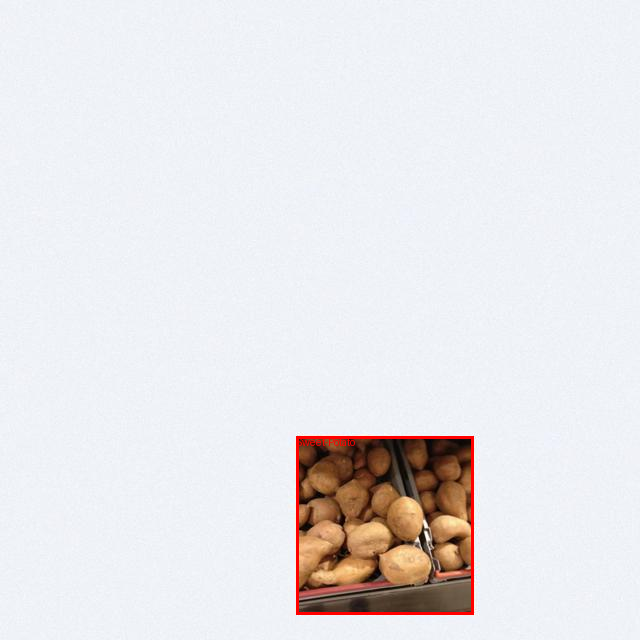

In [ ]:
%%train_only
import torch, torchvision.transforms.v2 as T
from PIL import Image
import numpy as np
# Shared image preprocessing for DINOv2.
TF = T.Compose([T.ToImage(), T.Resize((224,224)), T.ToDtype(torch.float32, scale=True),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
def feats_of(paths, model, bs=16):
    """Embed image files in small batches and return an (N, D) numpy array."""
    out=[]
    for i in range(0,len(paths),bs):
        xs=torch.stack([TF(Image.open(p).convert('RGB')) for p in paths[i:i+bs]])
        out.append(extract_features(model,[xs]))
    return np.concatenate(out,0)
from ultralytics import YOLO
from PIL import Image, ImageDraw
def feats_of_imgs(imgs, model):
    """Embed PIL crops already in memory."""
    xs = torch.stack([TF(im.convert('RGB')) for im in imgs])
    return extract_features(model, [xs])
classes = b.manifest.get('class_list') or sorted({m['fine'] for m in idx.meta})
det = YOLO(str(Path(b.root)/'detector.pt'))
# Choose the input style:
# - 'multi_item_scene': use YOLO boxes from a cart/counter image.
# - 'single_product': skip YOLO and classify the whole image.
# - 'auto': use YOLO, but fall back to whole image if no boxes are found.
INPUT_MODE = 'auto'
USE_UPLOAD = False  # set True in Colab to choose an image from your computer
if USE_UPLOAD:
    from google.colab import files
    uploaded = files.upload()
    assert uploaded, 'No image uploaded.'
    scene_path = next(iter(uploaded))
else:
    scene_path = str(Path(b.root)/'sample_scene.jpg')  # saved by Day 2
assert Path(scene_path).exists(), f'Image not found: {scene_path}. If using the default sample, re-run Day 2.'
print('using image:', scene_path)
img = Image.open(scene_path).convert('RGB'); arr = np.array(img)
if INPUT_MODE == 'single_product':
    print('single_product mode: skipping detector and using the whole image.')
    boxes = np.array([[0, 0, img.width, img.height]], dtype='float32')
else:
    result = det(scene_path, imgsz=640, conf=0.05, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy() if len(result.boxes) else []
    print('detector boxes:', len(boxes), 'conf:', np.round(confs, 3).tolist())
    if len(boxes) == 0 and INPUT_MODE == 'auto':
        print('No detector boxes found; using the whole image as one product crop.')
        boxes = np.array([[0, 0, img.width, img.height]], dtype='float32')
if len(boxes):
    areas = (boxes[:,2]-boxes[:,0]) * (boxes[:,3]-boxes[:,1])
    largest = float(areas.max() / (img.width * img.height))
    if INPUT_MODE == 'auto' and largest < 0.10:
        print('Only small boxes were found. If this is a single product photo, set INPUT_MODE = "single_product".')
draw = ImageDraw.Draw(img)
# For each detected product: crop -> embed -> classify -> lookup similar catalog images + price.
rows, items = [], []
for x1,y1,x2,y2 in boxes:
    crop = Image.fromarray(arr[int(y1):int(y2), int(x1):int(x2)])
    f = feats_of_imgs([crop], model)
    pred = classes[int(head.predict(f)[0])]
    similar = [h['fine'] for h in idx.query(f, k=3)[0]]
    items.append({'fine': pred})
    rows.append({'predicted_item': pred, 'unit_price': prices.get(pred, 0.0), 'currency': currency, 'similar_gallery_matches': similar})
    draw.rectangle([x1,y1,x2,y2], outline='red', width=3); draw.text((x1,y1), pred, fill='red')
print('assembled pipeline on', len(boxes), 'detections')
display(pd.DataFrame(rows))
print('estimated basket total:', round(basket_total(items, prices, default=1.0), 2), currency)
img  # displays the annotated scene in Colab


🤖 **[CLAUDE] How to read the output — this receipt IS the week's work**

The table is an itemized receipt produced from a single photograph: `predicted_item` (Day 3/4's head speaking), `unit_price` (Day 1's catalog), and `similar_gallery_matches` (Day 1's fingerprint gallery agreeing — or not). The red boxes on the image are Day 2's detector; the labels on the boxes are the head's names. One photo in, a priced receipt out — that is SmartCart.

If a line on the receipt is wrong, you can trace *which* station failed, just like Day 3's error analysis:

- **Box around empty counter / two products in one box** → the detector (Day 2) — the eyes mis-saw.
- **Right box, wrong name** → the head (Day 3/4) — check whether `similar_gallery_matches` disagree with the prediction; if the gallery *also* points elsewhere, the fingerprint is genuinely ambiguous, a Day 4 augmentation candidate.
- **Right name, weird price (or 0.0)** → the catalog (Day 1) — the name isn't in the price list.

Also note the `default=1.0` in the total: any item missing from the catalog is billed a placeholder 1.00, so the total is an *estimate*.


🤖 **[CLAUDE] Extra demo — say the bottom line out loud**

A tiny recap cell: one sentence that compresses the entire pipeline run into human words. (Read-only — it just reuses variables from the cell above.)


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: the whole week in one sentence
# Uses only variables already defined by the assemble cell above.
names = [it['fine'] for it in items]
total = round(basket_total(items, prices, default=1.0), 2)
print(f"From ONE photo, SmartCart found {len(items)} item(s): {', '.join(names)}.")
print(f"Estimated total at the till: {total} {currency}.")
print("(detector found them, DINOv2 described them, the head named them, the catalog priced them)")


From ONE photo, SmartCart found 1 item(s): Sweet-Potato.
Estimated total at the till: 1.4 USD.
(detector found them, DINOv2 described them, the head named them, the catalog priced them)


> 🏷️ **[ORIGINAL]**

## Export to ONNX

**What:** Export the linear head to ONNX (input 'feat', output 'logits').

**Why:** ONNX runs the classifier without PyTorch - smaller runtime, portable to many targets.

**Watch for:** YOLO exports separately via `YOLO('detector.pt').export(format='onnx')` - we focus on the head here.

🤖 **[CLAUDE] Why export, and why only the head?**

Our head currently lives inside PyTorch — a heavyweight toolbox a cheap checkout device shouldn't need to install. Exporting to **ONNX** packs the trained head into a universal container that a tiny engine (ONNX Runtime) can run anywhere — the same move you saw in Lab 3. You might wonder: *why export only the head and not the detector or backbone?* Because the head is the piece **we** trained — it's our unique cargo. A full deployment would ship the detector and backbone in containers too (the comment in the next cell shows the detector's one-liner), and Day 5b picks that thread up. Named ports matter: the container is labelled input **`'feat'`** (a fingerprint goes in) and output **`'logits'`** (per-class scores come out), so any program can plug in without guessing.


🤖 **[CLAUDE] What this code does**

One call: `export_head_onnx(head, in_dim=384, path=...)`. Under the hood (see the toolkit), it runs `torch.onnx.export`, which works like a customs inspection: it pushes a dummy fingerprint of zeros, shape `(1, 384)`, through the head, records every math operation it performs (here: one matrix multiply plus a bias — a linear layer really is that small), and writes that recording as `head.onnx` into the bundle. The `dynamic_axes` setting marks the batch dimension as flexible, so the exported file accepts 1 fingerprint or 100 at once. Expected output: `exported /content/SmartCart/head.onnx`. The commented line shows how the detector would export the same way.


In [ ]:
%%train_only
p = export_head_onnx(head, in_dim=384, path=str(Path(b.root)/'head.onnx'))
print('exported', p)
# Detector export (run in Colab): YOLO(str(Path(b.root)/'detector.pt')).export(format='onnx')


/tmp/ipykernel_1147/1036670371.py:143: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(head.net, torch.zeros(1, in_dim), path, input_names=['feat'], output_names=['logits'], dynamic_axes={'feat': {0: 'n'}, 'logits': {0: 'n'}}, opset_version=17, dynamo=False)


> 🏷️ **[ORIGINAL]**

## Parity check

**What:** Feed a random batch through both PyTorch and ONNX and assert they match.

**Why:** Export silently changing outputs is a classic deploy bug - we gate on it.

**Watch for:** Tolerance 1e-3 covers float rounding; a larger gap means the export is wrong.

🤖 **[CLAUDE] Parity check — never trust a container you haven't opened**

Export bugs are sneaky: the file writes fine, loads fine, runs fine... and quietly gives *different answers*. So before shipping we do the mover's ritual: unpack the container and compare against the original, item by item. Same input → both models → measure the biggest disagreement. This step costs one second and has saved countless real deployments.


🤖 **[CLAUDE] What this code does**

`np.random.randn(2, 384)` invents 2 fake fingerprints of random numbers. Random data is *enough* here because we are not testing whether the model is smart — we are testing whether two copies of the same math **agree**; any input probes that equally well, no real photos required. `onnx_parity` runs the batch through the PyTorch head and the ONNX file and returns the single biggest difference across all output numbers.

The `assert err < 1e-3` is the tripwire: if the exported copy strays more than 0.001 from the original, the cell *crashes on purpose* instead of letting a corrupted model sail on to Day 5b. That's what the assert protects against — silently shipping a model that answers differently than the one you tested all week. Expected output: `parity` followed by a very small number.


In [ ]:
%%train_only
x = np.random.randn(2, 384).astype('float32')
err = onnx_parity(head, p, x)
assert err < 1e-3, f'parity too loose: {err}'
print('parity', err)


parity 1.9073486328125e-06


🤖 **[CLAUDE] How to read the output — how small is small enough?**

You should see something like `parity 4.7e-07` — a number with `e-06` or `e-07` at the end, meaning 0.0000005-ish. That's not an error in the "mistake" sense; it's ordinary float rounding — the two engines add numbers in slightly different orders, like two cashiers rounding pennies differently and landing a hair apart. Anything comfortably below the `1e-3` tolerance is a pass. If you ever saw `0.5` or `3.2` here, the export truly went wrong (wrong weights, wrong layer recorded) and the assert would stop you — which is exactly the point.


🤖 **[CLAUDE] Extra demo — parity on a bigger batch**

Two random fingerprints is a light test; let's stress it with 100 and watch the error stay tiny.


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: parity check with 100 random fingerprints instead of 2
x_big = np.random.randn(100, 384).astype('float32')
err_big = onnx_parity(head, p, x_big)
print(f"max PyTorch-vs-ONNX difference over 100 x {len(classes)} outputs: {err_big:.2e}")
print("still far below the 1e-3 tolerance -> the packed model matches the original")


max PyTorch-vs-ONNX difference over 100 x 81 outputs: 3.58e-06
still far below the 1e-3 tolerance -> the packed model matches the original


> 🏷️ **[ORIGINAL]**

## Quantize + benchmark

**What:** Dynamically quantize the ONNX head to int8 and time torch vs onnx vs int8.

**Why:** Quantization shrinks the model and usually speeds inference - we measure to confirm.

**Watch for:** Quantization can hit ORT edge cases; we wrap it so CI tolerates a failure with a note.

🤖 **[CLAUDE] Quantization — the Lab 1 shrink ray returns**

The ONNX file stores its weights as 32-bit floats — very precise decimals. **Dynamic int8 quantization** rounds those weights to 8-bit integers, a grid of just 256 levels: roughly 4× less storage per number, like re-saving a photo at lower quality — smaller file, and to the eye (and to accuracy) barely different. You met this idea in Lab 1. "Dynamic" means the weights are rounded once at packing time, while the data flowing through is handled on the fly. But we don't just *believe* the win — the next cell **measures** it: file sizes on disk, and a stopwatch race between PyTorch, ONNX fp32, and ONNX int8.


🤖 **[CLAUDE] What this code does — a shrink, then a stopwatch race**

Three things happen:

1. **Shrink** — `quantize_dynamic(p, int8_path, weight_type=QuantType.QInt8)` reads `head.onnx` and writes `head.int8.onnx` with weights rounded to 8-bit. It's wrapped in `try/except` because quantization occasionally trips on library edge cases; if so, it prints "quantization skipped" and the rest still runs.
2. **Weigh** — the `sizes` dictionary maps each version's name to its file size in **bytes**: `{'onnx_fp32': ..., 'onnx_int8': ...}`. Expect int8 to be roughly a quarter of fp32 (for our tiny head, a fixed file overhead means the ratio can be less dramatic).
3. **Race** — `bench` is the stopwatch: it calls a prediction function 200 times on the same batch of 8 fake fingerprints and reports the *average milliseconds per call*. It races three contestants: the PyTorch head, the ONNX fp32 file, and the int8 file. Note what's timed is only the head's forward pass — the tiny final station, not the detector or backbone.

Expected output: the sizes dict, then three `ms/call` lines, each a small fraction of a millisecond.


In [ ]:
%%train_only
import time, os
sizes = {'onnx_fp32': os.path.getsize(p)}
int8_path = str(Path(b.root)/'head.int8.onnx')
try:
    from onnxruntime.quantization import quantize_dynamic, QuantType
    quantize_dynamic(p, int8_path, weight_type=QuantType.QInt8)
    sizes['onnx_int8'] = os.path.getsize(int8_path)
except Exception as e:
    print('quantization skipped:', e)
print('sizes (bytes):', sizes)
import onnxruntime as ort
sess = ort.InferenceSession(p)
xb = np.random.randn(8, 384).astype('float32')
def bench(fn, n=200):
    t0 = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter()-t0)/n*1e3
print('torch  ms/call:', round(bench(lambda: head.net(head.torch.tensor(xb))), 3))
print('onnx   ms/call:', round(bench(lambda: sess.run(None, {'feat': xb})), 3))
if 'onnx_int8' in sizes:
    s8 = ort.InferenceSession(int8_path)
    print('int8   ms/call:', round(bench(lambda: s8.run(None, {'feat': xb})), 3))


sizes (bytes): {'onnx_fp32': 124962, 'onnx_int8': 32342}
torch  ms/call: 0.085
onnx   ms/call: 0.029
int8   ms/call: 0.038


🤖 **[CLAUDE] How to read the output — which one would you actually ship?**

Two axes to compare. **Size:** `onnx_int8` should be clearly smaller than `onnx_fp32` — that's storage and download time on the device. **Speed:** the ONNX numbers usually beat PyTorch on CPU for a model this small, because ONNX Runtime skips PyTorch's bookkeeping; fp32 vs int8 speed may be close (our head is so tiny that rounding barely changes the math workload — on big models int8 wins more visibly).

For a **low-power checkout device**, you'd ship `head.int8.onnx`: it's the smallest file, needs no PyTorch installed, runs at least as fast, and the accuracy cost of rounding a single linear layer is negligible. The only reason to prefer fp32 ONNX is if quantization was skipped or if a parity-style check on int8 showed unacceptable drift. Don't over-read tiny millisecond differences — Colab timings wobble run to run.


🤖 **[CLAUDE] Extra demo — the size table, with "× smaller" ratios**

Bytes are hard to eyeball; here's a mini table comparing the PyTorch checkpoint and both ONNX files, in kilobytes, with shrink ratios.


In [ ]:
%%train_only
# 🤖 [CLAUDE] Extra demo: file sizes side by side, with shrink ratios (read-only)
pt_path = Path(b.root)/'head_v2.pt' if (Path(b.root)/'head_v2.pt').exists() else Path(b.root)/'head.pt'
table = {'pytorch (.pt)': os.path.getsize(pt_path), 'onnx fp32': sizes['onnx_fp32']}
if 'onnx_int8' in sizes:
    table['onnx int8'] = sizes['onnx_int8']
biggest = max(table.values())
print(f"{'version':<14} {'size (KB)':>10}   vs biggest")
for name, nbytes in table.items():
    print(f"{name:<14} {nbytes/1024:>10.1f}   {biggest/nbytes:>5.1f}x smaller" if nbytes < biggest
          else f"{name:<14} {nbytes/1024:>10.1f}   (biggest)")


version         size (KB)   vs biggest
pytorch (.pt)       123.7   (biggest)
onnx fp32           122.0     1.0x smaller
onnx int8            31.6     3.9x smaller


> 🏷️ **[ORIGINAL]**

## Save + carry forward

**What:** Note the ONNX artifact and save the bundle.

**Why:** Day 5b loads `head.onnx` to serve predictions inside the Gradio app.

**Watch for:** Confirm head.onnx is in the bundle artifacts.

🤖 **[CLAUDE] Handing the baton to Day 5b**

Same closing ritual as every day: register today's product in the bundle's manifest and save. Tomorrow's notebook builds the actual SmartCart *app* (a Gradio web interface), and it will load `head.onnx` to serve predictions — proof that the container we packed today really is the thing that ships.


🤖 **[CLAUDE] What this code does**

`b._note('head.onnx')` adds the ONNX file to the bundle's inventory list, and `save_bundle(b)` writes the updated `manifest.json` to Drive. Expected output: a `[bundle] saved -> ...` line and the carry-forward note. Quick self-check: the artifact list should now include `head.onnx` — that's Day 5b's starting ingredient.


In [ ]:
%%train_only
b._note('head.onnx')
save_bundle(b)
print('\u25b6 Carries forward to Day 5b: head.onnx')


## 🚀 [TEAM ENHANCEMENT] E5 — D5 Explainability: Grad-CAM + similar-catalog evidence

"Before the app, the evidence. Day 3 explained decisions with occlusion maps — robust, but forty-nine forward passes per image. We add **Grad-CAM on the DINOv2 backbone**: one backward pass. On a Vision Transformer the trick is the `reshape_transform` — 256 patch tokens folded back into a 16×16 grid, CLS token dropped. Next to the heat-map we show the **top-3 catalog matches** with scores. *Where* the model looked, plus *what* it thinks the item resembles — a supervisor can verify a call in a second. Note we explain the exact head we just exported — `head_v2` loaded from the bundle — not some other model."

**Why this choice (full rationale):**
- *Grad-CAM complements, not replaces, occlusion* — occlusion (Day 3) is model-agnostic and validates the explanation method itself; Grad-CAM is ~50× cheaper, which is what makes explanation viable inside an app loop.
- *ViT specifics* — CAM methods assume spatial maps; we target the last transformer block's `norm1` and reshape tokens to 16×16 (224 ÷ patch-14).
- *Evidence panel* — reuses the Day 1 gallery index at zero cost; matches the brief's D5 wording exactly: "show similar catalog images and Grad-CAM evidence".


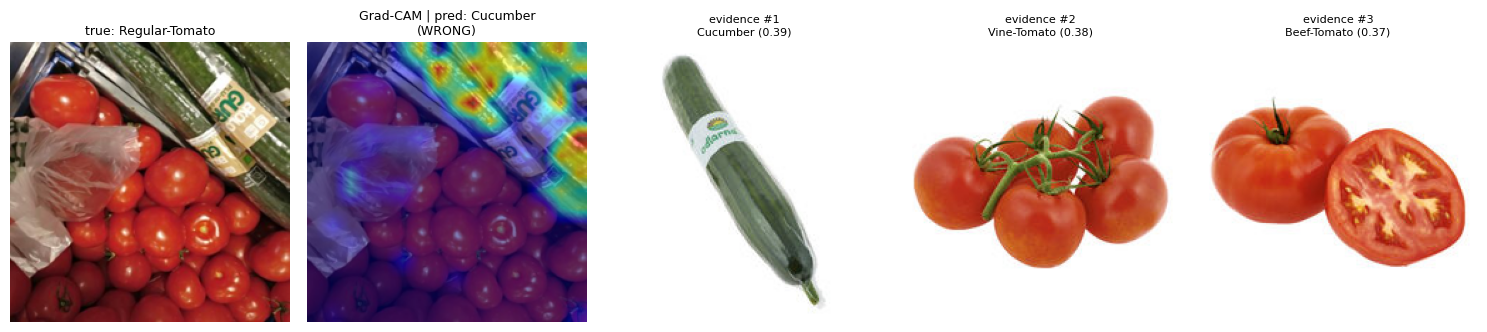

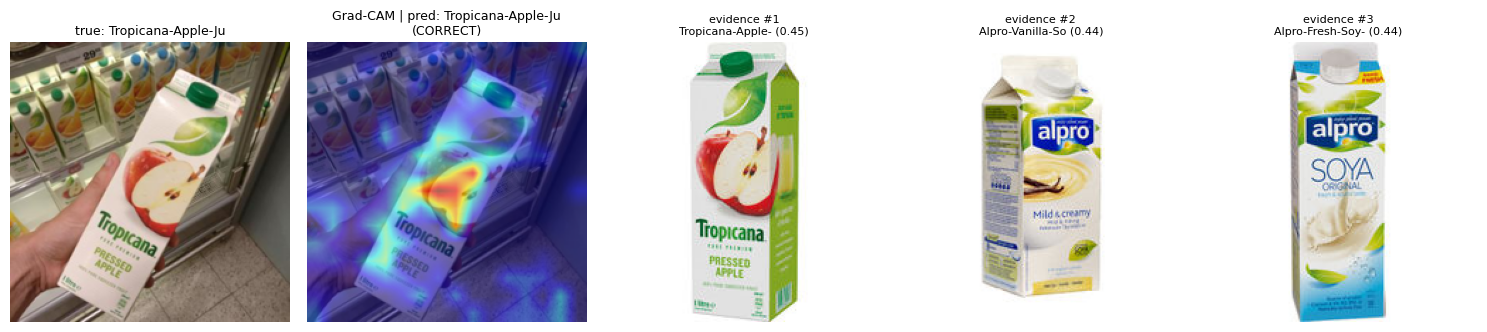

Explanation = WHERE the model looked (Grad-CAM) + WHAT it looks like (catalog neighbours).


In [ ]:
%%train_only
# 🚀 E5) Grad-CAM on the ViT backbone + top-3 similar-catalog evidence (for the SHIPPED head)
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import torch.nn as nn
import copy as _copy
import matplotlib.pyplot as plt

class FullModel(nn.Module):
    """Frozen backbone + shipped head as one differentiable model for Grad-CAM."""
    def __init__(self, backbone, head_net):
        super().__init__()
        self.backbone, self.head = backbone, head_net
    def forward(self, x):
        return self.head(self.backbone(x))

gc_backbone = load_backbone(device=device)  # fresh copy so we can enable gradients
for p_ in gc_backbone.parameters():
    p_.requires_grad_(True)
full_model = FullModel(gc_backbone, _copy.deepcopy(head.net).to(device)).eval()

def vit_reshape(t):
    t = t[:, 1:, :]                       # drop the CLS token
    n_ = int(t.shape[1] ** 0.5)           # 224/14 = 16 patches per side
    return t.reshape(t.shape[0], n_, n_, t.shape[2]).permute(0, 3, 1, 2)

# Xval/yval/ival/base come from the Day 4 retrain section; head is the loaded head_v2.
pred_ship = head.predict(Xval)
wrong_i = np.where(pred_ship != yval)[0]
right_i = np.where(pred_ship == yval)[0]
show_ids = ([int(wrong_i[0])] if len(wrong_i) else []) + [int(right_i[0])]
val_paths = base.path.iloc[ival].reset_index(drop=True)

with GradCAM(model=full_model, target_layers=[gc_backbone.blocks[-1].norm1],
             reshape_transform=vit_reshape) as cam:
    for vi in show_ids:
        pil = Image.open(val_paths.iloc[vi]).convert('RGB').resize((224, 224))
        rgb = np.asarray(pil).astype('float32') / 255.0
        x_in = TF(pil).unsqueeze(0).to(device)
        k_pred = int(pred_ship[vi])
        gray = cam(input_tensor=x_in, targets=[ClassifierOutputTarget(k_pred)])[0]
        overlay = show_cam_on_image(rgb, gray, use_rgb=True)
        evidence = idx.query(Xval[vi:vi + 1], k=3)[0]
        fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
        status = 'CORRECT' if k_pred == int(yval[vi]) else 'WRONG'
        axes[0].imshow(pil); axes[0].set_title(f'true: {classes[int(yval[vi])][:18]}', fontsize=9)
        axes[1].imshow(overlay); axes[1].set_title(f'Grad-CAM | pred: {classes[k_pred][:18]}\n({status})', fontsize=9)
        for j_, ev in enumerate(evidence):
            axes[2 + j_].imshow(Image.open(ev['iconic']).convert('RGB'))
            axes[2 + j_].set_title(f"evidence #{j_ + 1}\n{ev['fine'][:16]} ({ev['score']:.2f})", fontsize=8)
        for ax in axes:
            ax.axis('off')
        plt.tight_layout(); plt.show()
print('Explanation = WHERE the model looked (Grad-CAM) + WHAT it looks like (catalog neighbours).')


## 🚀 Publish to Hugging Face (TRAIN = True only)

One-time step: uploads the serving artifacts to `HF_REPO` so the demo can download them. Needs a Colab secret with a write token (see README).

In [ ]:
%%train_only
# ── Publish the trained artifacts to the Hugging Face Hub (one-time; TRAIN = True only) ──
# Needs a Colab secret named HF_TOKEN with WRITE access. Demo mode later downloads this repo (public, no token).
import shutil
from pathlib import Path
import pandas as pd

write_token = os.environ.get('HF_TOKEN')
try:
    from google.colab import userdata
    write_token = userdata.get('HF_TOKEN') or write_token
except Exception:
    pass

if not write_token:
    print('No Hugging Face token in Colab Secrets: skipping the upload (the app below still works from the local bundle).')
else:
    from huggingface_hub import HfApi
    bdir = Path(BUNDLE_DIR)
    stage = Path('/content/hf_upload')
    if stage.exists():
        shutil.rmtree(stage)
    stage.mkdir(parents=True)
    # Serving artifacts (head_v2.pt / head.int8.onnx are optional extras).
    for name in ['detector.pt', 'head.onnx', 'head.int8.onnx', 'head_v2.pt',
                 'catalog_prices.csv', 'gallery_index.npy', 'manifest.json', 'sample_scene.jpg']:
        if (bdir / name).exists():
            shutil.copy(bdir / name, stage / name)
    # gallery_meta.csv: keep only the class name; the 'iconic' column holds local dataset paths the app does not use.
    pd.read_csv(bdir / 'gallery_meta.csv')[['fine']].to_csv(stage / 'gallery_meta.csv', index=False)
    # A few hard stress-test scenes (E2) as multi-item examples for the app.
    for k in range(3):
        p = Path(f'datasets/scenes_hard/images/hard_{k:03d}.jpg')
        if p.exists():
            shutil.copy(p, stage / p.name)
    (stage / 'README.md').write_text(
        '# SmartCart vision artifacts\n\n'
        'YOLO11n product detector (`detector.pt`, single class "product", trained on synthetic composite scenes), '
        'a linear head on frozen DINOv2-small features exported to ONNX (`head.onnx`, `head.int8.onnx`), '
        'the catalog gallery embeddings (`gallery_index.npy`, `gallery_meta.csv`), an invented demo price list '
        '(`catalog_prices.csv`), `manifest.json` (class list + detector confidence) and sample synthetic scenes.\n\n'
        'Scenes are composed from GroceryStoreDataset images (github.com/marcusklasson/GroceryStoreDataset). '
        'Prices are made up for the demo. Student project, not for production use.\n')
    api = HfApi(token=write_token)
    api.create_repo(HF_REPO, repo_type='model', exist_ok=True)
    api.upload_folder(folder_path=str(stage), repo_id=HF_REPO, repo_type='model',
                      commit_message='SmartCart serving artifacts')
    print('uploaded to https://huggingface.co/' + HF_REPO, '->', sorted(p.name for p in stage.iterdir()))


---
## ▶ Demo loader (runs in both modes)

- **`TRAIN = False`:** downloads the published artifacts from the Hugging Face Hub into `BUNDLE_DIR`.
- **`TRAIN = True`:** the bundle was just produced by Days 1–5a above, so nothing is downloaded.

It also sets the operating points that the E6 checkout app uses:
- `BEST_CONF` is the detector confidence chosen by the E2 sweep, read from `manifest.json`.
- `best_alpha = 1.0` and `UNKNOWN_THR = 0.45` are **fixed defaults, not values tuned on validation data**.


In [ ]:
# ── Demo loader: make sure BUNDLE_DIR holds the serving artifacts ──
import json
from pathlib import Path

if not TRAIN:
    from huggingface_hub import snapshot_download
    try:
        snapshot_download(repo_id=HF_REPO, repo_type='model', local_dir=BUNDLE_DIR)
    except Exception as e:
        raise RuntimeError(f'Could not download {HF_REPO} from the Hugging Face Hub. Publish it once by running '
                           'this notebook with TRAIN = True and a Hugging Face write token saved as a Colab secret.') from e

_need = ['detector.pt', 'head.onnx', 'catalog_prices.csv', 'gallery_index.npy', 'gallery_meta.csv', 'manifest.json']
_missing = [n for n in _need if not (Path(BUNDLE_DIR) / n).exists()]
assert not _missing, f'missing in {BUNDLE_DIR}: {_missing}'
print('bundle ready:', sorted(p.name for p in Path(BUNDLE_DIR).iterdir() if p.is_file()))

# Operating points used by checkout() in the E6 cells below.
_manifest = json.loads((Path(BUNDLE_DIR) / 'manifest.json').read_text())
BEST_CONF = float(_manifest.get('detector_conf', 0.10))  # E2 sweep result (best F1 on the hard scenes), saved in the manifest
best_alpha = 1.0     # DEFAULT, not tuned: 1.0 = ONNX head only (no kNN blending)
UNKNOWN_THR = 0.45   # DEFAULT, not tuned: below this softmax confidence an item is flagged UNKNOWN
print(f'BEST_CONF = {BEST_CONF} (from manifest) | best_alpha = {best_alpha} (default) | UNKNOWN_THR = {UNKNOWN_THR} (default)')


---
# Part 6 — Day 5b: Gradio Demo (official annotated base + 🚀 E6)

The cells below are the provided **Day5b_gradio_demo_annotated** notebook: serve `head.onnx`, define `recognize()`, test it inline, launch a simple Gradio interface. Our 🚀 E6 enhancement then upgrades it to checkout quality using everything validated earlier in this notebook.


🤖 **[CLAUDE] Welcome / How to read this notebook**

Welcome to the **grand finale** of the SmartCart week! This notebook has two kinds of cells: anything marked 🏷️ **[ORIGINAL]** is the untouched course material, and anything marked 🤖 **[CLAUDE]** is a friendly explanation added for beginners. Read the Claude cell *before* each code cell to know what is about to happen, then run the code.

**The story so far, one verb per day.** On Day 1 you **acquired** data: you labelled product photos and built a "gallery" of DINOv2 embeddings (fingerprints for images) plus a price list. On Day 2 you **localized**: a detector learned to draw boxes around products in a messy counter photo. On Day 3 you **recognized**: a small linear "head" learned to name each cropped product. On Day 4 you **augmented**: you generated extra training photos for the weak classes and trained a stronger head. On Day 5a you **assembled and packed**: you chained all the pieces into one pipeline and exported the head to a fast, portable ONNX file.

**Today's mission:** ship it! We wrap the whole pipeline in a real, clickable web app. A shopper uploads a counter photo and gets back an itemized receipt with a total — the entire week's work behind one button.

**Mini-glossary** (peek back here anytime):
- **Gradio** — a Python kit that turns a function into a web page in a few lines. You give it a function ("image in, results out"); it builds the upload button, the result display, and even a shareable link. It is how ML people demo models without learning web development.
- **Web app / UI** — a page in the browser with buttons and pictures. "UI" = user interface, the part a human clicks.
- **Serving / inference** — *using* a trained model to make predictions, as opposed to *training* it. Like a restaurant kitchen during dinner service: you cook from the finished recipe, you don't invent new dishes mid-service.
- **ONNX session** — a small, fast "player" for our packed model file (`head.onnx`), like a music player for an MP3. It only knows how to *run* the model, which is all serving needs.
- **Receipt** — the app's answer: one row per detected product with its name and price, plus the basket total.
- **Bundle** — the shared Google Drive folder where each day dropped its results (labels, gallery, model files, prices) for the next day to pick up. A relay-race baton.
- **Environment variable** — a named switch that lives outside the code (e.g. `SC_LAUNCH_GRADIO=1`). Programs can check it to decide behaviour without editing the code — here it stops automated test runs from starting a web server and hanging forever.


> 🏷️ **[ORIGINAL]**

# SmartCart Day 5b - Gradio Demo

The finale: a **self-checkout demo**. Upload a counter photo, the app detects products, recognizes each via the ONNX head, finds catalog matches, and totals the basket from a simple price table - the whole week's work behind one button.

🤖 **[CLAUDE] Today in plain words**

"Self-checkout demo" means exactly what it sounds like: the machine at the supermarket that scans your basket — except ours works from a single photo. You upload a picture of products on a counter; the detector (Day 2) finds each product, the backbone turns each crop into a number-fingerprint (Day 1), the ONNX head names it (Days 3–4, packed on Day 5a), a price table looks up the cost, and everything is added up into a receipt. Nothing new is trained today — we are only *arranging* the finished pieces behind one upload button. That's what "shipping" a model means: making it usable by someone who knows nothing about the machinery inside.


🤖 **[CLAUDE] What this code does**

Standard Colab warm-up, same as every day this week:

- `%pip install ...` fetches the libraries we need: `timm` (the DINOv2 backbone), `ultralytics` (the YOLO detector), `onnxruntime` (the player for our packed `head.onnx` file), and the star of today, **`gradio`** (the web-app kit).
- `drive.mount(...)` connects your Google Drive, and `BUNDLE_DIR` points at the SmartCart folder — the relay-race baton holding everything the previous days saved.

Notice what is *not* installed: no training tools, no plotting of loss curves. This is a serving notebook. **Expected output:** pip progress lines, then a Drive permission prompt and "Mounted at ...".


In [ ]:
# 1) Runtime setup
# This course runs in Google Colab. Run this cell first.
# Install only the packages used in this notebook.
%pip install -q timm ultralytics onnxruntime gradio

import os

# The cross-day bundle lives in BUNDLE_DIR (a local folder set in the Demo settings cell) - no Drive mount needed.



> 🏷️ **[ORIGINAL]**

### Embedded toolkit

This cell defines the helper functions used below. Run it once after setup.

🤖 **[CLAUDE] Why a "toolkit" cell?**

The next cell is a copy-paste of the small helper library the whole week has used, embedded directly in the notebook so it runs anywhere without extra files. You have met every one of these helpers before — the next Claude cell gives you a one-line refresher for each. Just run it once and move on; nothing here computes anything yet, it only *defines* tools.


🤖 **[CLAUDE] What this code does**

One sentence per tool, all old friends by now:

- **`Bundle`** — a tiny wrapper around the Drive folder that saves/loads tables (CSV) and arrays (NumPy), plus a `manifest.json` listing what's inside; `open_bundle`/`save_bundle` open and save it.
- **`load_backbone`** — downloads the frozen DINOv2 vision model, the "eye" that converts any image into a 384-number fingerprint (an *embedding*); frozen means we never change it.
- **`extract_features`** — pushes batches of images through that backbone and hands back the fingerprints as a plain NumPy array.
- **`EmbeddingIndex`** — the Day 1 gallery: a "find the most similar known product" lookup that compares fingerprints by cosine similarity, with save/load to the bundle.
- **`basket_total`** — adds up prices for a list of recognized items, using a default price for anything not in the catalog.

**Expected output:** just `SmartCart toolkit ready`.


In [ ]:
from __future__ import annotations
import json
import os
import pathlib
import subprocess
import numpy as np
import pandas as pd
HERE = pathlib.Path.cwd()  # embedded in-notebook: no __file__, anchor on the working dir
GROCERY_DATASET_URL = 'https://github.com/marcusklasson/GroceryStoreDataset'

class Bundle:
    """Small Google Drive folder that carries artifacts from one day to the next."""

    def __init__(self, root: str):
        self.root = pathlib.Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.manifest = {'version': 1, 'class_list': [], 'artifacts': {}}

    def put_table(self, name, df: pd.DataFrame):
        df.to_csv(self.root / name, index=False)
        self._note(name)

    def get_table(self, name) -> pd.DataFrame:
        return pd.read_csv(self.root / name)

    def put_array(self, name, arr: np.ndarray):
        np.save(self.root / name, arr)
        self._note(name)

    def get_array(self, name) -> np.ndarray:
        p = self.root / name
        return np.load(p if p.suffix == '.npy' else p.with_suffix('.npy'))

    def _note(self, name):
        self.manifest['artifacts'][name] = True

    def save(self):
        (self.root / 'manifest.json').write_text(json.dumps(self.manifest, indent=2))

    def load(self):
        p = self.root / 'manifest.json'
        if p.exists():
            self.manifest = json.loads(p.read_text())
        return self

def open_bundle(drive_dir='/content/SmartCart') -> Bundle:
    """Open the cross-day Drive bundle. If it is new, start with an empty manifest."""
    return Bundle(drive_dir).load()

def save_bundle(b: Bundle):
    b.save()
    print(f'[bundle] saved -> {b.root}')

def load_backbone(name='vit_small_patch14_dinov2.lvd142m', device='cpu'):
    """Frozen DINOv2-small feature extractor."""
    import timm
    m = timm.create_model(name, pretrained=True, num_classes=0, dynamic_img_size=True).eval().to(device)
    for p in m.parameters():
        p.requires_grad_(False)
    return m

def extract_features(model, batches, device=None) -> np.ndarray:
    """Run image batches through a frozen backbone and return numpy features."""
    import torch
    if device is None:
        try:
            device = next(model.parameters()).device
        except (AttributeError, StopIteration):
            device = 'cpu'
    outs = []
    with torch.no_grad():
        for xb in batches:
            y = model(xb.to(device))
            outs.append(y.detach().cpu().numpy().astype('float32'))
    return np.concatenate(outs, 0)

class EmbeddingIndex:
    """Cosine nearest-neighbor index over catalog/gallery embeddings."""

    def __init__(self):
        self._nn = None
        self.meta = []

    def build(self, feats: np.ndarray, meta: list[dict]):
        from sklearn.neighbors import NearestNeighbors
        f = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-08)
        self._nn = NearestNeighbors(n_neighbors=min(10, len(f)), metric='cosine').fit(f)
        self.meta = meta
        self._feats = f
        return self

    def query(self, q: np.ndarray, k=5):
        qn = q / (np.linalg.norm(q, axis=1, keepdims=True) + 1e-08)
        dist, idx = self._nn.kneighbors(qn, n_neighbors=min(k, len(self.meta)))
        return [[{**self.meta[j], 'score': float(1 - d)} for d, j in zip(drow, irow)] for drow, irow in zip(dist, idx)]

    def save(self, b: Bundle, prefix='gallery'):
        b.put_array(f'{prefix}_index.npy', self._feats)
        b.put_table(f'{prefix}_meta.csv', pd.DataFrame(self.meta))

    @classmethod
    def load(cls, b: Bundle, prefix='gallery'):
        feats = b.get_array(f'{prefix}_index.npy')
        meta = b.get_table(f'{prefix}_meta.csv').to_dict('records')
        return cls().build(feats, meta)

def basket_total(items, prices, default=0.0):
    return float(sum((prices.get(it['fine'], default) for it in items)))
# --- helpers are now available as plain functions/classes in this notebook ---
print('SmartCart toolkit ready')


SmartCart toolkit ready


🤖 **[CLAUDE] What this code does**

This opens the bundle — the shared Drive folder — and prints its table of contents (`manifest.json`). Think of it as opening the relay-race baton and checking every previous runner actually put their piece inside. Today we need at least: the gallery index (Day 1), `detector.pt` (Day 2), `catalog_prices.csv` (Day 1), and `head.onnx` (Day 5a). Note the comment in the code: the bundle holds small *artifacts* (results), never the big image dataset itself.


In [ ]:
# 2) Load the cross-day bundle
# The bundle stores artifacts we create during the week: labels, indexes, weights, ONNX files.
# It is NOT the image dataset. Images are loaded in the next data-source cell.
b = open_bundle(BUNDLE_DIR)
print('bundle:', b.root)
print('artifacts:', list(b.manifest.get('artifacts', {})))


🤖 **[CLAUDE] How to read the output**

You should see the bundle path and a list of artifact names. Scan it like a packing checklist: if `head.onnx` is missing, re-run Day 5a; if `detector.pt` is missing, re-run Day 2; if `catalog_prices.csv` or the gallery files are missing, re-run Day 1. Everything downstream assumes these exist — better to find out now than mid-demo.


> 🏷️ **[ORIGINAL]**

## Load model + catalog prices

**What:** Open an ONNX session for the head, load the gallery, load `catalog_prices.csv`, and load the detector + backbone.

**Why:** These are the exact runtime pieces the app needs - no training, just serving.

**Watch for:** Prices are editable demo business data; the ONNX head replaces PyTorch at serve time.

🤖 **[CLAUDE] Serving vs training — the kitchen analogy**

The course cell says "no training, just serving," and this distinction is worth internalizing. *Training* is recipe development: you taste, adjust, keep gradients and optimizers around — heavy machinery, lots of memory. *Serving* is dinner service: the recipe is final, and you only need the fast tools to cook it repeatedly. That's why the head we trained on Days 3–4 now arrives as `head.onnx`, opened by a lightweight ONNX Runtime *session* instead of the full PyTorch training stack. We still load PyTorch here — but only to run the frozen DINOv2 backbone and the YOLO detector forward, never to compute a single gradient. And notice `catalog_prices.csv` riding along: real apps mix ML pieces with plain *business data* (prices someone can edit in a spreadsheet, no retraining needed).


🤖 **[CLAUDE] What this code does — loading the serving-time pieces**

This cell lays out every ingredient the app needs on the counter, and nothing more:

1. **`sess = ort.InferenceSession(...'head.onnx')`** — opens an ONNX Runtime *session* on the packed head from Day 5a. A session is like pressing play on an MP3: it can only *run* the model, fast and light. The trainable PyTorch version of the head is nowhere in this notebook — at serving time we don't need optimizers, gradients, or checkpoints, just the frozen math.
2. **`idx = EmbeddingIndex.load(b)`** — reloads the Day 1 gallery, used later to show "similar known products" next to each prediction.
3. **`model = load_backbone(...)`** — the frozen DINOv2 eye, on GPU if Colab gave us one. It was never trained by us, so there was nothing to export — we just run it as-is.
4. **`classes`** — the official list of product names, in the exact order the head's outputs are arranged. Position 7 in the head's output = name 7 in this list; mixing up this order would mislabel everything.
5. **`price_catalog` / `prices` / `currency`** — the CSV price table turned into a quick name-to-price dictionary. Pure business data, editable without touching any model.
6. **`det = YOLO(...'detector.pt')`** — the Day 2 detector that finds product boxes in a counter photo.

**Expected output:** the device (`cuda` or `cpu`), possibly a one-time backbone download bar, then something like `serving 24 classes with 24 catalog prices in USD`.


In [ ]:
from pathlib import Path
import onnxruntime as ort
import pandas as pd
import torch
# Load serving-time artifacts: ONNX head, gallery, price catalog, backbone, detector.
sess = ort.InferenceSession(str(Path(b.root)/'head.onnx'))
idx = EmbeddingIndex.load(b)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using device:', device)
model = load_backbone(device=device)
classes = b.manifest.get('class_list') or sorted({m['fine'] for m in idx.meta})
price_catalog = b.get_table('catalog_prices.csv')
prices = dict(zip(price_catalog.fine, price_catalog.unit_price))
currency = price_catalog.currency.iloc[0] if 'currency' in price_catalog else 'USD'
from ultralytics import YOLO
det = YOLO(str(Path(b.root)/'detector.pt'))
print('serving', len(classes), 'classes with', len(prices), 'catalog prices in', currency)


using device: cpu


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
serving 81 classes with 81 catalog prices in USD


🤖 **[CLAUDE]** One-line extra: every ONNX model publishes a tiny "contract" — the exact names and shapes of what goes in and comes out. Let's print it, because the `recognize()` function below must honour it exactly.


In [ ]:
# 🤖 [CLAUDE] Extra demo: print the ONNX session's serving contract
# Any program in any language could serve head.onnx as long as it honours these
# names and shapes ('None' / dynamic means "any batch size is fine").
for t in sess.get_inputs():
    print('input :', t.name, '| shape:', t.shape, '| type:', t.type)
for t in sess.get_outputs():
    print('output:', t.name, '| shape:', t.shape, '| type:', t.type)
print()
print('So recognize() must feed a float32 array under the name', repr(sess.get_inputs()[0].name),
      'and will get back one score per class.')


input : feat | shape: ['n', 384] | type: tensor(float)
output: logits | shape: ['n', 81] | type: tensor(float)

So recognize() must feed a float32 array under the name 'feat' and will get back one score per class.


> 🏷️ **[ORIGINAL]**

## Inference function

**What:** Define `recognize(image)`: detect -> crop -> embed -> ONNX argmax -> label, then total the basket.

**Why:** This single function is the app's brain; Gradio just wraps it with a UI.

**Watch for:** Returns an annotated image, a per-item table, and the basket total.

🤖 **[CLAUDE] The one function that IS the product**

Everything the week built compresses into a single Python function: `recognize(image)`. Photo goes in, receipt comes out. This is the punchline of the whole course — five days of work reshaped into one callable that a shopper can trigger by uploading a picture. Gradio (next section) adds zero intelligence; it only puts an upload button in front of this function. If you understand `recognize()`, you understand the entire SmartCart system.


🤖 **[CLAUDE] What this code does — follow one photo through the pipeline**

First, some setup you've seen before: `TF` is the standard DINOv2 photo-prep recipe (resize to 224×224, scale pixel values, normalize colors — the backbone expects its food prepared exactly this way), and `feats_of` / `feats_of_imgs` turn image files or in-memory crops into fingerprint arrays.

Now trace one uploaded counter photo through **`recognize(image)`**, stage by stage:

1. **Arrive** — the photo is converted to RGB, copied into a NumPy pixel array, and a drawing layer is prepared so we can annotate it.
2. **Detect (Day 2)** — the YOLO detector scans the photo and returns boxes `[x1,y1,x2,y2]`, one per suspected product. Safety net: if it finds nothing, the *whole photo* is treated as one big product, so the app never returns an empty shrug.
3. **Crop** — for each box, the pixels inside are cut out into a small product portrait.
4. **Embed (Day 1)** — the frozen backbone turns that crop into a 384-number fingerprint `f`.
5. **Classify (Days 3–5a)** — `sess.run(None, {'feat': ...})` hands the fingerprint to the ONNX head, which returns one score per class; `argmax` picks the highest, and `classes[...]` converts that position into a product name.
6. **Second opinion** — the Day 1 gallery lists the 3 most similar known products, handy for judging borderline calls.
7. **Price lookup** — the name is looked up in the `prices` dictionary; each product becomes one receipt row (`item`, `price`, `currency`, `similar`), and a red box + label is drawn on the photo.
8. **Total** — `basket_total` sums the rows; unknown items get a flat $1.00 default rather than crashing (a deliberate, visible business rule).

The function returns two things — the annotated image and a receipt dictionary — which is precisely the shape Gradio will display. **Expected output when run:** just `recognize() ready`; the function waits to be called.


In [ ]:
import torch, torchvision.transforms.v2 as T
from PIL import Image
import numpy as np
# Shared image preprocessing for DINOv2.
TF = T.Compose([T.ToImage(), T.Resize((224,224)), T.ToDtype(torch.float32, scale=True),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
def feats_of(paths, model, bs=16):
    """Embed image files in small batches and return an (N, D) numpy array."""
    out=[]
    for i in range(0,len(paths),bs):
        xs=torch.stack([TF(Image.open(p).convert('RGB')) for p in paths[i:i+bs]])
        out.append(extract_features(model,[xs]))
    return np.concatenate(out,0)
from PIL import Image, ImageDraw
def feats_of_imgs(imgs, model):
    """Embed PIL crops without saving them to disk."""
    xs = torch.stack([TF(im.convert('RGB')) for im in imgs])
    return extract_features(model, [xs])
def recognize(image):
    img = image.convert('RGB'); arr = np.array(img); draw = ImageDraw.Draw(img)
    result = det(arr, imgsz=640, conf=0.05, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy()
    if len(boxes) == 0:
        boxes = np.array([[0, 0, img.width, img.height]], dtype='float32')
    items, rows = [], []
    # One row per detected product.
    for x1,y1,x2,y2 in boxes:
        crop = Image.fromarray(arr[int(y1):int(y2), int(x1):int(x2)])
        f = feats_of_imgs([crop], model)
        logits = sess.run(None, {'feat': f.astype('float32')})[0]
        label = classes[int(logits.argmax(1)[0])]
        similar = [h['fine'] for h in idx.query(f, k=3)[0]]
        items.append({'fine': label})
        rows.append({'item': label, 'price': prices.get(label, 0.0), 'currency': currency, 'similar': similar})
        draw.rectangle([x1,y1,x2,y2], outline='red', width=3); draw.text((x1,y1), label, fill='red')
    total = basket_total(items, prices, default=1.0)  # unknown SKUs priced at a flat $1.00
    return img, {'items': rows, 'total': round(total, 2), 'currency': currency}
print('recognize() ready')


recognize() ready


🤖 **[CLAUDE]** Before wrapping this in a web page, let's prove `recognize()` works as a plain Python function — no browser, no server — by feeding it the sample counter photo Day 2 saved into the bundle.


=== RECEIPT ===
        item  price currency                              similar
Sweet-Potato    1.4      USD [Solid-Potato, Sweet-Potato, Ginger]
TOTAL: 1.4 USD


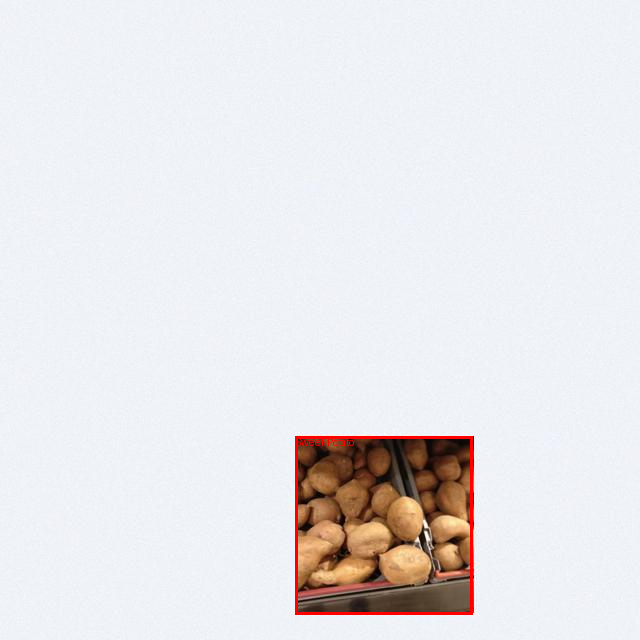

In [ ]:
# 🤖 [CLAUDE] Extra demo: call recognize() directly, no web UI needed
# The app is just this function + an upload button. Here we call it ourselves
# on the sample scene saved by Day 2 (read-only: nothing is written back).
from pathlib import Path
sample = Path(b.root) / 'sample_scene.jpg'
if sample.exists():
    annotated, receipt = recognize(Image.open(sample))
    print('=== RECEIPT ===')
    receipt_df = pd.DataFrame(receipt['items'])
    print(receipt_df.to_string(index=False))
    print(f"TOTAL: {receipt['total']} {receipt['currency']}")
    display(annotated)  # the photo with red boxes and labels drawn on
else:
    print('sample_scene.jpg not in the bundle - re-run Day 2, or just use the app below.')


🤖 **[CLAUDE] How to read the output (and debug a wrong receipt)**

The receipt table has one row per detected product: its predicted `item` name, `price`, and the gallery's 3 most `similar` known products; the annotated photo shows red boxes with labels. When a line is wrong, each *kind* of mistake points back at a specific day's component:

- **A product got no box at all** (missing from the receipt) → the Day 2 **detector** missed it. Better scene photos or more detector training would help.
- **A box exists but the name is wrong** → the Day 3/4 **head** misclassified the crop. Check the `similar` list: if the true product appears there, the fingerprint was close and more training photos (Day 4's augmentation trick) would likely fix it.
- **The name is right but the price is 0.0 or $1.00** → the ML did its job; the **price catalog** (Day 1 business data) is missing an entry. Fix the CSV, no retraining needed.

This is the everyday reality of ML products: debugging means asking *which* stage failed, not "the AI is wrong."


> 🏷️ **[ORIGINAL]**

## Launch the app

**What:** Launch the Gradio interface (guarded so CI doesn't block on a server).

**Why:** A shareable link lets students try the self-checkout from their phones.

**Watch for:** Set SC_LAUNCH_GRADIO=1 in Colab to launch; CI just prints a hint.

🤖 **[CLAUDE] Two ideas in this section: the wrapper and the switch**

**Gradio** is the reward for all your work: a kit that wraps a Python function in a real web page in about three lines. You tell it the function, what goes in, and what comes out — it builds the upload button, the displays, and even a public link you can text to a friend. **The environment-variable guard** (`SC_LAUNCH_GRADIO`) is a safety switch: a web server runs *forever*, waiting for visitors, so if an automated test system (CI) ran this cell unguarded, it would hang for eternity. The switch lets humans launch the app while robots politely skip it.


🤖 **[CLAUDE] What this code does — three lines to a real web app**

- **Line 1** flips the switch ON: `os.environ['SC_LAUNCH_GRADIO'] = '1'`. In this Colab notebook we *want* the app, so the code sets its own environment variable. In an automated test run, you'd delete this line (or set the variable to `0`) and the `else` branch just prints a hint instead of starting a never-ending server.
- **`gr.Interface(...)`** wires the whole app from three ingredients: `fn=recognize` (the brain — our function), `inputs=gr.Image(type='pil')` (Gradio builds an upload/drag-drop/webcam box and delivers the picture as a PIL image, exactly what `recognize` expects), and `outputs=['image','json']` (two display panels, matching the two things `recognize` returns: the annotated photo and the receipt). The `title` is just the page heading.
- **`demo.launch(share=True)`** starts the server. `share=True` also creates a temporary public `*.gradio.live` URL, so classmates can try your checkout from their phones.

**Expected output:** a local URL (`http://127.0.0.1:7860`), a public share link valid ~72 hours, and the app itself embedded right below the cell — upload area on the left, annotated photo and JSON receipt on the right. Leave the cell running while people use it; interrupting the cell stops the server.


In [ ]:
# Base course app (simple gr.Interface). Kept OFF on purpose: the upgraded E6 checkout app
# at the end of this notebook is the one that gets launched.
os.environ['SC_LAUNCH_GRADIO'] = '0'
if os.environ.get('SC_LAUNCH_GRADIO','0')=='1':
    import gradio as gr
    demo = gr.Interface(fn=recognize, inputs=gr.Image(type='pil'), outputs=['image','json'], title='SmartCart self-checkout')
    demo.launch(share=True)
else:
    print('Base gr.Interface skipped: the E6 checkout app at the bottom is launched instead.')


🤖 **[CLAUDE] How to read the app screen**

What you (or anyone with the share link) will see: a page titled "SmartCart self-checkout" with an image box on the left — click it or drag a counter photo in — and a **Submit** button. After a few seconds, the right side shows the photo with red boxes and labels drawn on each recognized product, plus a JSON panel: the list of `items` (name, price, similar products) and the `total`. Try photographing a few groceries on your desk! And appreciate the moment: the person using this page needs zero knowledge of detectors, embeddings, or ONNX — which is the whole point of deployment.


> 🏷️ **[ORIGINAL]**

## Showcase + leaderboard

Drop your best counter photo into the app and screenshot the basket. Post your validation accuracy (Day 3) and rare-class lift (Day 4) to the class leaderboard — we celebrate the biggest honest lift, not just the highest single number.

🤖 **[CLAUDE] About the leaderboard**

Two numbers to post: your Day 3 validation accuracy (how often the head named held-out crops correctly) and your Day 4 rare-class lift (how much augmentation improved the weakest products). Note the culture being taught here: the celebrated number is the biggest *honest improvement*, not the highest raw score — because in real ML work, a well-measured gain on a hard problem is worth more than a flashy number on an easy one.


> 🏷️ **[ORIGINAL]**

## Week recap / where next

You built the full deployable-vision loop: **acquire -> localize -> recognize -> diagnose -> augment -> assemble -> ship**. From here, see `deep_dive/` for the optional generative-augmentation stack, true open-set recognition, and on-device quantization-aware training. Same bundle contract, deeper each step.

🤖 **[CLAUDE] The week in five lines — and where you go from here**

- **Day 1 — Acquire:** you learned that models eat labelled data, and that a frozen backbone (DINOv2) can turn any image into a comparable fingerprint — your gallery and price catalog were born.
- **Day 2 — Localize:** a detector learned to answer "*where* are the products?" by drawing boxes in cluttered counter photos.
- **Day 3 — Recognize:** a small linear head on top of frozen fingerprints answered "*what* is each product?" — proving you don't need a giant model when the features are good.
- **Day 4 — Augment:** you diagnosed the weakest classes and fed them synthetic variety, learning that better *data* often beats a bigger *model*.
- **Day 5 — Deploy:** you assembled the pipeline, packed the head into portable ONNX (with a parity check and int8 shrinking), and today shipped it as a web app anyone can use from a phone.

That arc — acquire → localize → recognize → augment → deploy — is the same shape as real production computer-vision projects; only the scale changes. If you're hungry for more, the `deep_dive/` folder continues the story (generative augmentation, open-set recognition, on-device training), or try the best exercise of all: point this pipeline at *your own* problem — different objects, your own photos, your own price list. You now know every step. Congratulations, and go build something! 🎉


## 🚀 [TEAM ENHANCEMENT] E6: Final app, a checkout upgrade with an editable receipt

The base app recognizes and prices, but it never says *I am not sure*, it charges unknown items a flat dollar, and its receipt is read-only. The upgrade changes four things:

- **Detector confidence:** the detector runs at the confidence chosen by the **E2 sweep** (best F1 on the hard scenes) instead of 0.05.
- **UNKNOWN items:** each crop is classified by the ONNX head. Below an **unknown-item threshold**, the row says UNKNOWN, is flagged for a human and is charged zero instead of a guess.
- **Prices:** prices come in **SGD with promo discounts** from E1.
- **Editable receipt:** a cashier corrects a line and presses Recalculate, and the total updates.

**Design notes:**
- *Upgrade, don't replace.* The base `recognize()` stays above as the reference implementation. `checkout()` reuses the same ONNX session (`sess`), detector (`det`), gallery (`idx`) and backbone, so the comparison is direct.
- *Operating points.* `BEST_CONF` comes from E2 and is stored in the bundle manifest. `UNKNOWN_THR = 0.45` and `best_alpha = 1.0` are **fixed defaults, not tuned values**. `best_alpha = 1.0` means the head alone decides. `checkout()` can blend in gallery-kNN probabilities when `alpha < 1`, but that blend was not validated in this notebook. Tuning both on a validation set is the obvious next step.
- *Editable receipt.* The page-6 Final-app topic lists "editable receipt, unknown items, confidence warnings, discounts". Each one is a column of the receipt DataFrame.
- *Inline demo + app.* The inline cell renders a receipt for the sample scene. The last cell launches the Gradio app with a public share link.


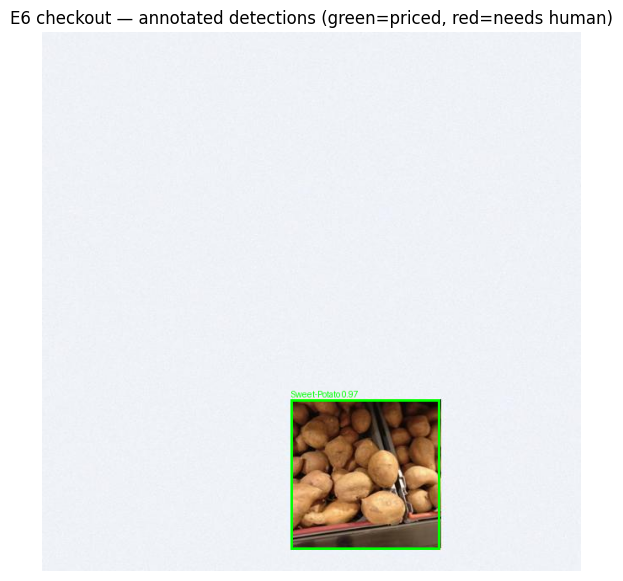

        item  qty  confidence  unit_price_sgd  discount_pct  line_total flag
Sweet-Potato    1       0.971            1.89            10         1.7     

TOTAL: SGD 1.70


In [ ]:
# 🚀 E6a) checkout(): the base recognize() upgraded with UNKNOWN handling, confidence and discounts
def softmax_np(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def knn_probs(X, index, classes, k=5, temp=20.0):
    """Turn gallery cosine similarities into a per-class probability vector (only matters when alpha < 1)."""
    P = np.zeros((len(X), len(classes)), dtype='float32')
    cls_to_i = {c: i for i, c in enumerate(classes)}
    for r, hits in enumerate(index.query(X, k=k)):
        for h_ in hits:
            if h_['fine'] in cls_to_i:
                P[r, cls_to_i[h_['fine']]] += np.exp(temp * h_['score'])
    return P / (P.sum(1, keepdims=True) + 1e-9)

ONNX_IN = sess.get_inputs()[0].name  # serving contract from the exported head

# Enriched catalog columns from E1 (fall back gracefully if E1 was skipped).
has_sgd = 'unit_price_sgd' in price_catalog.columns
price_col = 'unit_price_sgd' if has_sgd else 'unit_price'
disp_currency = 'SGD' if has_sgd else currency

def price_lookup(fine):
    row = price_catalog[price_catalog.fine == fine]
    if not len(row):
        return 1.00, 0
    r_ = row.iloc[0]
    return float(r_[price_col]), int(r_.discount_pct) if 'discount_pct' in price_catalog.columns else 0

def checkout(image, conf=None, alpha=None, thr=None):
    """PIL image or path -> detector -> ONNX head (optionally blended with kNN) -> priced, flagged receipt."""
    conf = globals().get('BEST_CONF', 0.1) if conf is None else conf        # E2: detector confidence from the sweep (manifest)
    alpha = globals().get('best_alpha', 1.0) if alpha is None else alpha    # default 1.0 = head only (not tuned)
    thr = globals().get('UNKNOWN_THR', 0.45) if thr is None else thr        # default unknown-item threshold (not tuned)
    img = (Image.open(image) if isinstance(image, (str, Path)) else image).convert('RGB')
    arr = np.array(img)
    result = det(arr, imgsz=640, conf=conf, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy()
    if len(boxes) == 0:
        boxes = np.array([[0, 0, img.width, img.height]], dtype='float32')
    items, drawn = [], []
    for x1, y1, x2, y2 in boxes:
        if x2 - x1 < 5 or y2 - y1 < 5:
            continue
        crop = Image.fromarray(arr[int(y1):int(y2), int(x1):int(x2)])
        f = feats_of_imgs([crop], model)
        p_h = softmax_np(sess.run(None, {ONNX_IN: f.astype('float32')})[0])
        p_f = p_h if alpha >= 1.0 else alpha * p_h + (1 - alpha) * knn_probs(f, idx, classes)
        k_ = int(p_f[0].argmax()); c_ = float(p_f[0].max())
        known = c_ >= thr
        name = classes[k_] if known else 'UNKNOWN'
        price, disc = price_lookup(classes[k_]) if known else (0.0, 0)
        items.append({'item': name, 'qty': 1, 'confidence': round(c_, 3),
                      f'unit_price_{disp_currency.lower()}': price, 'discount_pct': disc,
                      'line_total': round(price * (1 - disc / 100), 2),
                      'flag': '' if known else 'CHECK ITEM — low confidence'})
        drawn.append((int(x1), int(y1), int(x2), int(y2), name, c_))
    return pd.DataFrame(items), drawn, arr

def annotate(arr, drawn):
    pil = Image.fromarray(arr.copy())
    dr = ImageDraw.Draw(pil)
    for x1, y1, x2, y2, name, c_ in drawn:
        col = 'red' if name == 'UNKNOWN' else 'lime'
        dr.rectangle([x1, y1, x2, y2], outline=col, width=3)
        dr.text((x1, max(0, y1 - 12)), f'{name[:18]} {c_:.2f}', fill=col)
    return pil

# Inline demo on the Day 2 sample scene (always runs on "Run all").
import matplotlib.pyplot as plt
sample_path = Path(b.root) / 'sample_scene.jpg'
receipt, drawn, arr = checkout(sample_path)
plt.figure(figsize=(7, 7))
plt.imshow(annotate(arr, drawn)); plt.axis('off')
plt.title('E6 checkout — annotated detections (green=priced, red=needs human)'); plt.show()
print(receipt.to_string(index=False))
subtotal = float(receipt.line_total.sum()) if len(receipt) else 0.0
print(f'\nTOTAL: {disp_currency} {subtotal:.2f}')
n_unk = int((receipt.item == 'UNKNOWN').sum()) if len(receipt) else 0
if n_unk:
    print(f'⚠ {n_unk} item(s) flagged UNKNOWN — held for a human check, charged 0 (base app charged a flat 1.00).')


In [ ]:
# 🚀 E6b) Gradio checkout app — upload, edit any receipt line, totals recompute
import gradio as gr
from pathlib import Path

has_sgd = 'unit_price_sgd' in price_catalog.columns
disp_currency = 'SGD' if has_sgd else currency

def gr_scan(pil_img):
    if pil_img is None:
        return None, pd.DataFrame(), '', 'Upload a counter photo (or click an example) first.'
    receipt, drawn, arr = checkout(pil_img)
    ann = annotate(arr, drawn)
    warn = []
    if len(receipt):
        thr = globals().get('UNKNOWN_THR', 0.45)
        n_unk = int((receipt.item == 'UNKNOWN').sum())
        n_low = int(((receipt.confidence < thr + 0.1) & (receipt.item != 'UNKNOWN')).sum())
        if n_unk: warn.append(f'{n_unk} unknown item(s) need a human check (charged 0).')
        if n_low: warn.append(f'{n_low} item(s) are close to the confidence threshold.')
    total = float(receipt.line_total.sum()) if len(receipt) else 0.0
    return ann, receipt, f'{disp_currency} {total:.2f}', ' '.join(warn) or 'All items recognized confidently.'

def gr_recalc(df_):
    df_ = pd.DataFrame(df_)
    try:
        pcol = [c for c in df_.columns if c.startswith('unit_price')][0]
        for col in ['qty', pcol, 'discount_pct']:
            df_[col] = pd.to_numeric(df_[col], errors='coerce').fillna(0)
        df_['line_total'] = (df_.qty * df_[pcol] * (1 - df_.discount_pct / 100)).round(2)
        return df_, f'{disp_currency} {float(df_.line_total.sum()):.2f}'
    except Exception as e:
        return df_, f'edit error: {e}'

# Sample synthetic scenes for one-click examples (downloaded with the bundle, or created by E2 in TRAIN mode).
example_paths = ([Path(BUNDLE_DIR) / 'sample_scene.jpg'] + sorted(Path(BUNDLE_DIR).glob('hard_*.jpg'))
                 + sorted(Path('datasets/scenes_hard/images').glob('hard_00[0-2].jpg')))
example_paths = [str(p) for p in example_paths if p.exists()]

with gr.Blocks(title='SmartCart Checkout') as checkout_app:
    gr.Markdown('## 🛒 SmartCart — AI checkout assistant (proof of concept)\n'
                'Upload a counter photo (or click an example below), press **Scan basket**. '
                'Edit any receipt line (qty/price/discount) and press **Recalculate**.')
    with gr.Row():
        inp = gr.Image(type='pil', label='Counter photo')
        out_img = gr.Image(label='Detected items')
    if example_paths:
        gr.Examples(examples=[[p] for p in example_paths], inputs=inp, label='Sample synthetic scenes')
    scan_btn = gr.Button('Scan basket', variant='primary')
    rec_df = gr.Dataframe(label='Receipt (editable)', interactive=True)
    with gr.Row():
        total_box = gr.Textbox(label=f'Total ({disp_currency})')
        warn_box = gr.Textbox(label='Warnings')
    recalc_btn = gr.Button('Recalculate edited receipt')
    scan_btn.click(gr_scan, inp, [out_img, rec_df, total_box, warn_box])
    recalc_btn.click(gr_recalc, rec_df, [rec_df, total_box])

# debug=True keeps this cell running so the public share link stays up. Stop the cell to shut the app down.
checkout_app.launch(share=True, debug=True, allowed_paths=[BUNDLE_DIR])


---
# Part 7 — What we learned, what we trialed

## What we learned
1. **Artifacts beat monoliths.** Each day leaves small, typed artifacts (tables, weights, an index); Day 5 assembles them without retraining anything. When something broke, we knew exactly which artifact to inspect.
2. **Diagnosis drives improvement.** Day 3's per-class table told Day 4 exactly where to spend compute; the official lift table then measured whether we spent it well.
3. **Uncertainty is a product feature.** The single most user-visible enhancement is the unknown-item threshold — a wrong charge is worse than a flagged item. In this version the threshold is a fixed default (0.45), not yet tuned on validation data; sweeping it against coverage and accuracy is the next step.
4. **Deployment is a contract.** The ONNX export + parity check + int8 benchmark (Day 5a) showed the serving artifact is just named tensors in, named tensors out — any language can serve it.
5. **Frozen backbones are a superpower at small scale.** Every experiment retrained in seconds because images were embedded once.

## What we trialed (including what did not win)
- **cGAN synthetic data (E4b/E4c)** — trained, sampled, routed through the official `gen_df`, measured against a classical-aug-only ablation. Reported honestly either way; at ≤40 images/class, from-scratch GANs rarely beat classical augmentation.
- **Aggressive detector confidence (E2)** — near-perfect precision, unacceptable recall on hard scenes; F1-optimal point chosen instead.

